In [1]:
import os
from os.path import dirname, join, basename, exists
cwd = os.getcwd()
from time import perf_counter
from datetime import datetime
import sys
import warnings
warnings.filterwarnings('ignore')
import re
import ddeq
from pathlib import Path

import numpy as np
import xarray as xr
import pandas as pd
from scipy.stats import norm,chi2
from scipy.special import erf
from scipy.optimize import minimize,minimize_scalar,curve_fit,NonlinearConstraint,LinearConstraint,check_grad
from scipy.interpolate import NearestNDInterpolator,LinearNDInterpolator,PchipInterpolator, RBFInterpolator 
from scipy.integrate import dblquad, nquad
from scipy.linalg import solve
from sklearn.utils.extmath import fast_logdet
#from sklearn.mixture import GaussianMixture
from sklearn.metrics import r2_score

import cartopy.crs as ccrs
from netCDF4 import Dataset
import ucat
import numpy.ma as ma
from itertools import product
from shapely.geometry import Point, Polygon
from shapely.affinity import scale, rotate
from shapely import GEOSException
from cartopy.geodesic import Geodesic
Earth = Geodesic(radius=6378137.0)

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable,RdYlBu_r
from matplotlib.markers import MarkerStyle
from matplotlib.patches import Ellipse, Patch
from matplotlib import rcParamsDefault
plt.rcParams.update(rcParamsDefault)

CRS = ccrs.UTM(32)
WGS84 = ccrs.PlateCarree()

DOMAIN = ddeq.misc.Domain.from_nml(join(dirname(ddeq.__file__), 'data', 'INPUT_ORG'))

SMARTCARB_DATA_PATH = join(cwd, 'SMARTCARB')
SMARTCARB_FILES = [join('SMARTCARB',file) for file in os.listdir(SMARTCARB_DATA_PATH) 
                   if file.endswith('.nc')]
WIND_DATA_PATH = join(cwd, 'SMARTCARB_winds')

In [2]:
# Function to compute a dicrete integral (Riemann sum)
def discrete_integral(measures,data,cov_mat):
    # Measures = lengths, areas, volumes etc. of each value in data
    if not isinstance(measures,np.ndarray):
        measures = np.array(measures)
    if cov_mat.shape != (len(data),len(data)):
        raise ValueError(f'Invalid cov shape {cov_mat.shape} with {len(data)} number of data points')
    elif np.any(np.isnan(data)):
        raise ValueError('NaN values present in the data')
    elif np.any(np.isnan(cov_mat)):
        raise ValueError('NaN values present in the covariance matrix')
    # Discrete integral
    I = np.nansum(measures*data)
    I_std = np.sqrt(np.nansum((measures[:,np.newaxis] * measures[np.newaxis,:]) * cov_mat))
    return I,I_std

def continuous_integral_over_ellipse(func,center,sx,sy,alpha,cov_func=None,epsrel=0.1):
    if sx > sy:
        F = np.sqrt(sx**2-sy**2)
        jac_det = lambda mu,nu: F**2*((np.sinh(mu)*np.cos(nu))**2+(np.cosh(mu)*np.sin(nu))**2)
        integrand = lambda mu,nu: jac_det(mu,nu)*func(*np.add(center,(F*(np.cosh(mu)*np.cos(nu)*np.cos(alpha)+np.sinh(mu)*np.sin(nu)*np.sin(alpha)),
                                                                      F*(-np.cosh(mu)*np.cos(nu)*np.sin(alpha)+np.sinh(mu)*np.sin(nu)*np.cos(alpha)))))
        if cov_func is not None:
            cov_integrand = lambda mu1,nu1,mu2,nu2: jac_det(mu1,nu1)*jac_det(mu2,nu2)*cov_func(np.add(center,(F*(np.cosh(mu1)*np.cos(nu1)*np.cos(alpha)+np.sinh(mu1)*np.sin(nu1)*np.sin(alpha)),
                                                                                                              F*(-np.cosh(mu1)*np.cos(nu1)*np.sin(alpha)+np.sinh(mu1)*np.sin(nu1)*np.cos(alpha)))),
                                                                                               np.add(center,(F*(np.cosh(mu2)*np.cos(nu2)*np.cos(alpha)+np.sinh(mu2)*np.sin(nu2)*np.sin(alpha)),
                                                                                                              F*(-np.cosh(mu2)*np.cos(nu2)*np.sin(alpha)+np.sinh(mu2)*np.sin(nu2)*np.cos(alpha)))))
        mu_min, mu_max = 0.0, np.log((sx+sy) / np.sqrt(sx**2-sy**2))
        nu_min, nu_max = 0.0, 2*np.pi
    elif sy > sx:
        F = np.sqrt(sy**2-sx**2)                                       
        jac_det = lambda mu,nu: F**2*((np.sinh(mu)*np.cos(nu))**2+(np.cosh(mu)*np.sin(nu))**2)
        integrand = lambda mu,nu: jac_det(mu,nu)*func(*np.add(center,(F*(np.cosh(mu)*np.cos(nu)*np.sin(alpha)+np.sinh(mu)*np.sin(nu)*np.cos(alpha)),
                                                                      F*(np.cosh(mu)*np.cos(nu)*np.cos(alpha)-np.sinh(mu)*np.sin(nu)*np.sin(alpha)))))
        if cov_func is not None:
            cov_integrand = lambda mu1,nu1,mu2,nu2: jac_det(mu1,nu1)*jac_det(mu2,nu2)*cov_func(np.add(center,(F*(np.cosh(mu1)*np.cos(nu1)*np.sin(alpha)+np.sinh(mu1)*np.sin(nu1)*np.cos(alpha)),
                                                                                                              F*(np.cosh(mu1)*np.cos(nu1)*np.cos(alpha)-np.sinh(mu1)*np.sin(nu1)*np.sin(alpha)))),
                                                                                               np.add(center,(F*(np.cosh(mu2)*np.cos(nu2)*np.sin(alpha)+np.sinh(mu2)*np.sin(nu2)*np.cos(alpha)),
                                                                                                              F*(np.cosh(mu2)*np.cos(nu2)*np.cos(alpha)-np.sinh(mu2)*np.sin(nu2)*np.sin(alpha)))))
        mu_min, mu_max = 0.0, np.log((sy+sx) / np.sqrt(sy**2-sx**2))
        nu_min, nu_max = 0.0, 2*np.pi
    else:
        # When sy == sx, coordinate system is equivalent to the polar coordinate system
        R = 0.5*(sx+sy)
        jac_det = lambda mu,nu: mu
        integrand = lambda mu,nu: jac_det(mu,nu)*func(*np.add(center,(R*np.cos(nu),R*np.sin(nu))))
        if cov_func is not None:
            cov_integrand = lambda mu1,nu1,mu2,nu2: jac_det(mu1,nu1)*jac_det(mu2,nu2)*cov_func(np.add(center,(R*np.cos(nu1),R*np.sin(nu1))),
                                                                                               np.add(center,(R*np.cos(nu2),R*np.sin(nu2))))
        mu_min, mu_max = 0.0, R
        nu_min, nu_max = 0.0, 2*np.pi
    
    I,I_err = nquad(integrand,[[mu_min,mu_max],[nu_min,nu_max]],
                    opts={'epsrel': epsrel})
    if cov_func is None:
        return I
    else:
        # Double area integral of the covariance
        I_var = nquad(cov_integrand,[[mu_min,mu_max],[nu_min,nu_max],[mu_min,mu_max],[nu_min,nu_max]],
                      opts={'epsrel':0.5})[0]
        return I, np.sqrt(I_var+I_err**2)

# Divides each pixel to four smaller pixels and repeats the process number of times specified by repeats
def divide_grid_cells(X,Y,repeats=1,return_centers=False):
    if X.ndim == 3 and Y.ndim == 3:
        X, Y = X.reshape((-1,4)), Y.reshape((-1,4))
    # Order points to order (bottom-left, bottom-right, top-right, top-left)
    direct_sum = (X-X.mean(axis=1,keepdims=True)) + (Y-Y.mean(axis=1,keepdims=True))
    # Minimum value of the direct sum is the bottom-left corner, maximum value is the top-right corner
    bottom_left_indices = direct_sum.argmin(axis=1)
    range_index = np.arange(len(direct_sum),dtype=np.uint32)
    X_out = X[(range_index,bottom_left_indices)][:,np.newaxis]
    Y_out = Y[(range_index,bottom_left_indices)][:,np.newaxis]
    top_right_indices = direct_sum.argmax(axis=1)
    indices = np.ravel_multi_index((np.repeat(range_index,2),
                                    np.column_stack((bottom_left_indices,top_right_indices)).flatten()),
                                    direct_sum.shape)
    X_temp = np.delete(X.flatten(),indices).reshape((len(direct_sum),2)) 
    Y_temp = np.delete(Y.flatten(),indices).reshape((len(direct_sum),2)) 
    bottom_right_indices = X_temp.argmax(axis=1)
    top_left_indices = X_temp.argmin(axis=1)
    X_out = np.concatenate((X_out,X_temp[(range_index,bottom_right_indices)][:,np.newaxis]),axis=1)
    Y_out = np.concatenate((Y_out,Y_temp[(range_index,bottom_right_indices)][:,np.newaxis]),axis=1)
    X_out = np.concatenate((X_out,X[(range_index,top_right_indices)][:,np.newaxis]),axis=1)
    Y_out = np.concatenate((Y_out,Y[(range_index,top_right_indices)][:,np.newaxis]),axis=1)
    X_out = np.concatenate((X_out,X_temp[(range_index,top_left_indices)][:,np.newaxis]),axis=1)
    Y_out = np.concatenate((Y_out,Y_temp[(range_index,top_left_indices)][:,np.newaxis]),axis=1)
    X,Y = X_out,Y_out
    for _ in range(repeats):
        X_mean, Y_mean = X.mean(axis=1), Y.mean(axis=1) 
        X = np.vstack((np.column_stack((X[:,0],0.5*(X[:,0]+X[:,1]),X_mean,0.5*(X[:,0]+X[:,3]))),
                       np.column_stack((0.5*(X[:,0]+X[:,1]),X[:,1],0.5*(X[:,1]+X[:,2]),X_mean)),
                       np.column_stack((X_mean,0.5*(X[:,1]+X[:,2]),X[:,2],0.5*(X[:,2]+X[:,3]))),
                       np.column_stack((0.5*(X[:,0]+X[:,3]),X_mean,0.5*(X[:,2]+X[:,3]),X[:,3]))))
        Y = np.vstack((np.column_stack((Y[:,0],0.5*(Y[:,0]+Y[:,1]),Y_mean,0.5*(Y[:,0]+Y[:,3]))),
                       np.column_stack((0.5*(Y[:,0]+Y[:,1]),Y[:,1],0.5*(Y[:,1]+Y[:,2]),Y_mean)),
                       np.column_stack((Y_mean,0.5*(Y[:,1]+Y[:,2]),Y[:,2],0.5*(Y[:,2]+Y[:,3]))),
                       np.column_stack((0.5*(Y[:,0]+Y[:,3]),Y_mean,0.5*(Y[:,2]+Y[:,3]),Y[:,3]))))
    return (X.mean(axis=1),Y.mean(axis=1)) if return_centers else (X,Y) 

In [3]:
sources = ddeq.misc.read_point_sources()
remove_sources = ['Berlin','Belchatow','Lipetsk','Matimba','Paris','Hamburg','Prague']
bool_array = [source not in remove_sources for source in sources['source'].data]
sources = sources.where(xr.DataArray(bool_array, dims='source'), drop=True)
#sources

In [4]:
def get_true_emission_by_images(images):
    CO2_emission_df = pd.read_csv(f'{cwd}/src/ddeq/data/SMARTCARB-CO2-emissions.csv',sep='\t',index_col=0)
    CO2_emission_df.rename(columns=lambda s: re.sub(' +',' ',re.sub(r"\(.*?\)"," ",s)).strip(), inplace=True)
    #emission_df.drop(columns=['Belchatow (Mt/yr)','Hamburg (Mt/yr)','Staudinger (Mt/yr)'],inplace=True)
    true_CO2_emission_xr = xr.DataArray(np.full((len(sources['source'].data),len(images)),np.nan),dims=['sources','images'],
                                        coords=dict(sources=sources['source'].data,images=images),
                                        attrs={'Description': 'True Emissions by image'})
    for image in true_CO2_emission_xr['images'].data:
        datetime_str = image.split('_')[3]
        datetime = pd.to_datetime(datetime_str,format='%Y%m%d%H')
        true_CO2_emission_xr.loc[dict(images=image)] = CO2_emission_df.loc[str(datetime),sources['source'].data].values
    return true_CO2_emission_xr

In [5]:
l2 = ddeq.smartcarb.Level2Dataset(SMARTCARB_DATA_PATH,'ace',
                                  co2_noise_scenario='medium',
                                  no2_noise_scenario='high',
                                  make_no2_error_cloud_dependent=False,
                                  co2_cloud_threshold=1.0,
                                  no2_cloud_threshold=1.0)

In [6]:
days = pd.date_range("2015-01-01","2015-12-24")
images = np.concatenate(tuple(list(map(lambda s: basename(s).split('.')[0],
                                       ddeq.smartcarb.Level2Dataset(SMARTCARB_DATA_PATH,'ace').get_filenames(day))) 
                              for day in days))
true_CO2_emission_xr = get_true_emission_by_images(images)

In [7]:
def read_date(date):
    return [
            ddeq.smartcarb.read_level2(
                filename,
                co2_noise_scenario=l2.co2_noise_scenario,
                co2_cloud_threshold=l2.co2_cloud_threshold,
                no2_noise_scenario=l2.no2_noise_scenario,
                no2_cloud_threshold=l2.no2_cloud_threshold,
                make_no2_error_cloud_dependent=l2.make_no2_error_cloud_dependent,
                use_constant=False,
                seed="orbit",
                only_observations=False,
                add_background=True,
            )
            for filename in l2.get_filenames(date,tmin=10,tmax=11)
        ]
    
def get_datetime_str(np_timestamp,fancy_str=False,split=False):
    year = np_timestamp.astype('datetime64[Y]').astype(int) + 1970
    month = np_timestamp.astype('datetime64[M]').astype(int) % 12 + 1
    day = (np_timestamp.astype('datetime64[D]') - np_timestamp.astype('datetime64[M]')).astype(int) + 1
    seconds_since_epoch = np_timestamp.astype('datetime64[s]').astype(int) - np_timestamp.astype('datetime64[D]').astype(int)*24*3600
    hour = (seconds_since_epoch - seconds_since_epoch % 3600) // 3600
    minute = (seconds_since_epoch - hour*3600 - (seconds_since_epoch - hour*3600) % 60) // 60
    second = seconds_since_epoch - hour*3600 - 60*minute
    year_str = str(year)
    month_str = f'0{month}' if month <= 9 else str(month)
    day_str = f'0{day}' if day <= 9 else str(day)
    hour_str = f'0{hour}' if hour <= 9 else str(hour)
    minute_str = f'0{minute}' if minute <= 9 else str(minute)
    second_str = f'0{second}' if second <= 9 else str(second)
    if fancy_str:
        if day % 10 == 1:
            day_str = f'{day}st'
        elif day % 10 == 2:
            day_str = f'{day}nd'
        elif day % 10 == 3:
            day_str = f'{day}rd'
        else:
            day_str = f'{day}th'
        months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
        date_str = f'{months[month-1]} {day_str} {year_str}'
        time_str = f'{hour_str}:{minute_str}:{second_str} UTC'
    else:
        date_str, time_str = f'{year_str}{month_str}{day_str}', f'{hour_str}{minute_str}{second_str}'
    if split:
        return date_str, time_str
    else:
        return f'{date_str} {time_str}' if fancy_str else f'{date_str}T{time_str}'

def get_overpass_str(overpass):
    datetime_str = get_datetime_str(overpass['time'].data)
    if overpass.lon_eq == 0:
        lon_eq_str = '0000'
    elif overpass.lon_eq < 1000:
        lon_eq_str = f'0{overpass.lon_eq}'
    else:
        lon_eq_str = str(overpass.lon_eq)
    if overpass.orbit == 0:
        o_str = '0000'
    elif overpass.orbit < 10:
        o_str = f'000{overpass.orbit}'
    elif overpass.orbit < 100:
        o_str = f'00{overpass.orbit}'
    elif overpass.orbit < 1000:
        o_str = f'0{overpass.orbit}'
    else:
        o_str = str(overpass.orbit)
    return f'{datetime_str}_o{o_str}_l{lon_eq_str}'

In [8]:
def compute_along_track(overpass,return_interpolator=False):
    if overpass.dims['nobs'] == 0:
        if return_interpolator:
            return lambda lon: np.full(lon.shape,np.nan)
        else:
            return np.column_stack((np.full(overpass.dims['nobs'],np.nan),np.full(overpass.dims['nobs'],np.nan)))
    center_lon = overpass['lon'].mean(dim='nrows').data[::-1]
    center_lat = overpass['lat'].mean(dim='nrows').data[::-1]
    lat_interpolator = PchipInterpolator(center_lon,center_lat)
    if return_interpolator:
        return lat_interpolator
    else:
        return np.column_stack((center_lon[::-1],lat_interpolator(center_lon)[::-1]))

def remove_nan_lines(overpass,based_on='CO2'):
    variables_without_dim = [variable for variable in overpass.variables if overpass[variable].ndim == 0]
    temp = overpass.drop_vars(variables_without_dim)
    non_nan_xr = ~np.isnan(overpass[based_on])
    bool_xr = non_nan_xr.any(dim='nrows')
    indices = np.where(bool_xr.data)[0]
    if len(indices) != 0:
        first_true_index, last_true_index = indices[0], indices[-1]
        bool_xr[first_true_index:(last_true_index+1)] = True
        temp = temp.where(bool_xr,drop=True)
    else:
        temp = temp.where(bool_xr,drop=True)
    for variable in variables_without_dim:
        temp[variable] = overpass[variable]
    return temp

def include_cross_along_for_overpass(overpass):
    if overpass.dims['nobs'] == 0:
        print('No overpass lines in the file')
        return overpass
    along_track_coords = compute_along_track(overpass)
    along_track = Earth.inverse(along_track_coords[:-1],along_track_coords[1:])
    y = 1e-3*along_track[:,0]
    along_track_dists = np.append([0.0],np.cumsum(y))
    along_track_bearings = np.append(along_track[:,1],along_track[-1,2])
    along_track_bearings[along_track_bearings < 0.0] += 360.0
    lonc, latc = overpass['lonc'].data, overpass['latc'].data
    shape = (overpass.dims['nobs'],overpass.dims['nrows'])
    cross_coords_xr = xr.DataArray(data=np.full(shape,np.nan,dtype=np.float32),
                                   dims=['nobs','nrows'],attrs={'units': 'km'})
    along_coords_xr = xr.DataArray(data=np.full(shape,np.nan,dtype=np.float32),
                                   dims=['nobs','nrows'],attrs={'units': 'km'})
    cross_corners_xr = xr.DataArray(data=np.full(shape+(overpass.dims['ncorners'],),np.nan,dtype=np.float32),
                                    dims=['nobs','nrows','ncorners'],attrs={'units': 'km'})
    along_corners_xr = xr.DataArray(data=np.full(shape+(overpass.dims['ncorners'],),np.nan,dtype=np.float32),
                                    dims=['nobs','nrows','ncorners'],attrs={'units': 'km'})
    for nobs in range(overpass.dims['nobs']):
        cross_track_coords = np.column_stack((overpass['lon'][nobs,:].data,overpass['lat'][nobs,:].data))
        # Find the index of the closest point ot the center line
        idx = np.argmin(np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords))[:,0])
        # Calculate bearings to cross-track directions from the center line
        west_bearing = np.asarray(Earth.inverse(cross_track_coords[1:(idx+1)][::-1],cross_track_coords[0:idx][::-1]))[:,1]
        west_bearing[west_bearing < 0.0] += 360.0
        east_bearing = np.asarray(Earth.inverse(cross_track_coords[idx:-1],cross_track_coords[(idx+1):]))[:,1]
        east_bearing[east_bearing < 0.0] += 360.0
        # Calculate angles of cross-track directions measured from the along-track direction (clockwise direction as positive)
        west_angle = west_bearing - along_track_bearings[nobs]
        west_angle[west_angle > 180.0] -= 360.0
        west_angle[west_angle < -180.0] += 360.0
        west_angle_mean = west_angle.mean()
        east_angle = east_bearing - along_track_bearings[nobs]
        east_angle[east_angle > 180.0] -= 360.0
        east_angle[east_angle < -180.0] += 360.0
        east_angle_mean = east_angle.mean()

        nearest_bearing = Earth.inverse(along_track_coords[nobs],cross_track_coords[idx])[0,1]
        nearest_bearing += 360.0 if nearest_bearing < 0.0 else 0.0
        nearest_angle = nearest_bearing - along_track_bearings[nobs]
        if nearest_angle > 180.0:
            nearest_angle -= 360.0
        elif nearest_angle < -180.0:
            nearest_angle += 360.0
        # Equivalent to satelite heading towards north and positive x direction (roughly) towards east
        if west_angle_mean < 0.0 and east_angle_mean > 0.0:
            # Equivalent to the closest point in cross-track coordinates being west from along-track center line
            if abs(nearest_angle-west_angle_mean) < abs(nearest_angle-east_angle_mean):
                nearest_dist_pos = 1e-3*np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx+1]))[0,0]
                nearest_dist_neg = -1e-3*np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[0,0]
                pos_dists = 1e-3*np.asarray(Earth.inverse(cross_track_coords[(idx+1):-1],cross_track_coords[(idx+2):]))[:,0]
                neg_dists = -1e-3*np.asarray(Earth.inverse(cross_track_coords[1:(idx+1)][::-1],cross_track_coords[0:idx][::-1]))[:,0]
                dists = np.concatenate((np.cumsum(np.append(nearest_dist_neg,neg_dists))[::-1],
                                        np.cumsum(np.append(nearest_dist_pos,pos_dists))))
            # Equivalent to the closest point in cross-track coordinates being east from along-track center line
            else:
                nearest_dist_pos = 1e-3*Earth.inverse(along_track_coords[nobs],cross_track_coords[idx])[0,0]
                nearest_dist_neg = -1e-3*Earth.inverse(along_track_coords[nobs],cross_track_coords[idx-1])[0,0]
                pos_dists = 1e-3*Earth.inverse(cross_track_coords[idx:-1],cross_track_coords[(idx+1):])[:,0]
                neg_dists = -1e-3*Earth.inverse(cross_track_coords[1:idx][::-1],cross_track_coords[0:(idx-1)][::-1])[:,0]
                dists = np.concatenate((np.cumsum(np.append(nearest_dist_neg,neg_dists))[::-1],
                                        np.cumsum(np.append(nearest_dist_pos,pos_dists))))
        # Equivalent to satellite heading towards south and positive x direction (roughly) towards west
        elif west_angle_mean > 0.0 and east_angle_mean < 0.0:
            # Equivalent to the closest point in cross-track coordinates being west from along-track center line
            if abs(nearest_angle-west_angle_mean) < abs(nearest_angle-east_angle_mean):
                nearest_dist_pos = 1e-3*Earth.inverse(along_track_coords[nobs],cross_track_coords[idx])[0,0]
                nearest_dist_neg = -1e-3*Earth.inverse(along_track_coords[nobs],cross_track_coords[idx+1])[0,0]
                pos_dists = 1e-3*Earth.inverse(cross_track_coords[1:idx][::-1],cross_track_coords[0:(idx-1)][::-1])[:,0]
                neg_dists = -1e-3*Earth.inverse(cross_track_coords[idx:-1],cross_track_coords[(idx+1):])[:,0]
                dists = np.concatenate((np.cumsum(np.append(nearest_dist_pos,pos_dists))[::-1],
                                        np.cumsum(np.append(nearest_dist_neg,neg_dists))))
            # Equivalent to the closest point in cross-track coordinates being east from along-track center line
            else:
                nearest_dist_pos = 1e-3*np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx-1]))[0,0]
                nearest_dist_neg = -1e-3*np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[0,0]
                pos_dists = 1e-3*np.asarray(Earth.inverse(cross_track_coords[1:(idx+1)][::-1],cross_track_coords[0:idx][::-1]))[:,0]
                neg_dists = -1e-3*np.asarray(Earth.inverse(cross_track_coords[(idx+1):-1],cross_track_coords[(idx+2):]))[:,0]
                dists = np.concatenate((np.cumsum(np.append(nearest_dist_pos,pos_dists))[::-1],
                                        np.cumsum(np.append(nearest_dist_neg,neg_dists))))
        # Problem occured, possible due to being too close to the north or south pole
        else:
            raise ValueError('Unable to determine cross-track directions')
        lon_corners, lat_corners = lonc[nobs,:,:], latc[nobs,:,:]
        north_sides = np.column_stack((0.5*(lon_corners[:,0] + lon_corners[:,1]),
                                       0.5*(lat_corners[:,0] + lat_corners[:,1])))
        east_sides = np.column_stack((0.5*(lon_corners[:,1] + lon_corners[:,2]),
                                      0.5*(lat_corners[:,1] + lat_corners[:,2])))
        south_sides = np.column_stack((0.5*(lon_corners[:,2] + lon_corners[:,3]),
                                       0.5*(lat_corners[:,2] + lat_corners[:,3])))
        west_sides = np.column_stack((0.5*(lon_corners[:,0] + lon_corners[:,3]),
                                      0.5*(lat_corners[:,0] + lat_corners[:,3])))
        cross_coords_xr.loc[dict(nobs=nobs)] = dists
        along_coords_xr.loc[dict(nobs=nobs)] = np.repeat(along_track_dists[nobs],overpass.dims['nrows'])
        cross_corners_xr.loc[dict(nobs=nobs,ncorners=0)] = dists + 1e-3*Earth.inverse(cross_track_coords,west_sides)[:,0]
        cross_corners_xr.loc[dict(nobs=nobs,ncorners=1)] = dists - 1e-3*Earth.inverse(cross_track_coords,east_sides)[:,0]
        cross_corners_xr.loc[dict(nobs=nobs,ncorners=2)] = dists - 1e-3*Earth.inverse(cross_track_coords,east_sides)[:,0]
        cross_corners_xr.loc[dict(nobs=nobs,ncorners=3)] = dists + 1e-3*Earth.inverse(cross_track_coords,west_sides)[:,0]
        north_dists = 1e-3*np.asarray(Earth.inverse(cross_track_coords,north_sides))[:,0]
        south_dists = 1e-3*np.asarray(Earth.inverse(cross_track_coords,south_sides))[:,0]
        along_corners_xr.loc[dict(nobs=nobs,ncorners=0)] = along_track_dists[nobs] - north_dists
        along_corners_xr.loc[dict(nobs=nobs,ncorners=1)] = along_track_dists[nobs] - north_dists
        along_corners_xr.loc[dict(nobs=nobs,ncorners=2)] = along_track_dists[nobs] + south_dists
        along_corners_xr.loc[dict(nobs=nobs,ncorners=3)] = along_track_dists[nobs] + south_dists
    overpass['cross_track'] = cross_coords_xr
    overpass['along_track'] = along_coords_xr
    overpass['cross_track_corners'] = cross_corners_xr
    overpass['along_track_corners'] = along_corners_xr
    return overpass

def slice_lat(overpass,min_lat=None,max_lat=None):
    if min_lat is not None and max_lat is None:
        bool_xr = min_lat < overpass['lat'][:,0]
    elif min_lat is None and max_lat is not None:
        bool_xr = overpass['lat'][:,0] < max_lat
    elif min_lat is not None and max_lat is not None:
        bool_xr = (min_lat < overpass['lat'][:,0]) & (overpass['lat'][:,0] < max_lat)
    else:
        return overpass
    variables = [variable for variable in overpass.variables if overpass[variable].ndim == 0]
    temp = overpass.drop_vars(variables)
    temp = temp.where(bool_xr,drop=True)
    for variable in variables:
        temp[variable] = overpass[variable]
    return temp

def slice_wind(wind_ds,overpass):
    wlon, wlat = wind_ds['lon'].data, wind_ds['lat'].data
    overpass_lon, overpass_lat = overpass['lon'].data, overpass['lat'].data
    # Check first if some of the overpass coordinates are outside the wind field and take them out
    wind_upper_coords = np.column_stack((wlon[-1,:],wlat[-1,:]))
    wind_lower_coords = np.column_stack((wlon[0,:],wlat[0,:]))
    nobs_lower_setted = False
    for r in range(1,overpass.dims['nobs']):
        obs_coords = np.column_stack((overpass_lon[r,:],overpass_lat[r,:]))
        max_lat_coord = obs_coords[np.argmax(obs_coords[:,1])]
        min_dist_ind = np.argmin(np.asarray(Earth.inverse(wind_upper_coords,max_lat_coord))[:,0])
        if max_lat_coord[1] < wind_upper_coords[min_dist_ind,1]:
            nobs_lower = overpass['nobs'].data[r-1]
            nobs_lower_setted = True
            break
    if not nobs_lower_setted:
        nobs_lower = overpass['nobs'].data.min()
    nobs_upper_setted = False
    for r in range(overpass.dims['nobs']-2,-1,-1):
        obs_coords = np.column_stack((overpass_lon[r,:],overpass_lat[r,:]))
        min_lat_coord = obs_coords[np.argmin(obs_coords[:,1])]
        min_dist_ind = np.argmin(np.asarray(Earth.inverse(wind_lower_coords,min_lat_coord))[:,0])
        if min_lat_coord[1] > wind_lower_coords[min_dist_ind,1]:
            nobs_upper = overpass['nobs'].data[r+1]
            nobs_upper_setted = True
            break
    if not nobs_upper_setted:
        nobs_upper = overpass['nobs'].data.max()
    variables = [variable for variable in overpass.variables if overpass[variable].ndim == 0]
    overpass_sliced = overpass.drop_vars(variables)
    bool_xr = (nobs_lower <= overpass['nobs']) & (overpass['nobs'] <= nobs_upper)
    overpass_sliced = overpass_sliced.where(bool_xr, drop=True)
    for variable in variables:
        overpass_sliced[variable] = overpass[variable]
    #overpass_lon, overpass_lat = overpass['lon'].data, overpass['lat'].data
    # Slice out all extra wind field coordinates
    shape = (overpass_sliced.dims['nobs'],overpass_sliced.dims['nrows'])
    max_lat_index = np.unravel_index(np.argmax(overpass_sliced['lat'].data),shape)
    min_lat_index = np.unravel_index(np.argmin(overpass_sliced['lat'].data),shape)
    max_lon_index = np.unravel_index(np.argmax(overpass_sliced['lon'].data),shape)
    min_lon_index = np.unravel_index(np.argmin(overpass_sliced['lon'].data),shape)
    overpass_sliced_lon, overpass_sliced_lat = overpass_sliced['lon'].data, overpass_sliced['lat'].data
    max_lat_coord = (overpass_sliced_lon[max_lat_index],overpass_sliced_lat[max_lat_index])
    min_lat_coord = (overpass_sliced_lon[min_lat_index],overpass_sliced_lat[min_lat_index])
    max_lon_coord = (overpass_sliced_lon[max_lon_index],overpass_sliced_lat[max_lon_index])
    min_lon_coord = (overpass_sliced_lon[min_lon_index],overpass_sliced_lat[min_lon_index])
    for c in range(1,wind_ds.dims['rlon']):
        min_dist_ind = np.argmin(np.asarray(Earth.inverse(np.column_stack((wlon[:,c],wlat[:,c])),min_lon_coord))[:,0])
        if wlon[min_dist_ind,c] > min_lon_coord[0]:
            lon_lower = wind_ds['rlon'].data[c-1]
            break
    for c in range(wind_ds.dims['rlon']-2,-1,-1):
        min_dist_ind = np.argmin(np.asarray(Earth.inverse(np.column_stack((wlon[:,c],wlat[:,c])),max_lon_coord))[:,0])
        if wlon[min_dist_ind,c] < max_lon_coord[0]:
            lon_upper = wind_ds['rlon'].data[c+1]
            break
    for r in range(1,wind_ds.dims['rlat']):
        min_dist_ind = np.argmin(np.asarray(Earth.inverse(np.column_stack((wlon[r,:],wlat[r,:])),min_lat_coord))[:,0])
        if wlat[r,min_dist_ind] > min_lat_coord[1]:
            lat_lower = wind_ds['rlat'].data[r-1]
            break
    for r in range(wind_ds.dims['rlat']-2,-1,-1):
        min_dist_ind = np.argmin(np.asarray(Earth.inverse(np.column_stack((wlon[r,:],wlat[r,:])),max_lat_coord))[:,0])
        if wlat[r,min_dist_ind] < max_lat_coord[1]:
            lat_upper = wind_ds['rlat'].data[r+1]
            break 
    bool_xarray = (lat_lower < wind_ds['rlat']) & (wind_ds['rlat'] < lat_upper) & \
                  (lon_lower < wind_ds['rlon']) & (wind_ds['rlon'] < lon_upper)
    return wind_ds.where(bool_xarray,drop=True), overpass_sliced

In [18]:
def plot_overpasses(overpass,vmin=None,vmax=None,s=1.0,sources=None,center_line=False,
                    variables=['CO2_noisefree','CO2'],cbar_based_on='CO2',orient=True,
                    scaling=(1.0,1.0),plot_edges=True,cmap="RdYlBu_r",title='default',
                    image_format='png',save=False):
    if overpass.dims['nobs'] <= 1:
        raise ValueError('No observation lines to plot')
    elif len(variables) == 1:
        cbar_based_on = variables[0]
    elif len(variables) >= 2 and cbar_based_on not in variables:
        raise ValueError(f'Variable {cbar_based_on} not found in variables')
        
    if len(variables) == 1:
        figsize = (8,9)
        fontsize = 14
    elif len(variables) == 2:
        figsize = (16,9)
        fontsize = 18
    elif len(variables) == 3:
        figsize = (24,9)
        fontsize = 22
    else:
        raise ValueError('Too many variables')
    
    data_for_cbar = overpass[cbar_based_on].data
    cbar_data_mean, cbar_data_std = np.nanmean(data_for_cbar), np.nanstd(data_for_cbar,ddof=1)
    if vmin is None:
        vmin = cbar_data_mean - 1.96*cbar_data_std
    if vmax is None:
        vmax = cbar_data_mean + 1.96*cbar_data_std
    
    fig, axs = plt.subplots(nrows=1,ncols=len(variables),figsize=figsize,layout='compressed')
    for i in range(len(variables)):
        variable = variables[i]
        ax = axs[i] if len(variables) >= 2 else axs
        data_xr = overpass[variable]
        if 'units' in data_xr.attrs.keys():
             unit = data_xr.units
        else: 
             unit = 'nf' 
        data_arr = data_xr.data
        #data_min, data_max = np.nanmin(data_arr), np.nanmax(data_arr)
        along_track_coords = compute_along_track(overpass)
        overpass_lon, overpass_lat = overpass['lon'].data, overpass['lat'].data
        if orient:
            nobs, nrows = overpass.dims['nobs'], overpass.dims['nrows']
            orientation_angles = np.zeros(nobs)
            first_vec = along_track_coords[1] - along_track_coords[0]
            first_angle = np.arctan2(first_vec[1],first_vec[0])
            orientation_angles[0] = first_angle
            vecs = along_track_coords[2:] - along_track_coords[:-2]
            angles = np.arctan2(vecs[:,1],vecs[:,0])
            orientation_angles[1:-1] = angles
            final_vec = along_track_coords[-1] - along_track_coords[-2]
            final_angle = np.arctan2(final_vec[1],final_vec[0])
            orientation_angles[-1] = final_angle
            orientation_angles = orientation_angles % np.pi
            for obs_ind in range(nobs):
                if isinstance(scaling,bool):
                    sx,sy = (1.0,1.0/np.cos(np.deg2rad(along_track_coords[obs_ind,:].mean()))) if scaling else (1.0,1.0)
                    sx,sy = sx/len(variables), sy/len(variables)
                elif scaling is None:
                    sx,sy = 1.0,1.0
                elif isinstance(scaling,tuple):
                    sx,sy = scaling
                else:
                    raise ValueError(f'Invalid scaling {scaling}')
                #marker = MarkerStyle('s')#.scaled(sx,sy)
                #marker._transform.rotate_deg(orientation_angles[obs_ind])
                custom_marker = [(-sx*0.5,sx*0.5,sx*0.5,-sx*0.5), (-sy*0.5,-sy*0.5,sy*0.5,sy*0.5)]
                R = np.array([[np.cos(orientation_angles[obs_ind]),-np.sin(orientation_angles[obs_ind])],
                              [np.sin(orientation_angles[obs_ind]), np.cos(orientation_angles[obs_ind])]])
                rotated_custom_marker = np.transpose(np.matmul(R,custom_marker))
                scatter = ax.scatter(overpass_lon[obs_ind],overpass_lat[obs_ind],c=data_arr[obs_ind],
                                     vmin=vmin,vmax=vmax,cmap=cmap,marker=rotated_custom_marker,s=s)
        else:
            scatter = ax.scatter(overpass_lon.flatten(),overpass_lat.flatten(),c=data_arr.flatten(),
                                 vmin=vmin,vmax=vmax,cmap=cmap,marker=marker,s=s)
            
        lon_min, lon_max = overpass_lon.min(), overpass_lon.max()
        lat_min, lat_max = overpass_lat.min(), overpass_lat.max()
        ax.set_xlim(lon_min-0.05*(lon_max-lon_min),lon_max+0.05*(lon_max-lon_min))
        ax.set_ylim(lat_min-0.02*(lat_max-lat_min),lat_max+0.02*(lat_max-lat_min))
        
        #cbar = plt.colorbar(mappable=scatter,ax=ax)
        #cbar.ax.set_title(unit)
        if variable == cbar_based_on:
            cbar = fig.colorbar(scatter, ax=axs, orientation='horizontal')
            cbar.ax.tick_params(labelsize=fontsize-2)
            cbar.ax.set_title(unit,fontsize=fontsize) 
        if plot_edges:
            ax.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
                    linestyle='-',color='black',linewidth=0.5)
            ax.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
                    linestyle='-',color='black',linewidth=0.5)
            ax.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
                    linestyle='-',color='black',linewidth=0.5)
            ax.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
                    linestyle='-',color='black',linewidth=0.5)
        if center_line:
            ax.plot(along_track_coords[:,0],along_track_coords[:,1],color='black',linestyle='--')
        if sources is not None:
            source_names = sources['source'].data
            sources_lon = sources['lon_o'].data
            sources_lat = sources['lat_o'].data
            overpass_coords = np.column_stack((overpass_lon.flatten(),overpass_lat.flatten()))
            for n in range(len(source_names)):
                source_coord = (sources_lon[n],sources_lat[n])
                if np.min(np.asarray(Earth.inverse(overpass_coords,source_coord))[:,0]) < 2000:
                    ax.scatter(*source_coord,s=15*len(variables),color='black',marker='.')
                    if source_names[n] == 'Boxberg':
                        horizontalalignment, verticalalignment = 'left', 'top'
                    elif source_names[n] == 'Pocerady':
                        horizontalalignment, verticalalignment = 'left', 'top'
                    elif source_names[n] == 'Prunerov':
                        horizontalalignment, verticalalignment = 'center', 'bottom'
                    elif source_names[n] == 'Lippendorf':
                        horizontalalignment, verticalalignment = 'right', 'top'
                    elif source_names[n] == 'Turow':
                        horizontalalignment, verticalalignment = 'left', 'center'
                    else:
                        horizontalalignment, verticalalignment = 'left', 'bottom'
                    ax.annotate(source_names[n],source_coord,fontsize=fontsize-2*len(variables),
                                horizontalalignment=horizontalalignment,
                                verticalalignment=verticalalignment)
        ax.xaxis.set_tick_params(labelsize=fontsize-2)
        ax.yaxis.set_tick_params(labelsize=fontsize-2)
        ax.set_xlabel('longitude (°)',fontsize=fontsize)
        ax.set_ylabel('latitude (°)',fontsize=fontsize)
        # Title
        image_str = get_overpass_str(overpass)
        if title == 'default':
            plt.suptitle(f'Overpass_{image_str}',
                         fontsize=fontsize+3*len(variables))
        elif isinstance(title,str) and title is not None:
            plt.suptitle(title,fontsize=fontsize+3*len(variables))
        elif title is None:
            pass
        else:
            raise ValueError('Invalid title')
    if save:
        #filename = f'overpasses_{date_str}_{clock_str}_{'_'.join(image_str.split('_')[1:])}'
        datetime_str, o_str, l_str = image_str.split('_')
        date_str, hour_str = datetime_str.split('T')
        filename = f'overpasses_{date_str}{hour_str[:2]}_{o_str}_{l_str}'
        plt.savefig(f'figures/{filename}.{image_format}',dpi=300)
        plt.show()
    else:
        plt.show()

In [19]:
#day = pd.Timestamp(year=2015,month=1,day=9)
#day = pd.Timestamp(year=2015,month=2,day=25)
day = pd.Timestamp(year=2015,month=8,day=28)

#co2_noise_scenario = 'medium'
#no2_noise_scenario = 'high'
#make_no2_error_cloud_dependent = False
#no2_cloud_threshold = 1.0
#co2_cloud_threshold = 1.0

data_for_day = read_date(day)
print('Number of overpasses:', len(data_for_day))
#overpass_ind = 0
overpass_ind = 2
overpass = data_for_day[overpass_ind]
print(f'Chosen overpass number: {overpass_ind+1}')
#overpass

Number of overpasses: 3
Chosen overpass number: 3


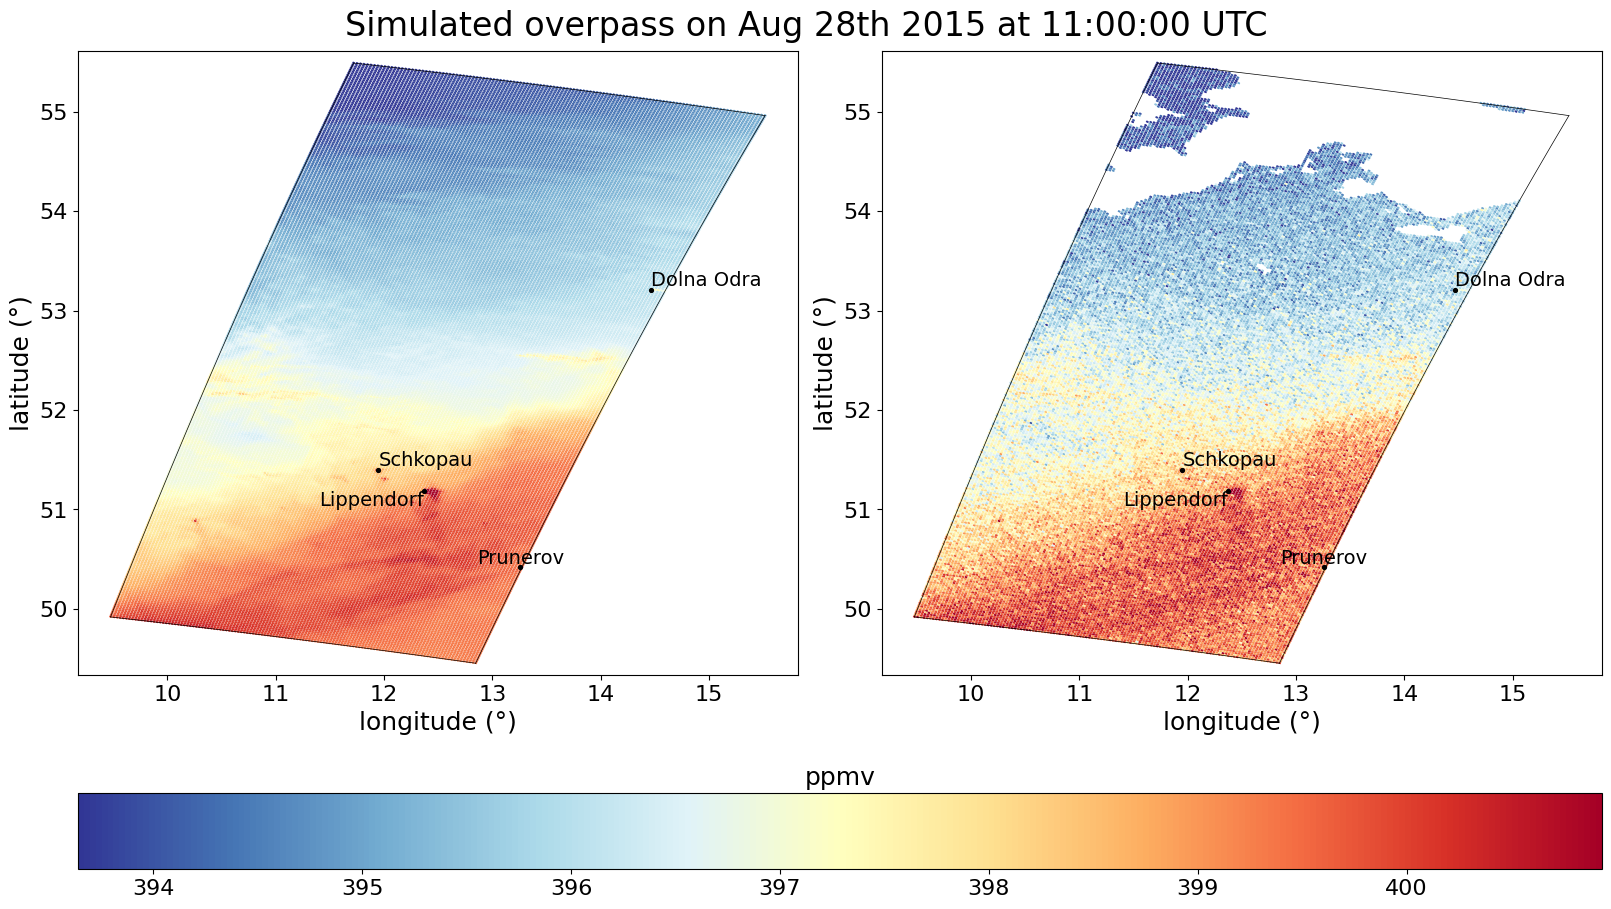

In [46]:
# Remove all observations lines where there are only nans
overpass = remove_nan_lines(overpass)
# include cross-track and along-track coordinates to the overpass
overpass = include_cross_along_for_overpass(overpass)
# Plot the overpass
date_str, time_str = get_datetime_str(overpass['time'].data, fancy_str=True, split=True)
title = f'Simulated overpass on {date_str} at {time_str}'
plot_overpasses(overpass,s=1.5,plot_edges=True,sources=sources,variables=['CO2_noisefree','CO2'],
                center_line=False,orient=True,scaling=True,title=title,
                save=False,image_format='pdf')

In [22]:
def plot_wind(wind_xr,key='GNFR_A',title='default',cmap='RdYlBu_r',
              save=False,img_format='png',overpass_edges=None):
    fig, (ax_U,ax_V) = plt.subplots(nrows=1,ncols=2,figsize=(16,9),layout='compressed')
    date_str, time_str = str(wind_xr['time'].data[0]).split('.')[0].replace('-','').replace(':','').split('T')
    year, month, day = int(date_str[:4]), int(date_str[4:6]), int(date_str[6:8])
    hour_str, minute_str, second_str = time_str[:2], time_str[2:4], time_str[4:6]
    
    if title == 'default':
        variable_name = 'eff' if key == 'GNFR_A' else key
        if day % 10 == 1:
            day_str = f'{day}st'
        elif day % 10 == 2:
            day_str = f'{day}nd'
        elif day % 10 == 3:
            day_str = f'{day}rd'
        else:
            day_str = f'{day}th'
        months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
        fancy_date_str = f'{months[month-1]} {day_str} {year}'
        fancy_time_str = f'{hour_str}:{minute_str}:{second_str} UTC'
        U_title_str = f'U{variable_name} on {fancy_date_str} at {fancy_time_str}' 
        V_title_str = f'V{variable_name} on {fancy_date_str} at {fancy_time_str}'
        ax_U.set_title(U_title_str,fontsize=20); ax_V.set_title(V_title_str,fontsize=20)
    else:
        raise ValueError('Not valid option for the title')
    wlon, wlat = wind_xr['lon'].data[:,:].flatten(),  wind_xr['lat'].data[:,:].flatten()
    U = wind_xr[f'U_{key}'].data[:,:]
    scatter_U = ax_U.scatter(wlon,wlat,c=U.flatten(),cmap='RdYlBu_r',s=0.2,vmin=-15.0,vmax=15.0)
    ax_U.set_xlim(wlon.min()-0.20,wlon.max()+0.20)
    ax_U.set_ylim(wlat.min()-0.10,wlat.max()+0.10)
    ax_U.xaxis.set_tick_params(labelsize=14)
    ax_U.yaxis.set_tick_params(labelsize=14)
    ax_U.set_xlabel('longitude (°)',fontsize=16)
    ax_U.set_ylabel('latitude (°)',fontsize=16)
    V = wind_xr[f'V_{key}'].data[:,:]
    scatter_V = ax_V.scatter(wlon,wlat,c=V.flatten(),cmap='RdYlBu_r',s=0.2,vmin=-15.0,vmax=15.0)
    ax_V.set_xlim(wlon.min()-0.20,wlon.max()+0.20)
    ax_V.set_ylim(wlat.min()-0.10,wlat.max()+0.10)
    ax_V.xaxis.set_tick_params(labelsize=14)
    ax_V.yaxis.set_tick_params(labelsize=14)
    ax_V.set_xlabel('longitude (°)',fontsize=16)
    ax_V.set_ylabel('latitude (°)',fontsize=16)
    if overpass_edges is not None:
        lon_edges, lat_edges = overpass_edges
        ax_U.plot(lon_edges,lat_edges,'k--',markersize=0.1)
        ax_V.plot(lon_edges,lat_edges,'k--',markersize=0.1)
    cbar = fig.colorbar(mappable=ScalarMappable(norm=Normalize(vmin=-15.0,vmax=15.0),cmap=cmap),
                        ax=[ax_U,ax_V],orientation='horizontal')
    cbar.ax.tick_params(labelsize=14)
    cbar.ax.set_title('m/s',fontsize=16)
    if save:
        plt.savefig(f'figures/Wind_{date_str[:4]}{date_str[4:6]}{date_str[6:8]}T{hour_str}{minute_str}{second_str}.{img_format}',
                    dpi=300)
    plt.show()

In [134]:
date_str, time_str = get_datetime_str(overpass['time'].data, fancy_str=False, split=True)
wind_file = f'SMARTCARB_winds_{date_str}{time_str[:2]}.nc'
wind_ds = xr.open_dataset(os.path.join(WIND_DATA_PATH,wind_file)).drop_vars(['U','V','HHL'],errors='ignore')
wind_sliced, overpass = slice_wind(wind_ds,overpass)
print('Wind variables:', list(wind_sliced.variables.keys()))
wind_ds.close()

Wind variables: ['U_10M', 'V_10M', 'U_GNFR_A', 'V_GNFR_A', 'rlat', 'rlon', 'time', 'height_10m', 'lon', 'lat']


In [109]:
wind_temp = xr.open_dataset(f'SMARTCARB_winds_2015082811.nc')
wind_temp

<xarray.Dataset> Size: 10MB
Dimensions:     (rlat: 600, rlon: 700, time: 1)
Coordinates:
  * rlat        (rlat) float32 2kB 2.5 2.51 2.52 2.53 ... 8.46 8.47 8.48 8.49
  * rlon        (rlon) float32 3kB -1.4 -1.39 -1.38 -1.37 ... 5.57 5.58 5.59
  * time        (time) datetime64[ns] 8B 2015-08-28T11:00:00
    height_10m  float32 4B ...
    lon         (rlat, rlon) float32 2MB ...
    lat         (rlat, rlon) float32 2MB ...
Data variables:
    U_10M       (time, rlat, rlon) float32 2MB ...
    V_10M       (time, rlat, rlon) float32 2MB ...
    U_GNFR_A    (time, rlat, rlon) float32 2MB ...
    V_GNFR_A    (time, rlat, rlon) float32 2MB ...
Attributes:
    CREATOR:       Gerrit Kuhlmann
    EMAIL:         gerrit.kuhlmann@empa.ch
    ORIGIN:        SMARTCARB COSMO-GHG simulations
    DATE CREATED:  Tue Aug 23 10:11:08 2022

In [108]:
wind_temp.close()

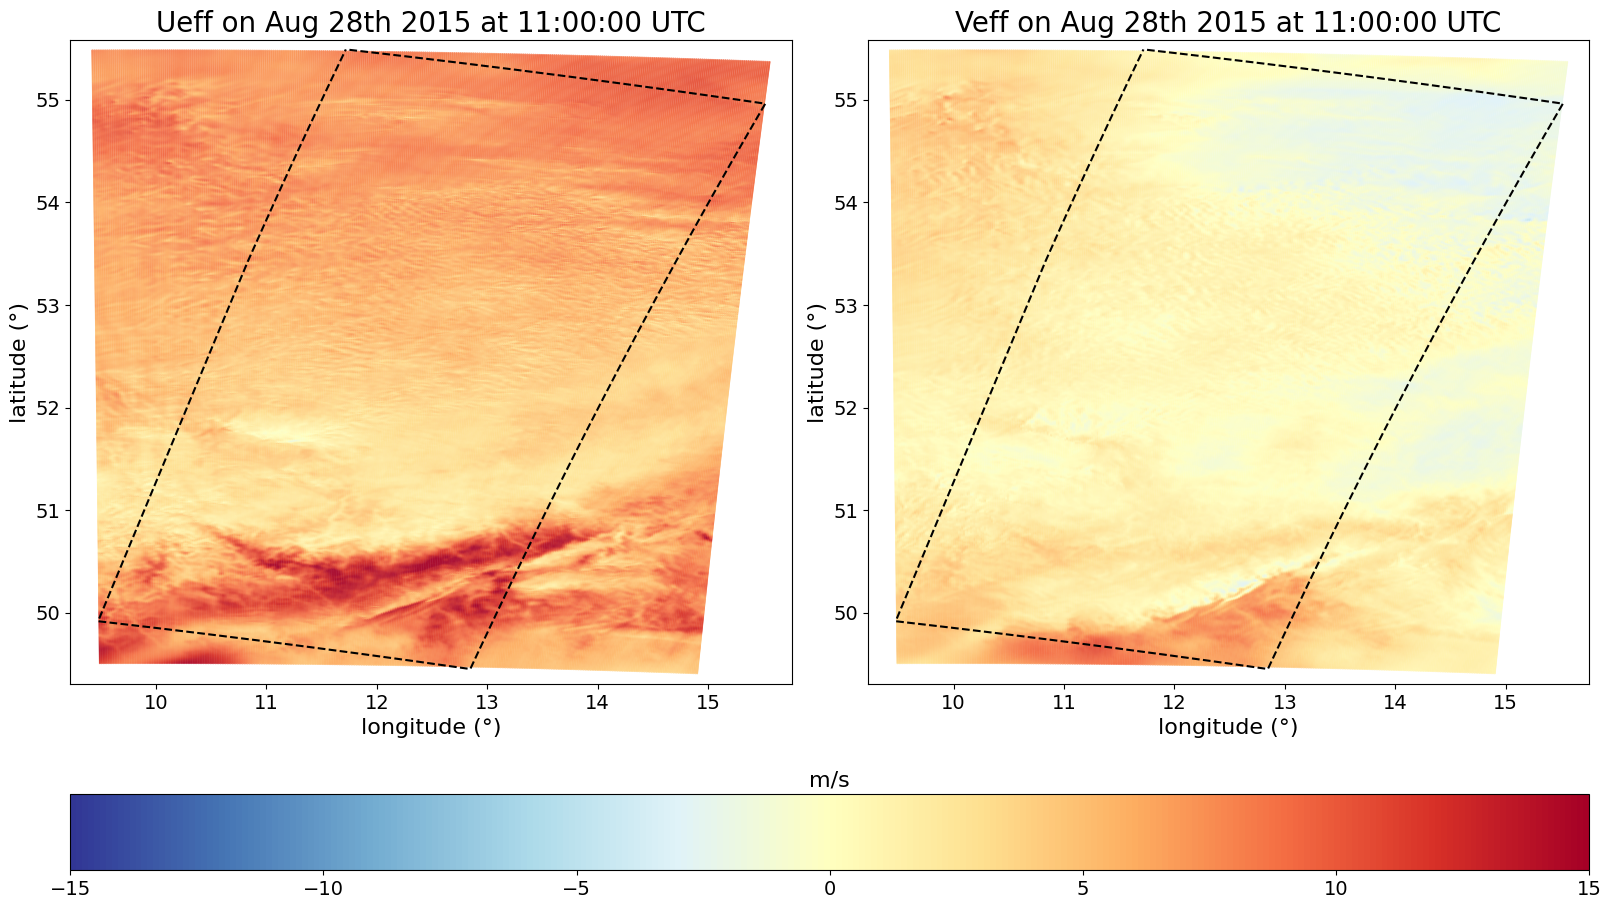

In [112]:
shape = (overpass.dims['nrows'], overpass.dims['nobs'])
overpass_edges = (np.concatenate((overpass['lon'].data[0,1:],
                                  overpass['lon'].data[1:,-1],
                                  overpass['lon'].data[-1,(shape[1]-2)::-1],
                                  overpass['lon'].data[(shape[0]-2)::-1,0])),
                  np.concatenate((overpass['lat'].data[0,1:],
                                  overpass['lat'].data[1:,-1],
                                  overpass['lat'].data[-1,(shape[1]-2)::-1],
                                  overpass['lat'].data[(shape[0]-2)::-1,0])))
plot_wind(wind_sliced,overpass_edges=overpass_edges,title='default',save=False,img_format='pdf')

In [110]:
def get_local_wind(wind,coord,radius=8.0):
    shape = (wind.dims['rlat'],wind.dims['rlon'])
    wlon, wlat = wind['lon'].data, wind['lat'].data
    wind_coords = np.column_stack((wlon.flatten(),wlat.flatten()))
    dists = 1e-3*Earth.inverse(wind_coords,coord)[:,0]
    min_index = np.argmin(dists)
    min_dist = dists[min_index]
    multi_index = np.unravel_index(min_index,shape)
    
    if multi_index[0] == 0 and multi_index[1] == 0:
        neighboring_coords = [(wlon[0,1],wlat[0,1]), (wlon[1,0],wlat[1,0]), (wlon[1,1],wlat[1,1])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[:3] = True
            bool_arr_lon[:3] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] == 0 and multi_index[1] == shape[1]-1:
        neighboring_coords = [(wlon[0,-2],wlat[0,-2]), (wlon[1,-1],wlat[1,-1]), (wlon[1,-2],wlat[1,-2])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[:3] = True
            bool_arr_lon[-3:] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] == shape[0]-1 and multi_index[1] == 0:
        neighboring_coords = [(wlon[-2,0],wlat[-2,0]), (wlon[-1,1],wlat[-1,1]), (wlon[-2,1],wlat[-2,1])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[-3:] = True
            bool_arr_lon[:3] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] == shape[0]-1 and multi_index[1] == shape[1]-1:
        neighboring_coords = [(wlon[-1,-2],wlat[-1,-2]), (wlon[-2,-1],wlat[-2,-1]), (wlon[-2,-2],wlat[-2,-2])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[-3:] = True
            bool_arr_lon[-3:] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] == 0 and multi_index[1] not in [0,shape[1]-1]:
        neighboring_coords = [(wlon[1,multi_index[1]],wlat[1,multi_index[1]]), 
                              (wlon[0,multi_index[1]-1],wlat[0,multi_index[1]-1]), 
                              (wlon[0,multi_index[1]+1],wlat[0,multi_index[1]+1])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[:3] = True
            bool_arr_lon[max(multi_index[1]-4,0):min(multi_index[1]+5,shape[1])] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] == shape[0]-1 and multi_index[1] not in [0,shape[1]-1]:
        neighboring_coords = [(wlon[-2,multi_index[1]],wlat[-2,multi_index[1]]), 
                              (wlon[-1,multi_index[1]-1],wlat[-1,multi_index[1]-1]), 
                              (wlon[-1,multi_index[1]+1],wlat[-1,multi_index[1]+1])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[-3:] = True
            bool_arr_lon[max(multi_index[1]-4,0):min(multi_index[1]+5,shape[1])] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] not in [0,shape[0]-1] and multi_index[1] == 0:
        neighboring_coords = [(wlon[multi_index[0],1],wlat[multi_index[0],1]), 
                              (wlon[multi_index[0]-1,0],wlat[multi_index[0]-1,0]), 
                              (wlon[multi_index[0]+1,0],wlat[multi_index[0]+1,0])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[max(multi_index[0]-4,0):min(multi_index[0]+5,shape[0])] = True
            bool_arr_lon[:3] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    elif multi_index[0] not in [0,shape[0]-1] and multi_index[1] == shape[1]-1:
        neighboring_coords = [(wlon[multi_index[0],-2],wlat[multi_index[0],-2]), 
                              (wlon[multi_index[0]-1,-1],wlat[multi_index[0]-1,-1]), 
                              (wlon[multi_index[0]+1,-1],wlat[multi_index[0]+1,-1])]
        dists_to_neighbors = 1e-3*Earth.inverse(neighboring_coords,coord)[:,0]
        if np.all(min_dist < dists_to_neighbors):
            bool_arr_lat, bool_arr_lon = np.zeros(shape[0],dtype=bool), np.zeros(shape[1],dtype=bool)
            bool_arr_lat[max(multi_index[0]-4,0):min(multi_index[0]+5,shape[0])] = True
            bool_arr_lon[-3:] = True
            bool_xr = xr.DataArray(bool_arr_lat, dims=['rlat']) & xr.DataArray(bool_arr_lon, dims=['rlon'])
        else:
            return None
    else:
        bool_arr = (1e-3*Earth.inverse(wind_coords,coord)[:,0] < radius).reshape(shape)
        bool_xr = xr.DataArray(np.any(bool_arr,axis=1), dims=['rlat']) & \
                  xr.DataArray(np.any(bool_arr,axis=0), dims=['rlon'])
    return wind.where(bool_xr,drop=True)

def get_local_overpass(overpass,coord,max_range=4,source_name='Unknown'):
    overpass_coords = np.column_stack((overpass['lon'].data.flatten(),overpass['lat'].data.flatten()))
    dists = 1e-3*Earth.inverse(overpass_coords,coord)[:,0]
    min_index = np.argmin(dists)
    # Check if source is outside the overpass footprint
    if dists[min_index] > np.sqrt((2.039/2.0)**2 + (1.996/2.0)**2):
        return None
    shape = (overpass.dims['nobs'],overpass.dims['nrows'])
    multi_index = np.unravel_index(min_index,shape)
    bool_arr = np.zeros(shape,dtype=bool)
    row_start = max(0,multi_index[0]-max_range)
    row_end = min(shape[0],multi_index[0]+max_range+1)
    col_start = max(0,multi_index[1]-max_range)
    col_end = min(shape[1],multi_index[1]+max_range+1)
    bool_arr[row_start:row_end,col_start:col_end] = True
    bool_da = xr.DataArray(bool_arr, dims=['nobs','nrows'])
    overpass_local = slice_xarray_dataset(overpass,bool_da)
    overpass_local['source'] = source_name
    return overpass_local

def slice_xarray_dataset(ds,bool_da):
    variables_without_dim = [variable for variable in ds.variables if ds[variable].ndim == 0]
    temp = ds.drop_vars(variables_without_dim)
    temp = temp.where(bool_da, drop=True)
    for variable in variables_without_dim:
        temp[variable] = ds[variable]
    return temp

In [27]:
def extend_data_with_nan(data,up=0,down=0,left=0,right=0):
    if data.ndim != 2:
        raise ValueError('NaN extension of data only supported in 2D')
    if not all([isinstance(up,int), isinstance(down,int), isinstance(left,int), isinstance(right,int)]):
        raise ValueError('Extension to any direction must be an integer')
    if any([up<0, down<0, left<0, right<0]):
        raise ValueError('Extension to any direction can not be negative')
    shape = data.shape
    up_nans, down_nans = np.full((up,shape[1]),np.nan), np.full((down,shape[1]),np.nan)
    left_nans, right_nans = np.full((shape[0]+up+down,left),np.nan), np.full((shape[0]+up+down,right),np.nan)
    return np.concatenate((left_nans,
                           np.concatenate((up_nans,data,down_nans),axis=0),
                           right_nans),
                           axis=1)
    
def extend_coords_linearly(coord_arr,up=0,down=0,left=0,right=0):
    if coord_arr.ndim != 2:
        raise ValueError('Extension of coordinate array only supported in 2D')
    shape = coord_arr.shape
    row_indices = np.arange(0,shape[0],dtype=int)
    col_indices = np.arange(0,shape[1],dtype=int)
    if up > 0 or down > 0:
        coefs = np.polyfit(row_indices, coord_arr, 1)
        if up > 0:
            up_extend_indices = np.repeat(np.arange(-up,0,dtype=int)[:,np.newaxis],
                                          axis=1,repeats=shape[1])
            up_extend_coords = coefs[0][np.newaxis,:] * up_extend_indices + coefs[1][np.newaxis,:]
        else:
            up_extend_coords = np.empty((0,shape[1]))
        if down > 0:
            down_extend_indices = np.repeat(np.arange(shape[0],shape[0]+down,dtype=int)[:,np.newaxis],
                                            axis=1,repeats=shape[1])
            down_extend_coords = coefs[0][np.newaxis,:] * down_extend_indices + coefs[1][np.newaxis,:]
        else:
            down_extend_x, down_extend_y = np.empty((0,shape[1])), np.empty((0,shape[1]))
        coord_arr = np.concatenate((up_extend_coords,coord_arr,down_extend_coords), axis=0)
    if left > 0 or right > 0:
        coefs = np.polyfit(col_indices, coord_arr.T, 1)
        if left > 0:
            left_extend_indices = np.repeat(np.arange(-left,0,dtype=int)[np.newaxis,:],
                                            axis=0,repeats=shape[0]+up+down)
            left_extend_coords = coefs[0][:,np.newaxis] * left_extend_indices + coefs[1][:,np.newaxis]
        else:
            left_extend_coords = np.empty((shape[0]+up+down,0))
        if right > 0:
            right_extend_indices = np.repeat(np.arange(shape[1],shape[1]+right,dtype=int)[np.newaxis,:],
                                             axis=0,repeats=shape[0]+up+down)
            right_extend_coords = coefs[0][:,np.newaxis] * right_extend_indices + coefs[1][:,np.newaxis]
        else:
            right_extend_coords = np.empty((shape[0]+up+down,0))
        return np.concatenate((left_extend_coords,coord_arr,right_extend_coords), axis=1)

In [28]:
def extend_overpass(local_overpass,center_index=(0,0),target_shape=(9,9)):
    all_variables = local_overpass.variables
    variables_without_dim = [variable for variable in all_variables
                             if local_overpass[variable].ndim == 0]
    variables_to_extend = [variable for variable in all_variables
                           if local_overpass[variable].dims == ('nobs','nrows') 
                           and variable not in ['lon','lat','cross_track','along_track']]
    if target_shape[0] % 2 == 0 or target_shape[0] % 2 == 0:
        raise ValueError('Number of rows and columns in the NaN-extension target shape must be odd')
    shape = (local_overpass.dims['nobs'], local_overpass.dims['nrows'])
    pixels_to_top = center_index[0]
    pixels_to_bottom = shape[0] - 1 - center_index[0]
    pixels_to_left = center_index[1]
    pixels_to_right = shape[1] - 1 - center_index[1]
    if target_shape[0] < 2*max(pixels_to_top,pixels_to_bottom) + 1:
        msg = f'Number of target rows (={target_shape[0]}) is too small for the data shape {shape} with center index at {center_index}'
        raise ValueError(msg)
    if target_shape[1] < 2*max(pixels_to_left,pixels_to_right) + 1:
        msg = f'Number of target cols (={target_shape[1]}) is too small for the data shape {shape} with center index at {center_index}'
        raise ValueError(msg)
    
    extend_up = int((target_shape[0]-1)//2 - pixels_to_top)
    extend_down = int((target_shape[0]-1)//2 - pixels_to_bottom)
    extend_left = int((target_shape[1]-1)//2 - pixels_to_left)
    extend_right = int((target_shape[1]-1)//2 - pixels_to_right)
    
    data_vars = {}
    for variable in variables_to_extend:
        extended_data = extend_data_with_nan(local_overpass[variable].data,
                                             up=extend_up,down=extend_down,
                                             left=extend_left,right=extend_right)
        data_vars[variable] = xr.DataArray(data=extended_data,dims=('nobs','nrows'))
        
    for variable in ['lon', 'lat', 'cross_track', 'along_track']:
        if variable not in all_variables:
            continue
        extended_coords = extend_coords_linearly(local_overpass[variable].data,
                                                 up=extend_up,down=extend_down,
                                                 left=extend_left,right=extend_right)
        data_vars[variable] = xr.DataArray(data=extended_coords,dims=('nobs','nrows'))
        
    for variable in ['lonc', 'latc', 'cross_track_corners', 'along_track_corners']:
        if variable not in all_variables:
            continue
        extended_corners = np.stack([extend_coords_linearly(local_overpass[variable].data[:,:,n],
                                                            up=extend_up,down=extend_down,
                                                            left=extend_left,right=extend_right)
                                    for n in range(local_overpass.dims['ncorners'])], axis=-1)
        data_vars[variable] = xr.DataArray(data=extended_corners,dims=('nobs','nrows','ncorners'))
    for variable in variables_without_dim:
        data_vars[variable] = local_overpass[variable]
        
    return xr.Dataset(data_vars=data_vars,attrs=local_overpass.attrs)

In [105]:
def plot_local_overpass(overpass,coord,wind=None,variable='CO2',coordinate_system='both',
                        cmap="RdYlBu_r",title=None,save=False,img_format='png'):
    if coordinate_system not in ['both','spherical','cartesian']:
        raise ValueError(f'Unknown option for coordinate system: {coordinate_system}')
    if wind is not None:
        local_wind = get_local_wind(wind,coord)
    local_overpass = get_local_overpass(overpass,coord)
    if local_overpass is None:
        print('Requested coordinate outside the overpass footprint')
        return None
    variable_xr = local_overpass[variable]
    shape = (local_overpass.dims['nobs'], local_overpass.dims['nrows'])
    
    # Find index of a pixel closest to coord
    lon, lat = local_overpass['lon'].data, local_overpass['lat'].data
    ct, at = local_overpass['cross_track'].data, local_overpass['along_track'].data
    min_flat_index = np.argmin(Earth.inverse(np.column_stack((lon.flatten(),lat.flatten())),coord)[:,0])
    closest_index = np.unravel_index(min_flat_index,shape)
    if shape != (9,9):
        local_overpass = extend_overpass(local_overpass,center_index=closest_index,target_shape=(9,9))
        variable_xr = local_overpass[variable]
        lon, lat = local_overpass['lon'].data, local_overpass['lat'].data
        ct, at = local_overpass['cross_track'].data, local_overpass['along_track'].data
    if coordinate_system == 'both':
        fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(16,9),layout='compressed')
        axs = axs.flatten()
        coordinate_system_list = ['spherical','cartesian']
    else:
        fig = plt.figure(figsize=(9,8),layout='compressed')
        axs = [fig.gca()]
        coordinate_system_list = [coordinate_system]
        
    data_mean, data_std = np.nanmean(variable_xr.data), np.nanstd(variable_xr.data,ddof=1)
    vmin, vmax = data_mean - 2.0*data_std, data_mean + 2.5*data_std
    
    for n in range(len(axs)):
        if title is not None:
            if title == 'default':
                if variable == 'CO2':
                    variable_str = r'Synthetic CO$_2$'
                elif variable == 'CO2_noisefree':
                    variable_str = r'Noisefree synthetic CO$_2$'
                else:
                    variable_str = variable
                if coordinate_system_list[n] == 'spherical':
                    lonc, latc = lon.mean(), lat.mean()
                    lat_str = f'{latc:.3f} °N' if latc >= 0.0 else f'{-latc:.3f} °S'
                    lon_str = f'{lonc:.3f} °E' if lonc >= 0.0 else f'{-lonc:.3f} °W'
                    coord_str = f'({lat_str}, {lon_str})'
                if coordinate_system_list[n] == 'cartesian':
                    ctc, atc = ct.mean(), at.mean()
                    ct_str = f'{ctc:.1f} km ct'
                    at_str = f'{atc:.1f} km at'
                    coord_str = f'({ct_str}, {at_str})'
                date_str, time_str = get_datetime_str(overpass_near_source['time'].data, fancy_str=True, split=True)
                axs[n].set_title(f'{variable_str} near {coord_str}\non {date_str} at {time_str}', fontsize=18)
            else:
                raise ValueError(f'Uknown title option: {title}')
        ax = axs[n]
        if coordinate_system_list[n] == 'spherical':
            custom_marker = [(-0.5,0.5,0.5,-0.5), (-0.5,-0.5,0.5,0.5)]
            orientation = np.arctan2((lat[:-1,:]-lat[1:,:]).flatten(),
                                     (lon[:-1,:]-lon[1:,:]).flatten()).mean() + np.pi/25.0
            R = np.array([[np.cos(orientation),-np.sin(orientation)],
                          [np.sin(orientation), np.cos(orientation)]])
            oriented_marker = np.transpose(np.matmul(R,custom_marker))
            lon_min, lon_max = lon.min(), lon.max()
            lat_min, lat_max = lat.min(), lat.max()
            ax.set_xlim(lon_min-0.05,lon_max+0.05)
            ax.set_ylim(lat_min-0.02,lat_max+0.02)
            size = 2000
            ax.set_xlabel('longitude (°)',fontsize=16)
            ax.set_ylabel('latitude (°)',fontsize=16)
            color_plot = ax.scatter(lon.flatten(),lat.flatten(),
                                    c=variable_xr.data.flatten(),
                                    vmin=vmin,vmax=vmax,
                                    s=size,marker=oriented_marker,cmap=cmap)
            #ax.plot(*coord,color='black',marker='d',markersize=10.0)
            #circle = Earth.circle(lon=coord[0], lat=coord[1], radius=1000.0)
            #ax.plot(circle[:,0],circle[:,1],'k--',linewidth=2.0)
            
            if wind is not None:
                ax.quiver(local_wind['lon'].data.flatten(),local_wind['lat'].data.flatten(),
                          local_wind['U_GNFR_A'].data.flatten(),local_wind['V_GNFR_A'].data.flatten())
        
        if coordinate_system_list[n] == 'cartesian':
            size = 2100
            color_plot = ax.scatter(ct.flatten(),at.flatten(),
                                    c=variable_xr.data.flatten(),
                                    vmin=vmin,vmax=vmax,
                                    marker='s',s=size,cmap=cmap)
            ax.set_xlabel('cross-track (km)',fontsize=16)
            ax.set_ylabel('along-track (km)',fontsize=16)
            ct_min, ct_max = ct.min(), ct.max()
            at_min, at_max = at.min(), at.max()
            ax.set_xlim(ct_min-2.5,ct_max+2.5)
            ax.set_ylim(at_min-2.5,at_max+2.5)
            if wind is not None:
                ax.quiver(local_wind['cross_track'].data.flatten(),local_wind['along_track'].data.flatten(),
                          local_wind['VXeff'].data.flatten(),local_wind['VYeff'].data.flatten())
        ax.xaxis.set_tick_params(labelsize=14)
        ax.yaxis.set_tick_params(labelsize=14)
        if coordinate_system != 'both':
            cbar = fig.colorbar(ax=ax,mappable=color_plot)
            cbar.ax.tick_params(labelsize=14)
            cbar.ax.set_title(variable_xr.attrs['units'],fontsize=16)
    if coordinate_system == 'both':
        cbar = fig.colorbar(mappable=ScalarMappable(norm=Normalize(vmin=vmin,vmax=vmax),cmap=cmap),
                            ax=axs,orientation='horizontal')
        cbar.ax.tick_params(labelsize=14)
        cbar.ax.set_title('ppmv',fontsize=16)
    if save:
        plt.savefig(f'figures/local_overpass_and_wind_latest.{img_format}',dpi=300)
    plt.show()
    
def plot_local_wind(wind,coord=None,level='eff',radius=8.0,cmap="RdYlBu_r",
                    coordinate_system='spherical'):
    if wind is None:
        print('No wind data to plot')
        return
    if coord is not None:
        local_wind = get_local_wind(wind,coord,radius=radius)
    else:
        local_wind = wind
    if local_wind is None:
        print('Wind data missing near the requested coordinate')
        return
    local_wind_variables = list(local_wind.variables.keys())
    if coordinate_system not in ['spherical','cartesian']:
        raise ValueError(f'Invalid coordinate system {coordinate_system}')
    if isinstance(level,int):
        if coordinate_system == 'spherical':
            if 'U' not in local_wind_variables:
                raise ValueError('Missing U-component of the wind on different levels')
            if 'V' not in local_wind_variables:
                raise ValueError('Missing V-component of the wind on different levels')
            data_first, data_second = local_wind['U'].data[0,level,:,:], local_wind['V'].data[0,level,:,:]
        else:
            if 'VX' not in local_wind_variables:
                raise ValueError('Missing vx-component of the wind on different levels')
            if 'VY' not in local_wind_variables:
                raise ValueError('Missing vy-component of the wind on different levels')
            data_first, data_second = local_wind['VX'].data[0,level,:,:], local_wind['VY'].data[0,level,:,:]
        vmin, vmax = -20.0, 20.0
    elif level == 'eff':
        if coordinate_system == 'spherical':
            data_first, data_second = local_wind['U_GNFR_A'].data[0,:,:], local_wind['V_GNFR_A'].data[0,:,:]
        else:
            data_first, data_second = local_wind['VXeff'].data[0,:,:], local_wind['VYeff'].data[0,:,:]
        vmin, vmax = -15.0, 15.0
    elif level == '10M':
        if coordinate_system == 'spherical':
            data_first, data_second = local_wind['U_10M'].data[0,:,:], local_wind['V_10M'].data[0,:,:]
        else:
            data_first, data_second = local_wind['VX10M'].data[0,:,:], local_wind['VY10M'].data[0,:,:]
        vmin, vmax = -10.0, 10.0

    fig, (ax1,ax2) = plt.subplots(nrows=1,ncols=2,figsize=(14,8),layout='compressed')
    if coordinate_system == 'spherical':
        ax1.set_title("U component of the local wind",fontsize=16)
        ax2.set_title("V component of the local wind",fontsize=16)
    else:
        ax1.set_title("VX component of the local wind",fontsize=16)
        ax2.set_title("VY component of the local wind",fontsize=16)
    if coordinate_system == 'spherical':
        local_lon, local_lat = local_wind['lon'].data, local_wind['lat'].data
        custom_marker = [(-0.5,0.5,0.5,-0.5), (-0.5,-0.5,0.5,0.5)]
        orientation = np.arctan2((local_lat[1:,:]-local_lat[:-1,:]).flatten(),
                                 (local_lon[1:,:]-local_lon[:-1,:]).flatten()).mean()
        R = np.array([[np.cos(orientation),-np.sin(orientation)],
                      [np.sin(orientation), np.cos(orientation)]])
        oriented_marker = np.transpose(np.matmul(R,custom_marker))
        ax1.set_xlim(local_lon.min()-0.02,local_lon.max()+0.02)
        ax1.set_ylim(local_lat.min()-0.015,local_lat.max()+0.015)
        ax1.set_xlabel('longitude (°)',fontsize=14)
        ax1.set_ylabel('latitude (°)',fontsize=14)
        ax2.set_xlim(local_lon.min()-0.02,local_lon.max()+0.02)
        ax2.set_ylim(local_lat.min()-0.015,local_lat.max()+0.015)
        ax2.set_xlabel('longitude (°)',fontsize=14)
        ax2.set_ylabel('latitude (°)',fontsize=14)
        ax1.scatter(local_lon.flatten(),local_lat.flatten(),
                    vmin=vmin,vmax=vmax,c=data_first.flatten(),s=650,
                    marker=oriented_marker,cmap=cmap)
        ax2.scatter(local_lon.flatten(),local_lat.flatten(),
                    vmin=vmin,vmax=vmax,c=data_second.flatten(),s=650,
                    marker=oriented_marker,cmap=cmap)
        if coord is not None:
            ax1.scatter(*coord,c='k',s=50.0)
            ax2.scatter(*coord,c='k',s=50.0)
    elif coordinate_system == 'cartesian':
        local_cross, local_along = local_wind['cross_track'].data, local_wind['along_track'].data
        if coord is not None:
            dists = 1e-3*Earth.inverse(np.column_stack((local_wind['cross_track'].data.flatten(),
                                                        local_wind['along_track'].data.flatten())),
                                       coord)[:,0]
            nearest_index = np.unravel_index(np.argmin(dists),(local_wind.dims['rlat'],local_wind.dims['rlon']))
        ax1.set_xlim(local_cross.min()-1.5,local_cross.max()+1.5)
        ax1.set_ylim(local_along.min()-1.5,local_along.max()+1.5)
        ax1.set_xlabel('cross-track (km)',fontsize=14)
        ax1.set_ylabel('along-track (km)',fontsize=14)
        ax2.set_xlim(local_cross.min()-1.5,local_cross.max()+1.5)
        ax2.set_ylim(local_along.min()-1.5,local_along.max()+1.5)
        ax2.set_xlabel('cross-track (km)',fontsize=14)
        ax2.set_ylabel('along-track (km)',fontsize=14)
        orientation = np.arctan2((local_along[1:,:]-local_along[:-1,:]).flatten(),
                                 (local_cross[1:,:]-local_cross[:-1,:]).flatten()).mean()
        R = np.array([[np.cos(orientation),-np.sin(orientation)],
                      [np.sin(orientation), np.cos(orientation)]])
        custom_marker = [(-0.5,0.5,0.5,-0.5), (-0.5,-0.5,0.5,0.5)]
        oriented_marker = np.transpose(np.matmul(R,custom_marker))
        ax1.scatter(local_cross.flatten(),local_along.flatten(),
                    vmin=vmin,vmax=vmax,c=data_first.flatten(),s=650,
                    marker=oriented_marker,cmap=cmap)
        ax2.scatter(local_cross.flatten(),local_along.flatten(),
                    vmin=vmin,vmax=vmax,c=data_second.flatten(),s=650,
                    marker=oriented_marker,cmap=cmap)
    else:
        raise ValueError(f'Unknown coordinate system {coordinate_system}')
    ax1.xaxis.set_tick_params(labelsize=12)
    ax1.yaxis.set_tick_params(labelsize=12)
    ax2.xaxis.set_tick_params(labelsize=12)
    ax2.yaxis.set_tick_params(labelsize=12)
    cbar = fig.colorbar(mappable=ScalarMappable(norm=Normalize(vmin=vmin,vmax=vmax),cmap=cmap),
                        ax=[ax1,ax2],orientation='horizontal')
    cbar.ax.tick_params(labelsize=12)
    cbar.ax.set_title('m/s',fontsize=14)
    plt.show()

In [30]:
def get_corners_from_coordinates(x_coords,y_coords):
    xc, yc = x_coords.mean(), y_coords.mean()
    sum_arr = (x_coords-xc)+(y_coords-yc)
    corners = [(x_coords[np.argmin(sum_arr)],y_coords[np.argmin(sum_arr)]),
               (x_coords[np.argmax(sum_arr)],y_coords[np.argmax(sum_arr)])]
    k = np.divide(*np.subtract(corners[1],corners[0])[::-1])
    line = lambda x: yc + k*(x-xc)
    dist_from_line = lambda x0,y0,a,b,c: np.abs(a*x0+b*y0+c)/np.sqrt(a**2+b**2)
    above = np.where(y_coords > line(x_coords))[0]
    furthest_above_ind = above[np.argmax(dist_from_line(x_coords[above],y_coords[above],k,-1,yc-k*xc))]
    below = np.where(y_coords < line(x_coords))[0]
    furthest_below_ind = below[np.argmax(dist_from_line(x_coords[below],y_coords[below],k,-1,yc-k*xc))]
    corners.append((x_coords[furthest_above_ind],y_coords[furthest_above_ind]))
    corners.append((x_coords[furthest_below_ind],y_coords[furthest_below_ind]))
    return corners

def get_corners_of_pixels(x_grid,y_grid,flat=True):
    extrapolation_to_right = np.stack((0.5*(x_grid[:,:-1]-x_grid[:,1:]).mean(axis=1,keepdims=True),
                                       0.5*(y_grid[:,:-1]-y_grid[:,1:]).mean(axis=1,keepdims=True)),axis=-1)
    vecs_to_right = np.concatenate((extrapolation_to_right,
                                    0.5*np.stack((x_grid[:,:-1]-x_grid[:,1:], y_grid[:,:-1]-y_grid[:,1:]),axis=-1)),
                                   axis=1)
    extrapolation_to_left = np.stack((0.5*(x_grid[:,1:]-x_grid[:,:-1]).mean(axis=1,keepdims=True),
                                      0.5*(y_grid[:,1:]-y_grid[:,:-1]).mean(axis=1,keepdims=True)),axis=-1)
    vecs_to_left = np.concatenate((0.5*np.stack((x_grid[:,1:]-x_grid[:,:-1], y_grid[:,1:]-y_grid[:,:-1]),axis=-1),
                                   extrapolation_to_left),
                                  axis=1)
    extrapolation_to_top = np.stack((0.5*(x_grid[:-1,:]-x_grid[1:,:]).mean(axis=0,keepdims=True),
                                     0.5*(y_grid[:-1,:]-y_grid[1:,:]).mean(axis=0,keepdims=True)),axis=-1)
    vecs_to_top = np.concatenate((extrapolation_to_top,
                                  0.5*np.stack((x_grid[:-1,:]-x_grid[1:,:], y_grid[:-1,:]-y_grid[1:,:]),axis=-1)),
                                 axis=0)
    extrapolation_to_bottom = np.stack((0.5*(x_grid[1:,:]-x_grid[:-1,:]).mean(axis=0,keepdims=True),
                                        0.5*(y_grid[1:,:]-y_grid[:-1,:]).mean(axis=0,keepdims=True)),axis=-1)
    vecs_to_bottom = np.concatenate((0.5*np.stack((x_grid[1:,:]-x_grid[:-1,:], y_grid[1:,:]-y_grid[:-1,:]),axis=-1),
                                    extrapolation_to_bottom),
                                    axis=0)
    grids = np.stack((x_grid,y_grid),axis=-1)
    bottom_left = grids + vecs_to_left + vecs_to_bottom
    bottom_right = grids + vecs_to_right + vecs_to_bottom
    top_right = grids + vecs_to_right + vecs_to_top
    top_left = grids + vecs_to_left + vecs_to_top

    x_corners = np.stack((bottom_left[:,:,0],bottom_right[:,:,0],top_right[:,:,0],top_left[:,:,0]),axis=-1)
    y_corners = np.stack((bottom_left[:,:,1],bottom_right[:,:,1],top_right[:,:,1],top_left[:,:,1]),axis=-1)
    return (x_corners.reshape((-1,4)), y_corners.reshape((-1,4))) if flat else (x_corners,y_corners)

# Get (x,y) intercept between a line going through a point p with direction vector vec and 
# a quadrilateral defined by the corners
def get_line_intercept_with_quadrilateral(p,vec,corners):
    if len(corners) != 4:
        raise ValueError('Number of corners must be 4')
    # bl = bottom left, tr = top right, tl = top left, br = bottom right, 
    bl_corner, tr_corner, tl_corner, br_corner = corners
    # Top line coefs
    tl_coefs = [tr_corner[1]-tl_corner[1],
                -(tr_corner[0]-tl_corner[0]),
                (tr_corner[0]-tl_corner[0])*0.5*(tr_corner[1]+tl_corner[1])-
                (tr_corner[1]-tl_corner[1])*0.5*(tr_corner[0]+tl_corner[0])]
    # Bottom line coefs
    bl_coefs = [br_corner[1]-bl_corner[1],
                        -(br_corner[0]-bl_corner[0]),
                        (br_corner[0]-bl_corner[0])*0.5*(br_corner[1]+bl_corner[1])-
                        (br_corner[1]-bl_corner[1])*0.5*(br_corner[0]+bl_corner[0])]
    # Left line coefs
    ll_coefs = [tl_corner[1]-bl_corner[1],
                -(tl_corner[0]-bl_corner[0]),
                (tl_corner[0]-bl_corner[0])*0.5*(tl_corner[1]+bl_corner[1])-
                (tl_corner[1]-bl_corner[1])*0.5*(tl_corner[0]+bl_corner[0])]
    # Right line coefs
    rl_coefs = [tr_corner[1]-br_corner[1],
                -(tr_corner[0]-br_corner[0]),
                (tr_corner[0]-br_corner[0])*0.5*(tr_corner[1]+br_corner[1])-
                (tr_corner[1]-br_corner[1])*0.5*(tr_corner[0]+br_corner[0])]
    inside = Polygon([bl_corner,br_corner,tr_corner,tl_corner]).contains(Point(*p))
    if not inside:
        raise ValueError('Point not inside the Polygon defined by the corners')
    
    (vx,vy) = vec
    # Main line coefs
    main_coefs = [vy,-vx,vx*p[1]-vy*p[0]]
    if vx < 0.0:
        # Angle with the vector (-1,0)
        angle = np.arccos(-vx/np.linalg.norm((vx,vy))) if vy < 0.0 else -np.arccos(-vx/np.linalg.norm((vx,vy)))
        vec_to_tl = np.subtract(tl_corner,p)
        vec_to_bl = np.subtract(bl_corner,p)
        angle_min = -np.arccos(-vec_to_tl[0]/np.linalg.norm(vec_to_tl))
        angle_max = np.arccos(-vec_to_bl[0]/np.linalg.norm(vec_to_bl))
        if angle < angle_min:
            A = np.array([[main_coefs[0], main_coefs[1]], [tl_coefs[0], tl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], tl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
        elif angle > angle_max:
            A = np.array([[main_coefs[0], main_coefs[1]], [bl_coefs[0], bl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], bl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
        else:
            A = np.array([[main_coefs[0], main_coefs[1]], [ll_coefs[0], ll_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], ll_coefs[2]]),
                                             check_finite=False,assume_a='gen')
    elif vx > 0.0:
        # Angle with the vector (1,0)
        angle = np.arccos(vx/np.linalg.norm((vx,vy))) if vy > 0.0 else -np.arccos(vx/np.linalg.norm((vx,vy)))
        vec_to_tr = np.subtract(tr_corner,p)
        vec_to_br = np.subtract(br_corner,p)
        angle_max = np.arccos(vec_to_tr[0]/np.linalg.norm(vec_to_tr))
        angle_min = -np.arccos(vec_to_br[0]/np.linalg.norm(vec_to_br))
        if angle < angle_min:
            A = np.array([[main_coefs[0], main_coefs[1]], [bl_coefs[0], bl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], bl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
        elif angle > angle_max:
            A = np.array([[main_coefs[0], main_coefs[1]], [tl_coefs[0], tl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], tl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
        else:
            A = np.array([[main_coefs[0], main_coefs[1]], [rl_coefs[0], rl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], rl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
    else:
        if vy > 0.0:
            A = np.array([[main_coefs[0], main_coefs[1]], [tl_coefs[0], tl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], tl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
        elif vy < 0.0:
            A = np.array([[main_coefs[0], main_coefs[1]], [bl_coefs[0], bl_coefs[1]]])
            x_intercept, y_intercept = solve(A,-np.array([main_coefs[2], bl_coefs[2]]),
                                             check_finite=False,assume_a='gen')
        else:
            raise ValueError('Exact zero direction vector')
    return (x_intercept,y_intercept)

def get_cone_corners(grid_corners,cone_center,dir_vec,spread_fun,return_outside_cone=False):
    rect_center = np.mean(grid_corners,axis=0)
    vx, vy = dir_vec
    bottom_left_corner, top_right_corner, top_left_corner, bottom_right_corner = grid_corners
    # Assume regular grid
    width = 0.5 * (np.abs(bottom_right_corner[0] - bottom_left_corner[0]) + np.abs(top_right_corner[0] - top_left_corner[0]))
    height = 0.5 * (np.abs(top_left_corner[1] - bottom_left_corner[1]) + np.abs(top_right_corner[1] - bottom_right_corner[1]))
    xc,yc = cone_center
    cone_corners = [(xc,yc)]
    outside_cone_corners = [(xc,yc)]
    
    x_intercept, y_intercept = get_line_intercept_with_quadrilateral((xc,yc),(vx,vy),grid_corners)
    if vx < 0.0:
        line_vec = np.array([x_intercept-xc,y_intercept-yc])
        perp_line_vec = np.array([-line_vec[1],line_vec[0]])
        spread = spread_fun(np.linalg.norm(line_vec))
        coord1 = np.array([x_intercept,y_intercept]) + spread*perp_line_vec/np.linalg.norm(perp_line_vec)
        coord2 = np.array([x_intercept,y_intercept]) - spread*perp_line_vec/np.linalg.norm(perp_line_vec)
        vec1 = np.subtract(coord1,rect_center) / np.max(np.abs(np.subtract(coord1,rect_center)))
        vec2 = np.subtract(coord2,rect_center) / np.max(np.abs(np.subtract(coord2,rect_center)))
        if np.any(np.isnan(vec1)) or np.any(np.isnan(vec2)):
            raise ValueError('NAN values detected in direction vectors while fetching cone corners')
        cone_corners.append(tuple(rect_center + vec1*0.5*np.array([width,height])))
        outside_cone_corners.append(tuple(rect_center + vec1*0.5*np.array([width,height])))
        if vec1[0] == 1.0 and vec2[1] == -1.0:
            cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
        elif vec1[0] == 1.0 and vec2[0] == -1.0:
            cone_corners.append(bottom_right_corner)
            cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
        elif vec1[1] == -1.0 and vec2[0] == -1.0:
            cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
        elif vec1[1] == - 1.0 and vec2[1] == 1.0:
            cone_corners.append(bottom_left_corner)
            cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
        elif vec1[0] == -1.0 and vec2[1] == 1.0:
            cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
        elif vec1[0] == -1.0 and vec2[0] == 1.0:
            cone_corners.append(top_left_corner)
            cone_corners.append(top_right_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
        elif vec1[1] == 1.0 and vec2[0] == 1.0:
            cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
        else: # Cone is a triangle
            if vec1[1] == -1.0 and vec2[1] == -1.0:
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
            elif vec1[0] == -1.0 and vec2[0] == -1.0:
                outside_cone_corners.append(bottom_left_corner)
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
                outside_cone_corners.append(top_left_corner)
            elif vec1[1] == 1.0 and vec2[1] == 1.0:
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
            else:
                raise ValueError('Issues while attempting to determine cone corners')
        cone_corners.append(tuple(rect_center + vec2*0.5*np.array([width,height])))
        outside_cone_corners.append(tuple(rect_center + vec2*0.5*np.array([width,height])))
    elif vx > 0.0:
        line_vec = np.array([x_intercept-xc,y_intercept-yc])
        perp_line_vec = np.array([-line_vec[1],line_vec[0]])
        spread = spread_fun(np.linalg.norm(line_vec))
        coord1 = np.array([x_intercept,y_intercept]) + spread*perp_line_vec/np.linalg.norm(perp_line_vec)
        coord2 = np.array([x_intercept,y_intercept]) - spread*perp_line_vec/np.linalg.norm(perp_line_vec)
        vec1 = np.subtract(coord1,rect_center) / np.max(np.abs(np.subtract(coord1,rect_center)))
        vec2 = np.subtract(coord2,rect_center) / np.max(np.abs(np.subtract(coord2,rect_center)))
        cone_corners.append(tuple(rect_center + vec1*0.5*np.array([width,height])))
        outside_cone_corners.append(tuple(rect_center + vec1*0.5*np.array([width,height])))
        if vec1[0] == -1.0 and vec2[1] == 1.0:
            cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
        elif vec1[0] == -1.0 and vec2[0] == 1.0:
            cone_corners.append(top_left_corner)
            cone_corners.append(top_right_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
        elif vec1[1] == 1.0 and vec2[0] == 1.0:
            cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
        elif vec1[1] == 1.0 and vec2[1] == -1.0:
            cone_corners.append(top_right_corner)
            cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
        elif vec1[0] == 1.0 and vec2[1] == -1.0:
            cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
        elif vec1[0] == 1.0 and vec2[0] == -1.0:
            cone_corners.append(bottom_right_corner)
            cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
        elif vec1[1] == -1.0 and vec2[0] == -1.0:
            cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
        else: # Cone is a triangle
            if vec1[1] == 1.0 and vec2[1] == 1.0:
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
            elif vec1[0] == 1.0 and vec2[0] == 1.0:
                outside_cone_corners.append(top_right_corner)
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
                outside_cone_corners.append(bottom_right_corner)
            elif vec1[1] == -1.0 and vec2[1] == -1.0:
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
            else:
                raise ValueError('Issues while attempting to determine cone corners')
        cone_corners.append(tuple(rect_center + vec2*0.5*np.array([width,height])))
        outside_cone_corners.append(tuple(rect_center + vec2*0.5*np.array([width,height])))
    else:
        if vy > 0.0:
            perp_line_vec = np.array([-1.0,0.0])
        elif vy < 0.0:
            perp_line_vec = np.array([1.0,0.0])
        else:
            raise ValueError('Exact zero direction vector')
        spread = spread_fun(0.5*height)
        coord1 = np.array([x_intercept,y_intercept]) + spread*perp_line_vec
        coord2 = np.array([x_intercept,y_intercept]) - spread*perp_line_vec
        vec1 = np.subtract(coord1,rect_center) / np.max(np.abs(np.subtract(coord1,rect_center)))
        vec2 = np.subtract(coord2,rect_center) / np.max(np.abs(np.subtract(coord2,rect_center)))
        cone_corners.append(tuple(rect_center + vec1*0.5*np.array([width,height])))
        outside_cone_corners.append(tuple(rect_center + vec1*0.5*np.array([width,height])))
        if vec1[0] == 1.0 and vec2[0] == -1.0:
            cone_corners.append(bottom_right_corner)
            cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
        elif vec1[1] == -1.0 and vec2[0] == -1.0:
            cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
        elif vec1[0] == 1.0 and vec2[1] == -1.0:
            cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
        elif vec1[0] == -1.0 and vec2[0] == 1.0:
            cone_corners.append(top_left_corner)
            cone_corners.append(top_right_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
        elif vec1[0] == -1.0 and vec2[1] == 1.0:
            cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
            outside_cone_corners.append(top_right_corner)
        elif vec1[1] == 1.0 and vec2[0] == 1.0:
            cone_corners.append(top_right_corner)
            outside_cone_corners.append(top_left_corner)
            outside_cone_corners.append(bottom_left_corner)
            outside_cone_corners.append(bottom_right_corner)
        else: # Cone is a triangle
            if vec1[1] == 1.0 and vec2[1] == 1.0:
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
            elif vec1[1] == -1.0 and vec2[1] == -1.0:
                outside_cone_corners.append(bottom_right_corner)
                outside_cone_corners.append(top_right_corner)
                outside_cone_corners.append(top_left_corner)
                outside_cone_corners.append(bottom_left_corner)
        cone_corners.append(tuple(rect_center + vec2*0.5*np.array([width,height])))
        outside_cone_corners.append(tuple(rect_center + vec2*0.5*np.array([width,height])))
    return (cone_corners,outside_cone_corners) if return_outside_cone else cone_corners

def create_cone(overpass_near_source,surface_wind_speed,variable='CO2',search_r=3.0):
    nobs, nrows = overpass_near_source.dims['nobs'], overpass_near_source.dims['nrows']
    cross_coords, along_coords = overpass_near_source['cross_track'].data, overpass_near_source['along_track'].data
    grid_center = (cross_coords.mean(), along_coords.mean())
    data_vec = overpass_near_source[variable].data.flatten()
    non_nans = ~np.isnan(data_vec)
    data = data_vec[non_nans]
    N_numerical = non_nans.sum()
    cross_corners = overpass_near_source['cross_track_corners'].data.reshape((-1,4))
    along_corners = overpass_near_source['along_track_corners'].data.reshape((-1,4))
    grid_corners = get_corners_from_coordinates(cross_corners.flatten(),along_corners.flatten())
    # Conside only pixels with numerical values
    cross_corners, along_corners = cross_corners[non_nans], along_corners[non_nans]
    spread_fun = get_spread_fun(surface_wind_speed)
    # Data pixels as a list of shapely polygon objects
    shapely_data_pixels = [Polygon(np.column_stack((cross_corners[n],along_corners[n]))) for n in range(N_numerical)]
    dir_vec = np.array([1.0,0.0])
    candidate_rotations = np.deg2rad(np.linspace(-180,150,12))
    I_init = -np.inf
    rot_init = np.nan
    for rot in candidate_rotations:
        cone_vec = np.array([[np.cos(rot), -np.sin(rot)], [np.sin(rot), np.cos(rot)]]) @ dir_vec
        cone_corners = get_cone_corners(grid_corners,grid_center,cone_vec,spread_fun,return_outside_cone=False)
        shapely_cone = Polygon(cone_corners)
        try:
            measures = np.array([shapely_cone.intersection(shapely_data_pixel).area for shapely_data_pixel in shapely_data_pixels])
        except GEOSException:
            continue
        I_val = discrete_integral(measures,data,np.zeros((N_numerical,N_numerical)))[0] / measures.sum()
        if I_val > I_init:
            shapely_initial_cone = shapely_cone
            I_init = I_val
            rot_init = rot
    
    def func(params,data,grid_center):
        center_correction_x,center_correction_y,rot = params
        corrected_center = np.add(grid_center,(center_correction_x,center_correction_y))
        cone_vec = np.array([[np.cos(rot),-np.sin(rot)], [np.sin(rot),np.cos(rot)]]) @ dir_vec
        cone_corners = get_cone_corners(grid_corners,corrected_center,cone_vec,spread_fun,return_outside_cone=False)
        shapely_cone = Polygon(cone_corners)
        try:
            measures = np.array([shapely_cone.intersection(shapely_data_pixel).area for shapely_data_pixel in shapely_data_pixels])
        except GEOSException:
            return np.inf
        neg_I = -discrete_integral(measures,data,np.zeros((N_numerical,N_numerical)))[0] / measures.sum()
        return neg_I
    
    # The point (x,y) must lay inside a circle with radius search_r
    constraint = NonlinearConstraint(lambda vec: vec[0]**2+vec[1]**2, 0.0, search_r**2)
    # Other options
    optimizer_options = {'maxiter':100,'eps':0.005,'ftol':0.01}
    res = minimize(func,
                   x0=(0.0,0.0,rot_init),
                   args=(data,grid_center),
                   constraints=constraint,
                   jac='2-point',
                   method='SLSQP',
                   bounds=[(-search_r,search_r),(-search_r,search_r),(rot_init-np.pi/6,rot_init+np.pi/6)],
                   options=optimizer_options)
    if res.success:
        x_correction,y_correction,rotation = res.x
    else:
        # print('Problem with cone creation:', res.message)
        x_correction,y_correction = 0.0,0.0
        rot_correction = minimize_scalar(lambda rot: func((0.0,0.0,rot),data_vec,grid_center),
                                         bracket=[-np.pi/4,np.pi/4],
                                         method='bounded',
                                         bounds=[-np.pi/6,np.pi/6],
                                         options={'maxiter':50,'disp':False,'xtol':0.01}).x
    cone_vec_opt = np.array([[np.cos(rotation),-np.sin(rotation)],[np.sin(rotation),np.cos(rotation)]]) @ dir_vec
    cone_corners = get_cone_corners(grid_corners,np.add(grid_center,(x_correction,y_correction)),
                                    cone_vec,spread_fun,return_outside_cone=False)
    overpass_near_source.attrs['cone_center'] = (grid_center[0]+x_correction, grid_center[1]+y_correction)
    overpass_near_source.attrs['cone_vec'] = cone_vec_opt
    overpass_near_source.attrs['cone_corners'] = cone_corners
    return overpass_near_source

In [115]:
def get_surface_wind_speed(wind,coord,radius=3.0):
    coords = np.column_stack((wind['lon'].data.flatten(),wind['lat'].data.flatten()))
    bool_arr = 1e-3*Earth.inverse(coords, coord)[:,0] < radius
    return np.sqrt(wind['U_10M'].data.flatten()[bool_arr]**2 + wind['V_10M'].data.flatten()[bool_arr]**2).mean()

def get_spread_fun(surface_wind_speed,p=0.894,plot_relation=False):
    wind_speeds = [1.5,2.5,3.5,4.5,5.5,6.5]
    stability_values = [213.0,185.5,156.0,130.0,104.0,78.0]
    curve = lambda x,front_coef,exp_coef: front_coef*np.exp(-exp_coef*x)
    params = curve_fit(curve,wind_speeds,stability_values,p0=(290.0,0.2))[0]
    stability_fun = lambda wind_speed: curve(wind_speed,*params)
    if plot_relation:
        plt.figure(figsize=(10,8),layout='compressed')
        ax = plt.gca()
        ax.plot(wind_speeds,stability_values,'k.',label='data')
        wind_speed_arr = np.linspace(0.5,7.5,201)
        opt_C, opt_p = round(params[0],1), round(params[1],3)
        ax.plot(wind_speed_arr,stability_fun(wind_speed_arr),label=f'{opt_C:.1f}⋅exp(-{opt_p:.3f}⋅s)')
        ax.set_title('Atmospheric stability with respect to surface wind', fontsize=24)
        ax.set_xlabel('Surface wind speed (m/s)',fontsize=20)
        ax.set_ylabel('Atmospheric stability parameter',fontsize=20)
        ax.xaxis.set_tick_params(labelsize=18)
        ax.yaxis.set_tick_params(labelsize=18)
        ax.legend(fontsize=20)
        plt.savefig('figures/stability_wrt_wind.png',dpi=300)
        plt.show()
    stability = stability_fun(surface_wind_speed)
    return lambda dist: stability*(dist/1000.0)**p

def include_cross_along_for_wind(wind,overpass,coord,location_correction=True,print_correction=False):
    wind = get_local_wind(wind,coord)
    if wind is None:
        return None
    wind_variables = list(wind.variables.keys())
    local_overpass = get_local_overpass(overpass,coord)
    if local_overpass is None:
        return None
    # Includes cross-track and along-track coordinates to the wind
    wind_shape = (wind.dims['rlat'], wind.dims['rlon'])
    wlon, wlat = wind['lon'].data, wind['lat'].data
    wind_coords = np.column_stack((wlon.flatten(),wlat.flatten()))
    wlon_min, wlon_max = min(wlon.min(),overpass['lon'].min()), max(wlon.max(),overpass['lon'].max())
    if 'U_GNFR_A' in wind_variables and 'V_GNFR_A' in wind_variables:
        Ueff, Veff = wind['U_GNFR_A'].data[0,:,:], wind['V_GNFR_A'].data[0,:,:]
    elif ('U_GNFR_A' in wind_variables and 'V_GNFR_A' not in wind_variables) or ('U_GNFR_A' not in wind_variables and 'V_GNFR_A' in wind_variables):
        raise ValueError("Missing 'U_GNFR_A' or 'V_GNFR_A' component of the wind")
    if 'U_10M' in wind_variables and 'V_10M' in wind_variables:
        U10m, V10m = wind['U_10M'].data[0,:,:], wind['V_10M'].data[0,:,:]
    elif ('U_10M' in wind_variables and 'V_10M' not in wind_variables) or ('U_10M' not in wind_variables and 'V_10M' in wind_variables):
        raise ValueError("Missing 'U_10M' or 'V_10M' component of the wind")
    if 'U' in wind_variables and 'V' in wind_variables:
        U, V = wind['U'].data[0,:,:,:], wind['V'].data[0,:,:,:]
    elif ('U' in wind_variables and 'V' not in wind_variables) or ('U' not in wind_variables and 'V' in wind_variables):
        raise ValueError("Missing 'U' or 'V' component of the wind")
    center_line_lat_interpolator = compute_along_track(overpass,return_interpolator=True)
    center_longitudes = overpass['lon'].mean(dim='nrows').data
    along_track_coords = np.column_stack((center_longitudes,center_line_lat_interpolator(center_longitudes)))
    along_track_dists = np.append([0.0],np.cumsum(1e-3*Earth.inverse(along_track_coords[:-1],along_track_coords[1:])[:,0]))
    along_track_dist_interpolator = PchipInterpolator(center_longitudes[::-1],along_track_dists[::-1])
    
    forward_bearings = np.full((overpass.dims['nobs'],overpass.dims['nrows']),np.nan)
    coords = np.column_stack((overpass['cross_track'].data.flatten(),overpass['along_track'].data.flatten()))
    for nobs in range(overpass.dims['nobs']-1):
        cross_track_coords = np.column_stack((overpass['lon'].data[nobs,:],overpass['lat'].data[nobs,:]))
        cross_track_coords_forward = np.column_stack((overpass['lon'].data[nobs+1,:],overpass['lat'].data[nobs+1,:]))
        forward_bearings[nobs,:] = Earth.inverse(cross_track_coords,cross_track_coords_forward)[:,1]
    forward_bearings[-1,:] = Earth.inverse(cross_track_coords,cross_track_coords_forward)[:,2]
    # Function to find bearing of a coordinate in cross-track and along-track system
    bearing_interpolator = RBFInterpolator(coords, forward_bearings.flatten(), neighbors=24)
    
    # For each wind field (lon,lat)-coordinate, find the location on the center line with minimal distance
    cross_track, along_track = np.zeros(wind_shape,dtype=np.float32), np.zeros(wind_shape,dtype=np.float32)
    if 'U_GNFR_A' in wind_variables and 'V_GNFR_A' in wind_variables:
        VXeff = np.zeros((1,wind_shape[0],wind_shape[1]),dtype=np.float32)
        VYeff = np.zeros((1,wind_shape[0],wind_shape[1]),dtype=np.float32)
    if 'U_10M' in wind_variables and 'V_10M' in wind_variables:
        VX10M = np.zeros((1,wind_shape[0],wind_shape[1]),dtype=np.float32)
        VY10M = np.zeros((1,wind_shape[0],wind_shape[1]),dtype=np.float32)
    if 'U' in wind_variables and 'V' in wind_variables:
        VX = np.zeros((1,wind.dims['level'],wind_shape[0],wind_shape[1]),dtype=np.float32)
        VY = np.zeros((1,wind.dims['level'],wind_shape[0],wind_shape[1]),dtype=np.float32)
    for r in range(wind_shape[0]):
        for c in range(wind_shape[1]):
            wind_coord = (wlon[r,c],wlat[r,c])
            # Finds the longitude of the coordinate (lon,lat) on the satellite center line which minimizes
            # the distance to the given coord
            res = minimize_scalar(lambda lon: 1e-3*Earth.inverse((lon,center_line_lat_interpolator(lon)),wind_coord)[0,0],
                                  method='bounded',bounds=(wlon_min,wlon_max),
                                  options={'disp':False,'xatol':1e-4})
            lon = res.x
            cross_track[r,c] = res.fun if wind_coord[0] < lon else -res.fun
            along_track[r,c] = along_track_dist_interpolator(lon)
            try:
                forward_bearing_interp = bearing_interpolator(np.array([wind_coord]))
            except np.linalg.LinAlgError:
                raise Warning('Finding out the forward bearing failed')
                # If RBF interpolator fails, find closest overpass coordinate and take bearing at that point   
                nearest_index = np.unravel_index(np.argmin(Earth.inverse(coords,wind_coord)[:,0]),
                                                 (overpass.dims['nobs'],overpass.dims['nrows']))
                forward_bearing_interp = forward_bearings[nearest_index]
            # Visually the wind looks better with this correction but it is rotated to the plume direction anyways
            #additional_correction = 25.0
            U_angle = np.deg2rad(-forward_bearing_interp)
            V_angle = np.deg2rad(-forward_bearing_interp + 90.0)
            if 'U_GNFR_A' in wind_variables and 'V_GNFR_A' in wind_variables:
                VXeff[0,r,c] = Ueff[r,c]*np.cos(U_angle) + Veff[r,c]*np.cos(V_angle)
                VYeff[0,r,c] = Ueff[r,c]*np.sin(U_angle) + Veff[r,c]*np.sin(V_angle)
            if 'U_10M' in wind_variables and 'V_10M' in wind_variables:
                VX10M[0,r,c] = U10m[r,c]*np.cos(U_angle) + V10m[r,c]*np.cos(V_angle)
                VY10M[0,r,c] = U10m[r,c]*np.sin(U_angle) + V10m[r,c]*np.sin(V_angle)
            if 'U' in wind_variables and 'V' in wind_variables:
                VX[0,:,r,c] = U[:,r,c]*np.cos(U_angle) + V[:,r,c]*np.cos(V_angle)
                VY[0,:,r,c] = U[:,r,c]*np.sin(U_angle) + V[:,r,c]*np.sin(V_angle)
 
    if location_correction:
        # Corners of the wind field
        wind_corners = np.column_stack(([wlon[0,0],wlon[0,-1],wlon[-1,-1],wlon[-1,0]],
                                        [wlat[0,0],wlat[0,-1],wlat[-1,-1],wlat[-1,0]]))
        wind_center = (wlon.mean(), wlat.mean())
        # Find nearest overpass coordinate to each corner of the wind field
        local_overpass_lonlat = np.column_stack((local_overpass['lon'].data.flatten(),local_overpass['lat'].data.flatten()))
        nearest_indices = [np.argmin(Earth.inverse(local_overpass_lonlat,wind_corner)[:,0])
                           for wind_corner in wind_corners]
        local_overpass_corners = local_overpass_lonlat[nearest_indices]
        local_overpass_center_index = np.argmin(Earth.inverse(local_overpass_lonlat,wind_center)[:,0])
        local_overpass_center = local_overpass_lonlat[local_overpass_center_index]
        # Distances between the wind corners and their nearest overpass coordinates
        orig_dists_to_corners = 1e-3*Earth.inverse(local_overpass_corners,wind_corners)[:,0]
        orig_dist_to_center = 1e-3*Earth.inverse(local_overpass_center,wind_center)[:,0]
        # See what these nearest overpass
        local_overpass_crossalong_corners = np.column_stack((local_overpass['cross_track'].data.flatten()[nearest_indices],
                                                             local_overpass['along_track'].data.flatten()[nearest_indices]))
        local_overpass_crossalong_center = (local_overpass['cross_track'].data.flatten()[local_overpass_center_index],
                                            local_overpass['along_track'].data.flatten()[local_overpass_center_index])
        wind_corners_crossalong = np.column_stack(([cross_track[0,0],cross_track[0,-1],cross_track[-1,-1],cross_track[-1,0]],
                                                   [along_track[0,0],along_track[0,-1],along_track[-1,-1],along_track[-1,0]]))
        wind_center_cross, wind_center_along = cross_track.mean(), along_track.mean()
        
        def func(correction):
            corrected_corners = wind_corners_crossalong + np.array([correction])
            corrected_center = np.add((wind_center_cross,wind_center_along),correction)
            corrected_dists_to_corners = np.linalg.norm(corrected_corners-local_overpass_crossalong_corners,axis=-1)
            corrected_dist_to_center = np.linalg.norm(corrected_center-local_overpass_crossalong_center)
            #return np.sum((corrected_dists-orig_dists)**2)
            return np.sum(np.abs(corrected_dists_to_corners-orig_dists_to_corners)) + np.abs(corrected_dist_to_center-orig_dist_to_center)

        cross_track_correction,along_track_correction = minimize(func,(0.0,0.0),method='SLSQP',jac='3-point',
                                                                 bounds=[(-100.0,100.0),(-100.0,100.0)],
                                                                 options={'eps':0.01,'fatol':0.01}).x
        if print_correction:
            print(f'Wind field cross-along-coordinate correction:', (cross_track_correction,along_track_correction))
        cross_track += cross_track_correction
        along_track += along_track_correction
        
    wind_center_cross += cross_track_correction
    wind_center_along += along_track_correction
    wind['cross_track'] = xr.DataArray(data=cross_track,dims=['rlat','rlon'],
                                       coords={'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
    wind['along_track'] = xr.DataArray(data=along_track,dims=['rlat','rlon'],
                                       coords={'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
    if 'U_GNFR_A' in wind_variables and 'V_GNFR_A' in wind_variables:
        wind['VXeff'] = xr.DataArray(data=VXeff,dims=['time','rlat','rlon'],
                                  coords={'time': wind['time'].data,'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
        wind['VYeff'] = xr.DataArray(data=VYeff,dims=['time','rlat','rlon'],
                                  coords={'time': wind['time'].data,'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
    if 'U_10M' in wind_variables and 'V_10M' in wind_variables:
        wind['VX10M'] = xr.DataArray(data=VX10M,dims=['time','rlat','rlon'],
                                     coords={'time': wind['time'].data,'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
        wind['VY10M'] = xr.DataArray(data=VY10M,dims=['time','rlat','rlon'],
                                     coords={'time': wind['time'].data,'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
    if 'U' in wind_variables and 'V' in wind_variables:
        wind['VX'] = xr.DataArray(data=VX,dims=['time','level','rlat','rlon'],
                                  coords={'time': wind['time'].data, 'level': wind['level'].data,
                                          'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
        wind['VY'] = xr.DataArray(data=VY,dims=['time','level','rlat','rlon'],
                                  coords={'time': wind['time'].data, 'level': wind['level'].data,
                                          'rlat': wind['rlat'].data, 'rlon': wind['rlon'].data})
    
    bool_arr = (cross_track-wind_center_cross)**2 + (along_track-wind_center_along)**2 < 3.0**2
    surface_wind_speed_near_source = np.mean(np.sqrt(VX10M[0][bool_arr]**2 + VY10M[0][bool_arr]**2))
    spread_fun = get_spread_fun(surface_wind_speed_near_source,plot_relation=False)

    # Create cone for the local overpass
    local_overpass = create_cone(local_overpass,surface_wind_speed_near_source,search_r=0.72)
    if len(local_overpass.attrs['cone_corners']) == 0:
        return None
    shapely_cone = Polygon(local_overpass.attrs['cone_corners'])
    cross_corners, along_corners = get_corners_of_pixels(cross_track,along_track,flat=True)
    shapely_wind_pixels = [Polygon(np.column_stack((cross_corners[n],along_corners[n]))) for n in range(np.prod(wind_shape))]
    measures = [shapely_cone.intersection(shapely_wind_pixel).area for shapely_wind_pixel in shapely_wind_pixels]
    VXeff_cone = discrete_integral(measures,VXeff.flatten(),np.zeros((np.prod(VXeff.shape),np.prod(VXeff.shape))))[0] / sum(measures)
    VYeff_cone = discrete_integral(measures,VYeff.flatten(),np.zeros((np.prod(VYeff.shape),np.prod(VYeff.shape))))[0] / sum(measures)
    cone_vec = local_overpass.attrs['cone_vec']
    rot = np.arctan2(cone_vec[1],cone_vec[0]) - np.arctan2(VYeff_cone,VXeff_cone)
    rot = rot - 2.0*np.pi*(rot > np.pi) + 2.0*np.pi*(rot < -np.pi)
    if print_correction:
        print(f'Local wind rotation: {np.rad2deg(rot):.2f}°')
    if 'U_GNFR_A' in wind_variables and 'V_GNFR_A' in wind_variables:
        wind['VXeff'], wind['VYeff'] = wind['VXeff']*np.cos(rot)-wind['VYeff']*np.sin(rot), wind['VXeff']*np.sin(rot)+wind['VYeff']*np.cos(rot)
    if 'U_10M' in wind_variables and 'V_10M' in wind_variables:
        wind['VX10M'], wind['VY10M'] = wind['VX10M']*np.cos(rot)-wind['VY10M']*np.sin(rot), wind['VX10M']*np.sin(rot)+wind['VY10M']*np.cos(rot)
    if 'U' in wind_variables and 'V' in wind_variables:
        wind['VX'], wind['VY'] = wind['VX']*np.cos(rot)-wind['VY']*np.sin(rot), wind['VX']*np.sin(rot)+wind['VY']*np.cos(rot)
    return wind

In [116]:
# Pick a source and get a corresponding coordinate
#source_name = 'Janschwalde'
#source_name = 'Boxberg'
source_name = 'Lippendorf'
#source_name = 'Opole'
#source_name = 'Prunerov'
#source_name = 'Heyden'
#source_name = 'Turow'
source_coord = (float(sources['lon_o'][sources.source == source_name].data),
                float(sources['lat_o'][sources.source == source_name].data))
wind_near_source = include_cross_along_for_wind(wind_sliced,overpass,source_coord,print_correction=True)
overpass_near_source = get_local_overpass(overpass,source_coord,source_name=source_name)
if overpass_near_source is not None:
    print(f'Local dimension: ({overpass_near_source.dims['nobs']},{overpass_near_source.dims['nrows']})')
else:
    raise ValueError('No local overpass available near the selected coordinate')

Wind field cross-along-coordinate correction: (1.703187667004842, 2.2936511063498037)
Local wind rotation: 2.45°
Local dimension: (9,9)


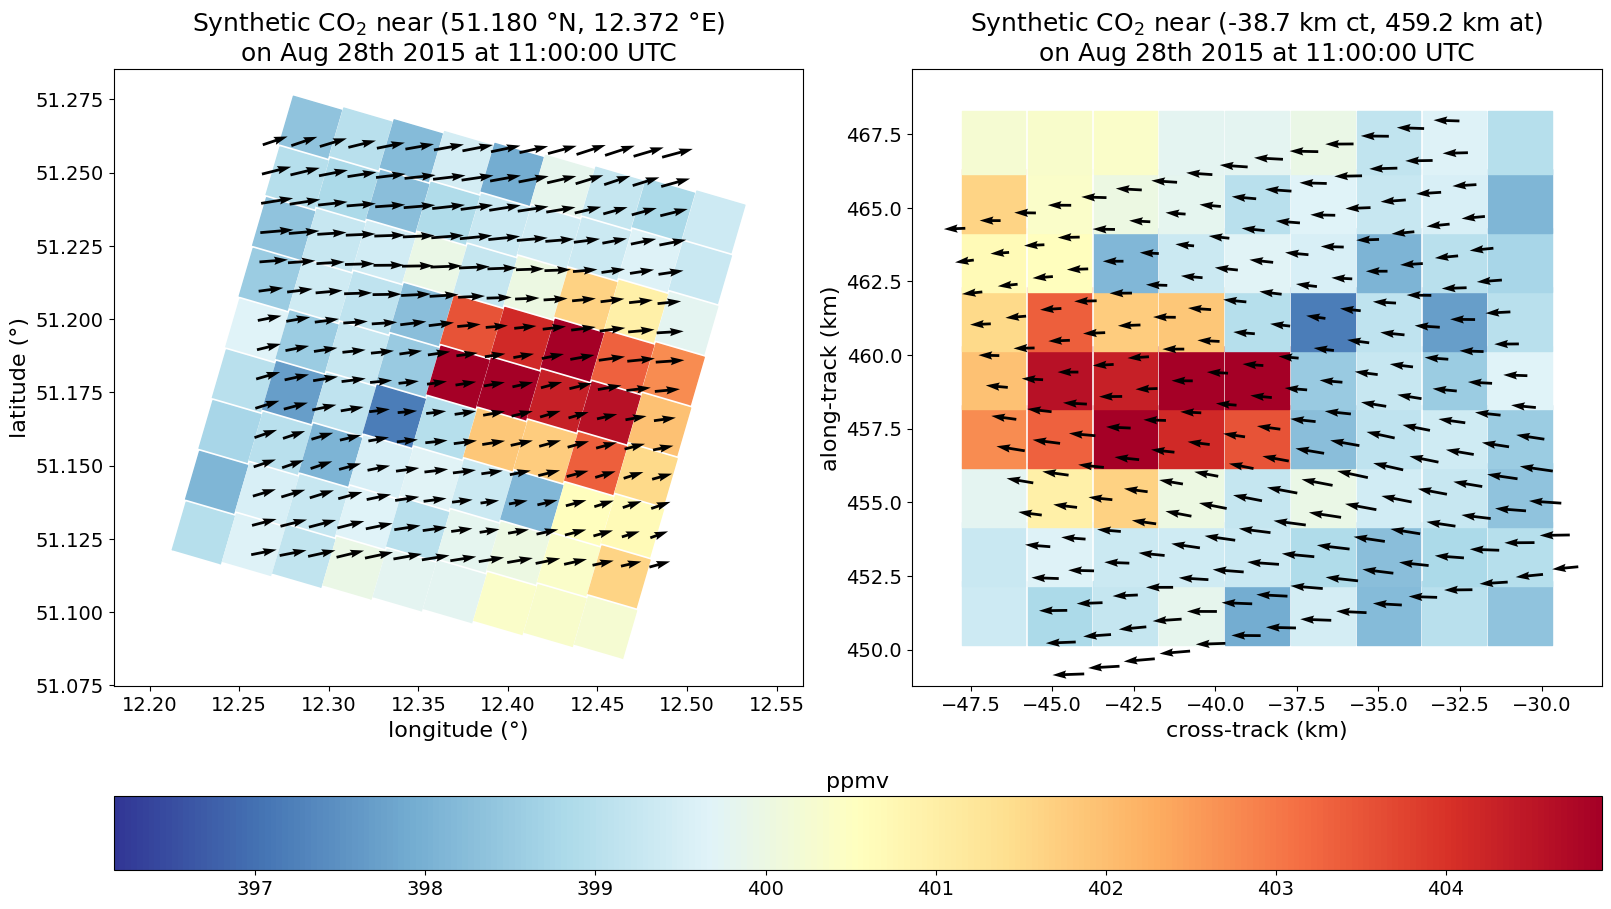

In [117]:
plot_local_overpass(overpass,source_coord,wind=wind_near_source,
                    title='default',coordinate_system='both',save=False,img_format='pdf')

In [118]:
def plot_Gcone(local_overpass,coord,surface_wind_speed,variable='CO2',
               return_msg=False,title=None,save=False):
    shape = (local_overpass.dims['nobs'], local_overpass.dims['nrows'])
    center_index = ((shape[0]-1)//2, (shape[1]-1)//2)
    nearest_index_flat = np.argmin(Earth.inverse(np.column_stack((local_overpass['lon'].data.flatten(),
                                                   local_overpass['lat'].data.flatten())),
                                   coord)[:,0])
    nearest_index = np.unravel_index(nearest_index_flat,shape)
    if nearest_index[1] in [0,shape[1]-1]:
        print('WARNING: The chosen coordinate at the egde of the overpass, Gcone cone may be unstable')
    if nearest_index[1] in [1,shape[1]-2]:
        print('WARNING: The chosen coordinate is near the egde of the overpass, Gcone may be unstable')
    if nearest_index[0] in [0,shape[0]-1]:
        print('WARNING: The chosen coordinate is at the beginning or at the end of the overpass footprint, Gcone may be unstable')
    if nearest_index[0] in [1,shape[0]-2]:
        print('WARNING: The chosen coordinate is near the beginning or near the end of the overpass footprint, Gcone may be unstable')
    local_data = local_overpass[variable].data
    if np.sum(np.isnan(local_data[center_index[0]-1:center_index[0]+2,center_index[1]-1:center_index[1]+2])) >= 4:
        print('WARNING: More than four NaN values in the vicinity of the source, Gcone may be unstable')
    if surface_wind_speed < 0.5:
        print('Note: Low surface wind speed (< 0.5 m/s), Gcone has large spread')
    if shape != (9,9):
        local_overpass = extend_overpass(local_overpass,
                                         center_index=nearest_index,
                                         target_shape=(9,9))
        shape = (9,9)
    data = local_overpass[variable].data
    ct = local_overpass['cross_track'].data
    at = local_overpass['along_track'].data
    #x_coords, y_coords = cross_track_coords.flatten(), along_track_coords.flatten()
    ctc = local_overpass['cross_track_corners'].data.reshape((-1,4))
    atc = local_overpass['along_track_corners'].data.reshape((-1,4))
    
    spread_fun = get_spread_fun(surface_wind_speed,plot_relation=False)
    grid_corners = get_corners_from_coordinates(ctc.flatten(),atc.flatten())
    attrs_keys = local_overpass.attrs.keys()
    if 'cone_corners' not in attrs_keys or 'cone_center' not in attrs_keys or 'cone_vec' not in attrs_keys:
        local_overpass = create_cone(local_overpass,surface_wind_speed)
    cone_center, cone_vec = local_overpass.attrs['cone_center'], local_overpass.attrs['cone_vec']
    cone_corners, outside_cone_corners = get_cone_corners(grid_corners,cone_center,cone_vec,
                                                          spread_fun,return_outside_cone=True)
    cone, outside_cone = Polygon(cone_corners).buffer(1e-6), Polygon(outside_cone_corners)
    
    flat_data = data.flatten()
    conc_mean, conc_std = np.nanmean(flat_data), np.nanstd(flat_data,ddof=1)
    vmin, vmax = conc_mean - 2.0*conc_std, conc_mean + 2.5*conc_std
    source_name = local_overpass['source'].data
    fig = plt.figure(figsize=(9,8),layout='compressed')
    ax = plt.gca()

    ax.set_xlabel('cross-track (km)',fontsize=16)
    ax.set_ylabel('along-track (km)',fontsize=16)
    ct_limits = (ct[:,0].mean(), ct[:,-1].mean())
    at_limits = (at[0,:].mean(), at[-1,:].mean())
    ct_min, ct_max = min(ct_limits), max(ct_limits)
    at_min, at_max = min(at_limits), max(at_limits)
    ax.set_xlim(ct_min-1.5,ct_max+1.5)
    ax.set_ylim(at_min-1.5,at_max+1.5)
    scatter = ax.scatter(ct.flatten(),at.flatten(),c=flat_data,
                         s=2800,marker='s',vmin=vmin,vmax=vmax,cmap='RdYlBu_r')
    ax.plot([cone_center[0],cone_corners[1][0]],[cone_center[1],cone_corners[1][1]],'k--')
    ax.plot([cone_center[0],cone_corners[-1][0]],[cone_center[1],cone_corners[-1][1]],'k--')
    ax.xaxis.set_tick_params(labelsize=14)
    ax.yaxis.set_tick_params(labelsize=14)
    cbar = fig.colorbar(mappable=scatter,ax=ax,orientation='vertical')
    cbar.ax.tick_params(labelsize=14)
    cbar.ax.set_title('ppmv',fontsize=16)
    date_str, time_str = str(local_overpass['time'].data).split('T')
    date_str, time_str = date_str.replace('-',''), time_str.split('.')[0].replace(':','')
    if title is not None:
        if title == 'default':
            date_str_title, time_str_title = get_datetime_str(overpass_near_source['time'].data,
                                                              fancy_str=True,split=True)
            ax.set_title(f'Gaussian cone for source "{source_name}"\non {date_str_title} at {time_str_title}',
                         fontsize=20)
        else:
            ax.set_title(title,fontsize=20)
    if save:
        datetime_str = get_datetime_str(overpass_near_source['time'].data)
        plt.savefig(f'figures/{source_name}_Gcone_{datetime_str}.png',dpi=300)
    plt.show()

Note: Low surface wind speed (< 0.5 m/s), Gcone has large spread


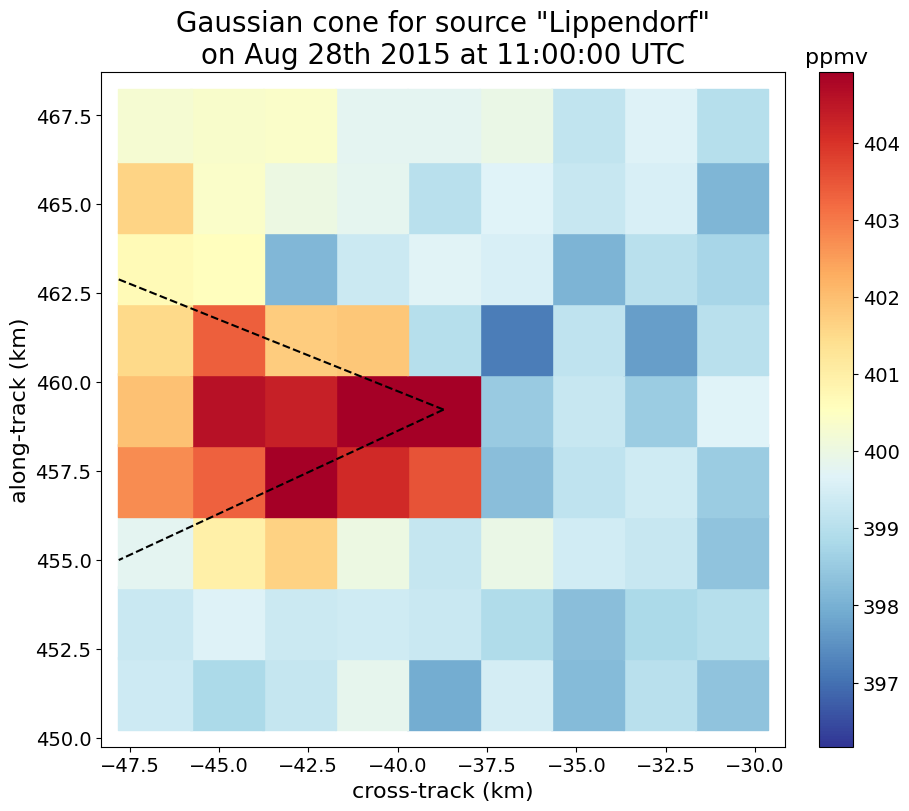

In [119]:
surface_wind_speed_near_source = get_surface_wind_speed(wind_near_source,source_coord)
if overpass_near_source is not None:
    #overpass_near_source = create_cone(overpass_near_source,surface_wind_speed_near_source,search_r=0.72)
    plot_Gcone(overpass_near_source,source_coord,
               surface_wind_speed_near_source,
               title='default',save=False)

In [120]:
def generate_data_along_centerline(overpass_near_source,variable='CO2',N=100,
                                   interpolation='nearest',backwards_extend=6.0,include_dists=True):
    grid_corners = get_corners_from_coordinates(overpass_near_source['cross_track_corners'][:,:].data.flatten(),
                                                overpass_near_source['along_track_corners'][:,:].data.flatten())
    (xc,yc), (vx,vy) = overpass_near_source.attrs['cone_center'], overpass_near_source.attrs['cone_vec']
    x_intercept, y_intercept = get_line_intercept_with_quadrilateral((xc,yc),(vx,vy),grid_corners)
    #start_point = np.subtract((xc,yc), 0.5*np.subtract((x_intercept,y_intercept),(xc,yc)))
    start_point = np.subtract((xc,yc),(backwards_extend*vx,backwards_extend*vy))
    cross_coords = overpass_near_source['cross_track'][:,:].data
    along_coords = overpass_near_source['along_track'][:,:].data
    data_coords = np.column_stack((cross_coords.flatten(),along_coords.flatten()))
    data_values = overpass_near_source[variable][:,:].data.flatten()
    if interpolation == 'nearest':
        interpolator = NearestNDInterpolator(data_coords,data_values)
    elif interpolation == 'linear':
        interpolator = LinearNDInterpolator(data_coords,data_values)
    else:
        raise ValueError(f'Invalid interpolation option {interpolation}')
    if x_intercept == xc:
        interpolated_x = np.full(N,xc)
        interpolated_y = np.linspace(start_point[1],y_intercept,N)
    else:
        interpolated_x = np.linspace(start_point[0],x_intercept,N)
        interpolated_y = vy/vx*(interpolated_x-xc) + yc
    interpolated_coords = np.column_stack((interpolated_x,interpolated_y))
    interpolated_values = interpolator(interpolated_coords)
    if not include_dists:
        return interpolated_coords, interpolated_values
    else:
        vecs = interpolated_coords - np.array([(xc,yc)])
        vec_norms = np.linalg.norm(vecs,axis=1)
        arccos_arg = np.dot(vecs,(vx,vy)) / (np.linalg.norm((vx,vy)) * vec_norms)
        arccos_arg[arccos_arg < -1.0] = -1.0
        arccos_arg[arccos_arg > 1.0] = 1.0
        angles = np.arccos(arccos_arg)
        is_neg_dists = np.isclose(angles,np.pi)
        dists = vec_norms
        dists[is_neg_dists] *= -1.0
        return dists, interpolated_coords, interpolated_values

def plot_along_centerline(overpass_near_source,variable='CO2',N=500,mean_func=None,
                          mu_adjustment=0.0,pred_func=None,save=False):
    dists, interpolated_coords, interpolated_values = generate_data_along_centerline(overpass_near_source,
                                                                                     variable=variable,
                                                                                     N=N)
    # Plotting
    cross_coords = overpass_near_source['cross_track'].data
    along_coords = overpass_near_source['along_track'].data
    grid_corners = get_corners_from_coordinates(overpass_near_source['cross_track_corners'].data.flatten(),
                                                overpass_near_source['along_track_corners'].data.flatten())
    (xc,yc), (vx,vy) = overpass_near_source.attrs['cone_center'], overpass_near_source.attrs['cone_vec']
    x_intercept, y_intercept = get_line_intercept_with_quadrilateral((xc,yc),(vx,vy),grid_corners)
    
    data_values = overpass_near_source[variable][:,:].data.flatten()
    source_name = overpass_near_source['source'].data
    conc_mean, conc_std = np.nanmean(data_values), np.nanstd(data_values,ddof=1)
    vmin, vmax = conc_mean - 2.0*conc_std, conc_mean + 2.5*conc_std
    fig, (ax_area, ax_centerline) = plt.subplots(nrows=1,ncols=2,figsize=(18,8),layout='compressed')
    ax_area.set_title(f'Plume center line for {source_name}',fontsize=18)
    ax_area.set_xlabel('cross-track (km)',fontsize=16)
    ax_area.set_ylabel('along-track (km)',fontsize=16)
    ax_area.xaxis.set_tick_params(labelsize=14)
    ax_area.yaxis.set_tick_params(labelsize=14)
    #width, height = cross_coords.max() - cross_coords.min(), along_coords.max() - along_coords.min()
    ax_area.set_xlim(cross_coords.min()-1.6,cross_coords.max()+1.6)
    ax_area.set_ylim(along_coords.min()-1.6,along_coords.max()+1.6)
    scatter = ax_area.scatter(cross_coords.flatten(),
                              along_coords.flatten(),
                              c=data_values,
                              s=2750,marker='s',vmin=vmin,vmax=vmax,cmap='RdYlBu_r')
    start_point = interpolated_coords[0]
    ax_area.plot([start_point[0],x_intercept],[start_point[1],y_intercept],'k-')
    
    ax_centerline.plot(dists,interpolated_values,'k-',label='obs')
    if mean_func is not None:
        mean_vals = mean_func(interpolated_coords) + mu_adjustment
        ax_centerline.plot(dists,mean_vals,'k--',label='mean func')
    if pred_func is not None:
        pred_vals = pred_func(interpolated_coords)
        ax_centerline.plot(dists,pred_vals,'r--',label='pred func')
        
    ax_centerline.set_xlabel('along plume distance (km)',fontsize=16)
    ax_centerline.set_ylabel('concentration (ppm)',fontsize=16)
    ax_centerline.xaxis.set_tick_params(labelsize=14)
    ax_centerline.yaxis.set_tick_params(labelsize=14)
    ax_centerline.legend(fontsize=16)
    
    cbar = fig.colorbar(mappable=scatter,ax=ax_area,orientation='vertical')
    cbar.ax.tick_params(labelsize=14)
    cbar.ax.set_title('ppmv',fontsize=16)
    date_str, time_str = str(overpass_near_source['time'].data).split('T')
    date_str, time_str = date_str.replace('-',''), time_str.split('.')[0].replace(':','')
    if save:
        plt.savefig(f'figures/{source_name}_centerline_{date_str}T{time_str}.png',dpi=300)
    else:
        plt.show()

In [121]:
def pairwise_distances(coords_rows, coords_cols):
    # Construct pair-wise distances given two coordinate-arrays
    dx = coords_rows[:, np.newaxis, 0] - coords_cols[np.newaxis, :, 0]
    dy = coords_rows[:, np.newaxis, 1] - coords_cols[np.newaxis, :, 1]
    return dx, dy

def scaled_distance_matrix(dx, dy, lx=1.0, ly=1.0, alpha=0.0):
    cosa = np.cos(alpha)
    sina = np.sin(alpha)
    scaled_dist_squared = (dx*cosa-dy*sina)**2/lx**2 + (dx*sina+dy*cosa)**2/ly**2
    return np.sqrt(scaled_dist_squared)

In [122]:
def brute_force_search(func,hypercube_bounds,N=2,return_new_bounds=True):
    for dim_bounds in hypercube_bounds:
        if dim_bounds[0] >= dim_bounds[1]:
            raise ValueError('The first bound must be smaller than the second')
    dim = len(hypercube_bounds)
    hypercube_bounds = np.array(hypercube_bounds)
    x = hypercube_bounds.mean(axis=1)
    f_val = func(x)
    bounds_lower, bounds_upper = hypercube_bounds.T
    cube_side_lengths = bounds_upper - bounds_lower
    elements = np.linspace(bounds_lower,bounds_upper,N+2,axis=1)
    if return_new_bounds:
        new_bounds = hypercube_bounds
        indices = list(product(range(N),repeat=dim))
    candidates = list(product(*elements[:,1:-1]))
    for n in range(len(candidates)):
        candidate = candidates[n]
        f_candidate = func(candidate)
        if f_candidate < f_val:
            x, f_val = candidate, f_candidate
            if return_new_bounds:
                index_arr = np.array(indices[n],dtype=np.uint32) + 1
                new_lower_ind = index_arr - 1
                new_upper_ind = index_arr + 1
                new_bounds = np.column_stack((elements[np.arange(dim,dtype=np.uint32),new_lower_ind],
                                              elements[np.arange(dim,dtype=np.uint32),new_upper_ind]))
    return (x, new_bounds) if return_new_bounds else x

def bootleg_gd(target,x_init,alpha_init=0.01,max_jumps=4,bounds=None):
        if bounds is not None:
            bounds_lower, bounds_upper = np.array(bounds).T
        x = x_init
        f,g = target(x_init)
        x_str = '[' + ', '.join([f'{xn:.3f}' for xn in x_init]) + ']'
        g_str = '[' + ', '.join([f'{g_component:.3f}' for g_component in g]) + ']'
        #print(f'Init x ≈ {x_str}')
        #print(f'Initial f ≈ {f:.3f} and g ≈ {g_str}')
        successful_jumps = 0
        failed_jumps = 0
        while successful_jumps < max_jumps:
            try:
                alpha = alpha_init / (2.0**failed_jumps + 0.1*successful_jumps)
            except OverflowError:
                return x
            x_next = np.add(x,np.multiply(-alpha,g))
            if bounds is not None:
                if np.any(x_next < bounds_lower) or np.any(x_next > bounds_upper):
                    failed_jumps += 1
                    continue
            f_next,g_next = target(x_next)
            if f_next > f:
                failed_jumps += 1
                continue
            failed_jumps = 0
            x = x_next
            f,g = f_next,g_next
            successful_jumps += 1
        x_str = '[' + ', '.join([f'{xn:.3f}' for xn in x]) + ']'
        g_str = '[' + ', '.join([f'{gn:.3f}' for gn in g]) + ']'
        #print(f'Final x ≈ {x_str}')
        #print(f'Final f ≈ {f:.3f} and g ≈ {g_str}')
        return x

In [123]:
def neg_log_prior_wind(params,include_gradient=True,separate_noise=True):
    if separate_noise:
        sig, l, mu1, mu2, sig_n1, sig_n2 = params
    else:
        sig, l, mu1, mu2, sig_n = params
    # Log-Normal prior for σ
    m_sig, s_sig = 0.4, 0.8
    neg_log_prior_sig = np.log(sig) + np.log(s_sig) + 0.5*(np.log(sig)-m_sig)**2/s_sig**2 + 0.5*np.log(2.0*np.pi)
    # Log-Normal prior for l
    m_l, s_l = 1.2, 0.6
    neg_log_prior_l = np.log(l) + np.log(s_l) + 0.5*(np.log(l)-m_l)**2/s_l**2 + 0.5*np.log(2.0*np.pi)
    # Log-Normal prior for σₙ
    #m_sig_n, s_sig_n = -1.2, 0.6
    #neg_log_prior_sig_n = np.log(sig_n) + np.log(s_sig_n) + 0.5*(np.log(sig_n)-m_sig_n)**2/s_sig_n**2 + 0.5*np.log(2.0*np.pi)
    
    #m,s = m_sig_n, s_sig_n
    #print('mean:', np.exp(m+0.5*s**2))
    #print('std:', np.exp(m+0.5*s**2) * np.sqrt(np.exp(s**2)-1.0))
    
    # Sum to function
    f = neg_log_prior_sig + neg_log_prior_l #+ neg_log_prior_sig_n
    if not include_gradient:
        return f
    else:
        # Gradient
        g_hyperparams = (1.0/sig+(np.log(sig)-m_sig)/(sig*s_sig**2),
                         1.0/l+(np.log(l)-m_l)/(l*s_l**2))
        if separate_noise:
            g = np.concatenate((g_hyperparams,np.zeros(4)))
        else:
            g = np.concatenate((g_hyperparams,np.zeros(3)))
        return (f, g)
    
def neg_log_likelihood_wind(params,dx,dy,data_vec,include_gradient=True,separate_noise=True):
    N = len(data_vec) // 2
    if separate_noise:
        sig, l, mu1, mu2, sig_n1, sig_n2 = params
    else:
        sig, l, mu1, mu2, sig_n = params
    
    scaled_dx, scaled_dy = dx / l, dy / l
    exp_dmat = np.exp(-0.5*(scaled_dx**2 + scaled_dy**2))
    # Blocks of the full kernel matrix
    if separate_noise:
        Y = sig**2/l**2 * (1.0-scaled_dy**2) * exp_dmat + sig_n1**2*np.eye(N)
        X = sig**2/l**2 * (1.0-scaled_dx**2) * exp_dmat + sig_n2**2*np.eye(N)
    else:
        Y = sig**2/l**2 * (1.0-scaled_dy**2) * exp_dmat + sig_n**2*np.eye(N)
        X = sig**2/l**2 * (1.0-scaled_dx**2) * exp_dmat + sig_n**2*np.eye(N)
    C = -sig**2/l**2 * scaled_dx * scaled_dy * exp_dmat
    # Inverse of the matrix [[Y,-C],[-C,X]] using Schur complement
    Y_inv = solve(Y,np.eye(N),check_finite=False,assume_a='pos')
    S = X - C @ Y_inv @ C
    S_inv = solve(S,np.eye(N),check_finite=False,assume_a='pos')
    # Inverse of the full kernel matrix
    temp_left = Y_inv @ C
    temp_right = C @ Y_inv
    Kn_inv = np.block([[Y_inv + temp_left @ S_inv @ temp_right, temp_left @ S_inv],
                       [S_inv @ temp_right, S_inv]])
    # Determinant of the block kernel matrix
    log_determinant = fast_logdet(Y) + fast_logdet(S)
    
    mu_vec = np.concatenate((np.full(N,mu1),np.full(N,mu2)))
    temp = Kn_inv @ (data_vec-mu_vec)
    
    f = 0.5 * ((data_vec-mu_vec).dot(temp) + log_determinant + 2*N*np.log(2*np.pi))
    if not include_gradient:
        return f
    # Partial derivatives w.r.t. the parameters
    K_dsig = np.block([[2.0*sig/l**2 * (1.0-scaled_dy**2) * exp_dmat, 2.0*sig/l**2 * scaled_dx * scaled_dy * exp_dmat],
                       [2.0*sig/l**2 * scaled_dx * scaled_dy * exp_dmat, 2.0*sig/l**2 * (1.0-scaled_dx**2) * exp_dmat]])
    K_dl = np.block([[sig**2/l**3 * (5.0*scaled_dy**2 + scaled_dx**2 - scaled_dy**2*scaled_dx**2 - scaled_dy**4 - 2.0) * exp_dmat,
                      sig**2/l**3 * scaled_dy * scaled_dx * (scaled_dx**2 + scaled_dy**2 - 4.0) * exp_dmat],
                     [sig**2/l**3 * scaled_dx * scaled_dy * (scaled_dx**2 + scaled_dy**2 - 4.0) * exp_dmat, 
                      sig**2/l**3 * (5.0*scaled_dx**2 + scaled_dy**2 - scaled_dx**2*scaled_dy**2 - scaled_dx**4 - 2.0) * exp_dmat]])
    g_hyperparams = (-0.5 * temp @ K_dsig @ temp + 0.5*np.sum(np.diag(Kn_inv @ K_dsig)),
                     -0.5 * temp @ K_dl @ temp + 0.5*np.sum(np.diag(Kn_inv @ K_dl)))
    g_dmu1 = np.sum(Kn_inv[:N,:N] @ (data_vec[:N] - mu1) - Kn_inv[N:,:N] @ (data_vec[N:] - mu2))
    g_dmu2 = np.sum(Kn_inv[N:,N:] @ (data_vec[N:] - mu2) - Kn_inv[:N,N:] @ (data_vec[:N] - mu1))
    if separate_noise:
        K_dnoise1 = np.block([[2.0*sig_n1*np.eye(N), np.zeros((N,N))],
                              [np.zeros((N,N)), np.zeros((N,N))]])
        K_dnoise2 = np.block([[np.zeros((N,N)), np.zeros((N,N))],
                              [np.zeros((N,N)), 2.0*sig_n2*np.eye(N)]])
        g_dnoise1 = -0.5 * temp @ K_dnoise1 @ temp + 0.5 * np.sum(np.diag(Kn_inv @ K_dnoise1))
        g_dnoise2 = -0.5 * temp @ K_dnoise2 @ temp + 0.5 * np.sum(np.diag(Kn_inv @ K_dnoise2))
        g = np.concatenate((g_hyperparams,[g_dmu1,g_dmu2,g_dnoise1,g_dnoise2]))
    else:
        g_dnoise = -sig_n*np.sum(temp**2) + sig_n*np.sum(np.diag(Kn_inv))
        g = np.concatenate((g_hyperparams,[g_dmu1,g_dmu2,g_dnoise]))
    return (f, g)

def optimize_windGP(coords_train,data_train,return_msg=False,print_params=False,separate_noise=True):
    # Wind GP params: σ, l, μₓ, μᵧ, σₙ
    dx_train, dy_train = pairwise_distances(coords_train,coords_train)
    N = len(data_train) // 2
    
    def target(params,include_gradient=True):
        if include_gradient:
            # Negative log-likelihood including gradient
            nllh_f, nllh_g = neg_log_likelihood_wind(params,dx_train,dy_train,data_train,
                                                     include_gradient=True,separate_noise=separate_noise)
            # Negative log-prior including gradient
            nlp_f, nlp_g = neg_log_prior_wind(params,include_gradient=True,
                                              separate_noise=separate_noise)
            return (nllh_f+nlp_f, nllh_g+nlp_g)
        else:
            nllh_f = neg_log_likelihood_wind(params,dx_train,dy_train,data_train,
                                             include_gradient=False,separate_noise=separate_noise)
            nlp_f = neg_log_prior_wind(params,include_gradient=False,
                                       separate_noise=separate_noise)
            return nllh_f + nlp_f

    mean_first, mean_second = data_train[:N].mean(),data_train[N:].mean()
    std_first, std_second = data_train[:N].std(ddof=1), data_train[N:].std(ddof=1)
    
    bounds = [(1.1,4.1),(2.0,6.0),
              (mean_first-1.8*std_first,mean_first+1.8*std_first),
              (mean_second-1.8*std_second,mean_second+1.8*std_second),
              (0.01,1.3)]
    if separate_noise:
        bounds.append((0.01,1.3))

    target_without_grad = lambda x: target(x,include_gradient=False)
    init_vec, new_bounds = brute_force_search(target_without_grad,bounds,return_new_bounds=True)
    max_attempts = 6
    new_bounds = bounds
    for attempt in range(1,max_attempts+1):
        init_vec = bootleg_gd(target,init_vec,alpha_init=0.005,bounds=bounds)
        res = minimize(target,
                       x0=init_vec,
                       method='L-BFGS-B',
                       jac=True,
                       bounds=bounds,
                       options={'disp':False,'ftol':0.01,'gtol':0.1})
        success = res.success
        if success:
            opt, func_val = res.x, res.fun
            break    
        init_vec, new_bounds = brute_force_search(target_without_grad,new_bounds,return_new_bounds=True)
        if attempt == max_attempts:
            if print_params:
                print(f'Wind GP optimization failed, defaulting to brute force search')
            opt = brute_force_search(target_without_grad,new_bounds,return_new_bounds=False)
            func_val = target_without_grad(opt)
            success = True
    if print_params:
        if separate_noise: 
            params_str = f'σ: {opt[0]:.3f}, l: {opt[1]:.3f}, μvₓ: {opt[2]:.3f}, μvᵧ: {opt[3]:.3f}, nₓ: {opt[-2]:.3f}, nᵧ: {opt[-1]:.3f}'
        else:
            params_str = f'σ: {opt[0]:.3f}, l: {opt[1]:.3f}, μvₓ: {opt[2]:.3f}, μvᵧ: {opt[3]:.3f}, n: {opt[-1]:.3f}'
        print(f'Wind GP params:\n{params_str}')
        print(f'Func val: {func_val:.3f}')
        
    if separate_noise:
        kernel_params, mu1, mu2, sig_n1, sig_n2 = opt[:2], opt[2], opt[3], opt[-2], opt[-1]
    else:
        kernel_params, mu1, mu2, sig_n = opt[:2], opt[2], opt[3], opt[-1]
        
    sig, l = kernel_params
    scaled_dx, scaled_dy = dx_train / l, dy_train / l
    # Construct kernel matrix with optimal parameters
    if separate_noise:
        Y = sig**2/l**2 * (1.0-scaled_dy**2) * np.exp(-0.5*(scaled_dx**2+scaled_dy**2)) + sig_n1**2*np.eye(N)
        X = sig**2/l**2 * (1.0-scaled_dx**2) * np.exp(-0.5*(scaled_dx**2+scaled_dy**2)) + sig_n2**2*np.eye(N)
    else:
        Y = sig**2/l**2 * (1.0-scaled_dy**2) * np.exp(-0.5*(scaled_dx**2+scaled_dy**2)) + sig_n**2*np.eye(N)
        X = sig**2/l**2 * (1.0-scaled_dx**2) * np.exp(-0.5*(scaled_dx**2+scaled_dy**2)) + sig_n**2*np.eye(N)
    C = -sig**2/l**2 * scaled_dx * scaled_dy * np.exp(-0.5*(scaled_dx**2+scaled_dy**2))
    # Inverse of the matrix [[Y,-C],[-C,X]] using Schur complement
    Y_inv = solve(Y,np.eye(N),check_finite=False,assume_a='pos')
    S = X - C @ Y_inv @ C
    S_inv = solve(S,np.eye(N),check_finite=False,assume_a='pos')
    temp_left = Y_inv @ C
    temp_right = C @ Y_inv
    Kn_inv = np.block([[Y_inv + temp_left @ S_inv @ temp_right, temp_left @ S_inv],
                       [S_inv @ temp_right, S_inv]])
    if return_msg:
        msg = 'Wind GP optimization successfull'
        return success, kernel_params, mu1, mu2, Kn_inv, msg
    else:
        return success, kernel_params, mu1, mu2, Kn_inv

def windGP_constructor(wind,absolute_wind_unc=1.0,return_success=False,print_params=False):
    cross_track = wind['cross_track'].data.flatten()
    along_track = wind['along_track'].data.flatten()
    coords_train = np.column_stack((cross_track,along_track))
    #dx_train, dy_train = pairwise_distances(training_coords,training_coords)
    data_train = np.concatenate((wind['VXeff'].data.flatten(),wind['VYeff'].data.flatten()))
    success, kernel_params, mu1, mu2, Kn_inv = optimize_windGP(coords_train,data_train,print_params=print_params)
    sig, l = kernel_params
    mu_vec = np.concatenate((np.full(len(coords_train),mu1),np.full(len(coords_train),mu2)))
    # Construct the evaluator
    def windGP_evaluator(coords_eval,include_cov=False):
        mu_eval = np.concatenate((np.full(len(coords_eval),mu1),np.full(len(coords_eval),mu2)))
        dx_eval_to_train, dy_eval_to_train = pairwise_distances(coords_eval,coords_train)
        scaled_dx_eval_to_train, scaled_dy_eval_to_train = dx_eval_to_train / l, dy_eval_to_train / l
        exp_coef_eval_to_train = np.exp(-0.5*(scaled_dx_eval_to_train**2 + scaled_dy_eval_to_train**2))
        #square_dists = dx_eval_to_train**2 + dy_eval_to_train**2
        Y_eval_to_train = sig**2/l**2 * (1.0-scaled_dy_eval_to_train**2) * exp_coef_eval_to_train
        X_eval_to_train = sig**2/l**2 * (1.0-scaled_dx_eval_to_train**2) * exp_coef_eval_to_train
        C_eval_to_train = -sig**2/l**2 * scaled_dx_eval_to_train * scaled_dy_eval_to_train * exp_coef_eval_to_train
        K_eval_to_train = np.block([[Y_eval_to_train, -C_eval_to_train],
                                    [-C_eval_to_train, X_eval_to_train]])
        expect = mu_eval + K_eval_to_train @ (Kn_inv @ (data_train - mu_vec))
        if include_cov:
            dx_eval_to_eval, dy_eval_to_eval = pairwise_distances(coords_eval,coords_eval)
            scaled_dx_eval_to_eval, scaled_dy_eval_to_eval = dx_eval_to_eval / l, dy_eval_to_eval / l
            exp_coef_eval_to_eval = np.exp(-0.5*(scaled_dx_eval_to_eval**2 + scaled_dy_eval_to_eval**2))
            Y_eval_to_eval = sig**2/l**2 * (1.0-scaled_dy_eval_to_eval**2) * exp_coef_eval_to_eval
            X_eval_to_eval = sig**2/l**2 * (1.0-scaled_dx_eval_to_eval**2) * exp_coef_eval_to_eval
            C_eval_to_eval = -sig**2/l**2 * scaled_dx_eval_to_eval * scaled_dy_eval_to_eval * exp_coef_eval_to_eval
            K_eval_to_eval = np.block([[Y_eval_to_eval, -C_eval_to_eval],
                                       [-C_eval_to_eval, X_eval_to_eval]])
            cov = K_eval_to_eval - K_eval_to_train @ Kn_inv @ K_eval_to_train.T
            cov += np.diag(np.full(len(expect),absolute_wind_unc**2))
            return expect,cov
        else:
            return expect
    return (windGP_evaluator,success) if return_success else windGP_evaluator

In [124]:
windGP_evaluator = windGP_constructor(wind_near_source,print_params=True)

Wind GP params:
σ: 2.085, l: 4.682, μvₓ: -2.359, μvᵧ: 0.258, nₓ: 0.171, nᵧ: 0.131
Func val: -167.890


In [125]:
def get_psurf_interpolator(overpass,remove_nans=True):
    xy_coords = np.column_stack((overpass['cross_track'].data.flatten(),
                                 overpass['along_track'].data.flatten()))
    try:
        psurf_data = overpass['psurf'].data.flatten()
        if remove_nans:
            nan_mask = np.isnan(psurf_data)
        interpolator = RBFInterpolator(xy_coords[~nan_mask], psurf_data[~nan_mask], 
                                       smoothing=0.05, kernel='gaussian', 
                                       epsilon=2.5, degree=0)
    except ValueError:
        mean_pressure = psurf_data[nan_mask].mean()
        interpolator = lambda coords: np.full(len(coords),mean_pressure)
    return interpolator

def Matern(dmat,sigma=1.0,nu='5/2'):
    if nu == '1/2':
        poly_dmat = np.ones_like(dmat)
        exp_dmat = np.exp(-dmat)
    elif nu == '3/2':
        poly_dmat = np.ones_like(dmat)+np.sqrt(3)*dmat
        exp_dmat = np.exp(-np.sqrt(3)*dmat)
    elif nu == '5/2':
        poly_dmat = np.ones_like(dmat)+np.sqrt(5)*dmat+5/3*dmat**2
        exp_dmat = np.exp(-np.sqrt(5)*dmat)
    else:
        raise ValueError(f'Option nu={nu} not implemented')
    return sigma**2*poly_dmat*exp_dmat

def neg_log_prior_conc(params,mu_included=True,include_gradient=True):
    if mu_included:
        sig, lx, ly, mu, sig_n = params
        neg_log_prior_mu = 0.0
    else:
        sig, lx, ly, sig_n = params
        alpha, mu = np.nan, np.nan
        neg_log_prior_mu = 0.0
    # LogNormal prior for σ
    m_sig, s_sig = 0.1, 0.7
    neg_log_prior_sig = np.log(sig) + np.log(s_sig) + 0.5*(np.log(sig)-m_sig)**2/s_sig**2 + 0.5*np.log(2*np.pi)
    # LogNormal prior for lₓ
    m_lx, s_lx = 0.8, 0.5
    neg_log_prior_lx = np.log(lx) + np.log(s_lx) + 0.5*(np.log(lx)-m_lx)**2/s_lx**2 + 0.5*np.log(2*np.pi)
    # LogNormal prior for lᵧ
    m_ly, s_ly = 0.4, 0.3
    neg_log_prior_ly = np.log(ly) + np.log(s_ly) + 0.5*(np.log(ly)-m_ly)**2/s_ly**2 + 0.5*np.log(2*np.pi)
    
    #m, s = m_lx, s_lx
    #print('mean:', np.exp(m+0.5*s**2))
    #print('std:', np.exp(m+0.5*s**2) * np.sqrt(np.exp(s**2)-1.0))
    # Sum to function
    f = neg_log_prior_sig + neg_log_prior_lx + neg_log_prior_ly
    if include_gradient:
        if mu_included:
            g = (1.0/sig+(np.log(sig)-m_sig)/(sig*s_sig**2), 
                 1.0/lx+(np.log(lx)-m_lx)/(lx*s_lx**2),
                 1.0/ly+(np.log(ly)-m_ly)/(ly*s_ly**2),
                 0.0,
                 0.0
                )
        else:
            g = (1.0/sig+(np.log(sig)-m_sig)/(sig*s_sig**2), 
                 1.0/lx+(np.log(lx)-m_lx)/(lx*s_lx**2),
                 1.0/ly+(np.log(ly)-m_ly)/(ly*s_ly**2),
                 0.0
                )
        return f, np.array(g)
    else:
        return f
    
def neg_log_likelihood_conc(params,dx,dy,data_vec,alpha,mu_vec=None,adjust_mu=True,
                            include_gradient=True,nu='5/2'):
    if adjust_mu:
        sig, lx, ly, mu, sig_n = params
        mu_vec = np.full(mu,len(data_vec)) if mu_vec is None else mu_vec + mu 
    else:
        sig, lx, ly, sig_n = params
        if mu_vec is None:
            mu_vec = np.zeros(len(data_vec))
    sina, cosa = np.sin(alpha), np.cos(alpha)
    dmat = scaled_distance_matrix(dx,dy,lx=lx,ly=ly,alpha=alpha)
    Kn = Matern(dmat,sigma=sig,nu=nu) + sig_n**2*np.eye(len(data_vec)) 
    Kn_inv = solve(Kn,np.eye(len(data_vec)),check_finite=False,assume_a='pos')
    temp = Kn_inv @ (data_vec-mu_vec)
    f = 0.5 * ((data_vec-mu_vec).dot(temp) + fast_logdet(Kn) + len(data_vec)*np.log(2*np.pi))
    if include_gradient:
        if nu == '1/2':
            raise ValueError(f'Gradient of the Matern covariance with ν={nu} not possible to compute')
        elif nu == '3/2':
            exp_dmat = np.exp(-np.sqrt(3.0)*dmat)
            K_dsig = 2.0*sig*(np.ones_like(K) + np.sqrt(3.0)*dmat) * exp_dmat
            K_dlx = 3.0*sig**2/lx**3*exp_dmat*(dx*cosa-dy*sina)**2
            K_dly = 3.0*sig**2/ly**3*exp_dmat*(dx*sina+dy*cosa)**2
        elif nu == '5/2':
            affine_dmat = np.ones_like(Kn) + np.sqrt(5.0)*dmat
            exp_dmat = np.exp(-np.sqrt(5.0)*dmat)
            K_dsig = 2.0*sig*(affine_dmat+5.0/3.0*dmat**2)*exp_dmat
            K_dlx = 5.0/3.0*sig**2/lx**3*affine_dmat*exp_dmat*(dx*cosa-dy*sina)**2
            K_dly = 5.0/3.0*sig**2/ly**3*affine_dmat*exp_dmat*(dx*sina+dy*cosa)**2
        g_sig = -0.5*temp @ K_dsig @ temp + 0.5*np.sum(np.diag(Kn_inv @ K_dsig))
        g_lx = -0.5*temp @ K_dlx @ temp + 0.5*np.sum(np.diag(Kn_inv @ K_dlx))
        g_ly = -0.5*temp @ K_dly @ temp + 0.5*np.sum(np.diag(Kn_inv @ K_dly))
        g_sig_n = -sig_n*np.sum(temp**2) + sig_n*np.sum(np.diag(Kn_inv))
        if adjust_mu:
            g = (g_sig,g_lx,g_ly,np.sum(temp),g_sig_n)
        else: 
            g = (g_sig,g_lx,g_ly,g_sig_n)
        return (f, np.array(g))
    else:
        return f

def optimize_concGP(coords_train,data_train,constant_mu=None,mean_func=None,plume_direction=None,
                    return_msg=False,print_params=False,nu='5/2'):
    if plume_direction is None:
        raise ValueError('Plume direction kwarg must be provided')
    
    N = len(coords_train)
    mean, std = data_train.mean(), data_train.std(ddof=1)
    dx_train, dy_train = pairwise_distances(coords_train,coords_train)
    
    lx_min, lx_init, lx_max = 1.7, 2.6, 3.7
    ly_min, ly_init, ly_max = 1.0, 1.6, 2.2
    fit_mu = constant_mu is None
    if fit_mu:
        # Params: σ, lₓ, lᵧ, μ
        init_params = [0.5*std,lx_init,ly_init,0.0]
        bounds = [(0.1*std,1.4*std),(lx_min,lx_max),(ly_min,ly_max),(-5.0,5.0)]
    else:
        # Params: σ, lₓ, lᵧ 
        std = data_train.std(ddof=1)
        data_train = data_train - constant_mu
        init_params = [0.5*std,lx_init,ly_init]
        bounds = [(0.1*std,1.4*std),(lx_min, lx_max),(ly_min,ly_max)]
    
    alpha = -plume_direction
    sig_n_init = 0.5
    init_params.append(sig_n_init)
    bounds.append((0.1,1.5))
    
    if fit_mu and mean_func is None:
        mu_vec = np.zeros(N)
    elif not fit_mu and mean_func is None:
        mu_vec = np.full(N,constant_mu)
    elif fit_mu and mean_func is not None:
        mu_vec = mean_func(coords_train)
    else:
        mu_vec = np.full(N,constant_mu) + mean_func(coords_train)

    # WARNING: optimization can be unstable
    def target(params,include_gradient=True):
        if include_gradient:
            # Negative log-likelihood
            nllh_f, nllh_g = neg_log_likelihood_conc(params,dx_train,dy_train,data_train,alpha,mu_vec=mu_vec,
                                                     adjust_mu=fit_mu,include_gradient=True,nu=nu)
            #  Negative log-prior value and gradient 
            nlp_f, nlp_g = neg_log_prior_conc(params,mu_included=fit_mu,include_gradient=True)
            return (nllh_f+nlp_f, nllh_g+nlp_g)
        else:
            nllh_f = neg_log_likelihood_conc(params,dx_train,dy_train,data_train,alpha,mu_vec=mu_vec,
                                             adjust_mu=fit_mu,include_gradient=False,nu=nu)
            nlp_f = neg_log_likelihood_conc(params,dx_train,dy_train,data_train,alpha,mu_vec=mu_vec,
                                            adjust_mu=fit_mu,include_gradient=False,nu=nu)
            return nllh_f+nlp_f
        
    target_without_grad = lambda x: target(x,include_gradient=False)
    init_vec, new_bounds = brute_force_search(target_without_grad,bounds,return_new_bounds=True)
    max_attempts = 6
    for attempt in range(1,max_attempts+1):
        init_vec = bootleg_gd(target,init_vec,alpha_init=0.005,bounds=bounds)
        res = minimize(target,
                       x0=init_vec,
                       method='L-BFGS-B',
                       jac=True,
                       bounds=bounds,
                       options={'maxiter':50,'disp':False,'maxcor':100,'ftol':0.01,'norm':2.0})
        success = res.success
        if success:
            opt, func_val = res.x, res.fun
            break
        init_vec, new_bounds = brute_force_search(target_without_grad,new_bounds,N=3,return_new_bounds=True)
        if attempt == max_attempts:
            if print_params:
                print('Conc GP optimization failed, defaulting to brute force search')
            opt = brute_force_search(target_without_grad,new_bounds,N=3,return_new_bounds=False)
            func_val = target_without_grad(opt)
            success = True
    if print_params:
        if fit_mu:
            params_str = f'σ: {opt[0]:.3f}, lₓ: {opt[1]:.3f}, lᵧ: {opt[2]:.3f}, μ: {opt[-2]:.3f}, σₙ: {opt[-1]:.3f}'
        else:
            params_str = f'σ: {opt[0]:.3f}, lₓ: {opt[1]:.3f}, lᵧ: {opt[2]:.3f}, σₙ: {opt[-1]:.3f}'
        print(f'Conc GP params:\n{params_str}')
        print(f'func val: {func_val:.3f}')
    if constant_mu is None:
        kernel_params, mu_fitted, sig_n = opt[:-2], opt[-2], opt[-1]
    else:
        kernel_params, sig_n = opt[:-1], opt[-1]
    sig_opt, lx_opt, ly_opt = kernel_params
    scaled_dmat = scaled_distance_matrix(dx_train,dy_train,lx=lx_opt,ly=ly_opt,alpha=alpha)
    Kn = Matern(scaled_dmat,sigma=sig_opt,nu=nu) + sig_n**2*np.eye(N)
    Kn_inv = solve(Kn,np.eye(N),check_finite=False,assume_a='pos')
    msg = 'Conc GP optimization successfull'
    if return_msg and constant_mu is None:
        return True,kernel_params,mu_fitted,Kn_inv,msg
    elif not return_msg and constant_mu is None:
        return True,kernel_params,mu_fitted,Kn_inv
    elif return_msg and constant_mu is not None:
        return True,kernel_params,Kn_inv,msg
    else:
        return True,kernel_params,Kn_inv
    
def mean_func_constructor(overpass_near_source,variable='CO2',style='constant'):
    training_data = overpass_near_source[variable][:,:].data.flatten()
    training_coords = np.column_stack((overpass_near_source['cross_track'][:,:].data.flatten(),
                                       overpass_near_source['along_track'][:,:].data.flatten()))
    simple_bg = np.nanmedian(training_data)
    if style == 'constant':
        def mean_func(coords,include_grad=False):
            if not include_grad:
                return np.full(len(coords),simple_bg)
            else:
                return (np.full(len(coords),simple_bg), (np.zeros(len(coords)),np.zeros(len(coords))))
        return mean_func
    elif style == 'advanced':
        origin = overpass_near_source.attrs['cone_center']
        cone_vec = overpass_near_source.attrs['cone_vec']
        angle = np.arctan2(cone_vec[1],cone_vec[0])

        # Mean function along plume centerline
        def mean_func_1D(x,params):
            x_shift, scale, lm, sig, bg = params
            erf_val = erf((x-x_shift-lm*sig**2)/(np.sqrt(2)*sig))
            exp_coef = np.exp(-0.5*(2.0*lm*(x-x_shift)-(lm*sig)**2))
            return 0.5*scale*lm*exp_coef*(1.0+erf_val) + bg
        # Target to optimize mean function parameters
        def target(params,x_coords,y_coords,promote_smoothness=True,
                   include_priors=True,include_grad=True):
            x_shift, scale, lm, sig, bg = params
            exp_coef = np.exp(-0.5*(2.0*lm*(x_coords-x_shift)-(lm*sig)**2))
            erf_arg = (x_coords-x_shift-lm*sig**2)/(np.sqrt(2)*sig)
            erf_val = erf(erf_arg)
            model = mean_func_1D(x_coords,(x_shift,scale,lm,sig,bg))
            residual = np.subtract(model,y_coords)
            # Residual sum of squares as target
            f = 0.5*np.sum(residual**2)
            #print('first:',f)
            # Regularization terms
            if promote_smoothness:
                # Vector of first derivative values of f
                df = 0.5*scale*lm*exp_coef*(np.sqrt(2.0/np.pi)/sig*np.exp(-erf_arg**2) - lm*(1.0+erf_val))
                # Include norm of the first derivative so that the solution avoids abrupt changes
                f += 0.5*np.sum(df**2)
                #print('second:',0.5*np.sum(df**2))
            if include_priors:
                # λ prior
                mean_lm, var_lm = 0.4, 0.15**2
                m_lm = np.log(mean_lm) - 0.5*np.log(var_lm/mean_lm**2 + 1.0)
                s_lm = np.sqrt(np.log(var_lm/mean_lm**2 + 1.0))
                neg_log_lm_prior = np.log(lm) + 0.5*(np.log(lm)-m_lm)**2/s_lm**2 + 0.5*np.log(2*np.pi)
                # σ prior
                mean_sig, var_sig = 0.20, 0.6**2
                m_sig = np.log(mean_sig) - 0.5*np.log(var_sig/mean_sig**2 + 1.0)
                s_sig = np.sqrt(np.log(var_sig/mean_sig**2 + 1.0))
                neg_log_sig_prior = np.log(sig) + 0.5*(np.log(sig)-m_sig)**2/s_sig**2 + 0.5*np.log(2*np.pi)
                # bg prior
                mean_bg, var_bg = simple_bg-0.5, 0.2
                neg_log_bg_prior = 0.5*((bg-mean_bg)**2/var_bg + np.log(2.0*np.pi*var_bg))
                f += neg_log_lm_prior + neg_log_sig_prior + neg_log_bg_prior
                #print('third:',neg_log_lm_prior + neg_log_sig_prior + neg_log_bg_prior)
            if not include_grad:
                return f
            else:
                # Transpose of the Jacobian of the model function f
                J_T = np.vstack((-0.5*scale*lm*exp_coef*(np.sqrt(2.0/np.pi)/sig*np.exp(-erf_arg**2) - lm*(1.0+erf_val)),
                                 0.5*lm*exp_coef*(1.0+erf_val),
                                 0.5*scale*exp_coef*((1.0-lm*(x_coords-x_shift)+(lm*sig)**2)*(1.0+erf_val) - sig*lm*np.sqrt(2/np.pi)*np.exp(-erf_arg**2)),
                                 0.5*scale*lm*exp_coef*(lm**2*sig*(1.0+erf_val) + 2.0*np.sqrt(2.0/np.pi)*(x_coords+lm*sig**2)*np.exp(-erf_arg**2)),
                                 np.ones(len(x_coords))))
                g = J_T @ residual
                if promote_smoothness:
                    # Transpose of the Jacobian of the model function derivative f'
                    dJ_T = np.vstack((0.5*scale*lm*exp_coef*((x_coords-x_shift+lm*sig**2)/sig**3*np.sqrt(2.0/np.pi)*np.exp(-erf_arg**2) - lm**2*(1.0+erf_val)),
                                      0.5*lm*exp_coef*(np.sqrt(2.0/np.pi)/sig*np.exp(-erf_arg**2) - lm*(1.0+erf_val)),
                                      0.5*scale*lm*exp_coef*((1.0/(lm*sig)-lm*sig)*np.sqrt(2.0/np.pi)*np.exp(-erf_arg**2) + 
                                                             (lm*(x_coords-x_shift-lm*sig**2)-2.0)*(1.0+erf_val)),
                                      0.5*scale*lm*exp_coef*(np.sqrt(2.0/np.pi)*np.exp(-erf_arg**2)*(3.0*lm**2-1.0/sig**2+(x_coords-x_shift-lm*sig**2)*(x_coords-x_shift-sig)/sig**4) - 
                                                             lm**3*sig*(1.0+erf_val)),
                                      np.zeros(len(x_coords))))
                    g += dJ_T @ df
                if include_priors:
                    g += np.array((0.0,
                                   0.0,
                                   1.0/lm+(np.log(lm)-m_lm)/(lm*s_lm**2),
                                   1.0/sig+(np.log(sig)-m_sig)/(sig*s_sig**2),
                                   (bg-mean_bg)/var_bg))
                return (f,g)

        dists, interp_coords, interp_values = generate_data_along_centerline(overpass_near_source,
                                                                             variable=variable,N=100)
        bounds = np.array([(-2.0,2.0),(1.0,200.0),(0.05,0.5),(0.01,0.2),(-np.inf,np.inf)]).T
        options = {'maxiter':100,'disp':False,'ftol':1e-4,'norm':2.0}
        result = minimize(target,
                          x0=(0.0,50.0,0.25,0.2,simple_bg),
                          args=(dists,interp_values,True,True,True),
                          method='L-BFGS-B',
                          bounds=[(-1.5,1.5),(5.0,200.0),(0.05,0.5),(0.01,1.0),(-np.inf,np.inf)],
                          jac=True,
                          options=options)
        x_shift, scale_opt, lm_opt, sig_opt, bg_opt = result.x
        #print(f'x_shift: {x_shift:.2f}, scale: {scale_opt:.2f}, λ: {lm_opt:.4f}, σ: {sig_opt:.4f}, bg: {bg_opt:.2f}')

        # Mean function in 2D acouuting the diffusion in the perpendicular to the plume centerline direction
        def mean_func_2D(coords,params,l,origin=(0.0,0.0),angle=0.0):
            x_shift, scale, lm, sig, bg = params
            centered_coords = np.subtract(coords,[origin])
            x,y = (centered_coords[:,0]*np.cos(angle) + centered_coords[:,1]*np.sin(angle) - x_shift,
                   -centered_coords[:,0]*np.sin(angle) + centered_coords[:,1]*np.cos(angle))
            erf_arg = (x-lm*sig**2)/(np.sqrt(2)*sig)
            erf_val = erf(erf_arg)
            exp_coef = np.exp(-0.5*(2.0*lm*x+y**2/l**2-(lm*sig)**2))
            return scale*lm*0.5/np.sqrt(2.0*np.pi*l**2)*exp_coef*(1.0+erf_val) + bg

        options = {'maxiter':50,'disp':False,'xtol':1e-2}
        def scalar_target(l):
            model = mean_func_2D(training_coords,(x_shift,scale_opt,lm_opt,sig_opt,bg_opt),l,
                                 origin=origin,angle=angle)
            mean_l, var_l = 1.6, 0.6**2
            m_l = np.log(mean_l) - 0.5*np.log(var_l/mean_l**2 + 1.0)
            s_l = np.sqrt(np.log(var_l/mean_l**2 + 1.0))
            neg_log_l_prior = np.log(l) + 0.5*(np.log(l)-m_l)**2/s_l**2 + 0.5*np.log(2*np.pi)
            return 0.5*np.sum((model-training_data)**2) + neg_log_l_prior
        l_opt = minimize_scalar(scalar_target,
                                bracket=[0.5,2.0],
                                bounds=[0.0,2.5],
                                method='bounded',
                                options=options).x
        #print(f'l_opt: {l_opt:.3f}')

        def mean_func(coords,include_grad=False):
            centered_coords = np.subtract(coords,[origin])
            sina, cosa = np.sin(angle), np.cos(angle)
            x,y = (centered_coords[:,0]*cosa + centered_coords[:,1]*sina - x_shift,
                   -centered_coords[:,0]*sina + centered_coords[:,1]*cosa)
            erf_arg = (x-lm_opt*sig_opt**2)/(np.sqrt(2)*sig_opt)
            erf_val = erf(erf_arg)
            exp_coef = np.exp(-0.5*(2.0*lm_opt*x+y**2/l_opt**2-(lm_opt*sig_opt)**2))
            front_coef = scale_opt*lm_opt*0.5/np.sqrt(2.0*np.pi*l_opt**2)
            f = front_coef*exp_coef*(1.0+erf_val) + bg_opt
            if not include_grad:
                return f
            else:
                g = (front_coef*exp_coef*((y/l_opt**2*sina-lm_opt*cosa)*(1.0+erf_val) + cosa/sig_opt*np.sqrt(2.0/np.pi)*np.exp(-erf_arg**2)),
                     front_coef*exp_coef*(-(y/l_opt**2*cosa+lm_opt*sina)*(1.0+erf_val) + sina/sig_opt*np.sqrt(2.0/np.pi)*np.exp(-erf_arg**2)))
                return (f,g)

        return mean_func
    else:
        raise ValueError(f'Unknown mean function style {style}')
    
def concGP_constructor(overpass_near_source,variable='CO2',mean_func_style='constant',
                       adjust_mu=True,remove_nan=True,return_success=False,
                       print_params=False,return_params=False):
    # Surface interpolator
    psurf_interpolator = get_psurf_interpolator(overpass_near_source)
    cross_track = overpass_near_source['cross_track'].data.flatten()
    along_track = overpass_near_source['along_track'].data.flatten()
    obs = overpass_near_source[variable].data.flatten()
    if remove_nan:
        non_nans = ~np.isnan(obs)
        obs = obs[non_nans]
        cross_track, along_track = cross_track[non_nans], along_track[non_nans]
    obs_coords = np.column_stack((cross_track,along_track))

    cone_vec = overpass_near_source.attrs['cone_vec']
    cone_center = overpass_near_source.attrs['cone_center']
    plume_direction = np.arctan2(cone_vec[1],cone_vec[0])
    alpha = -plume_direction
    
    mean_func = mean_func_constructor(overpass_near_source,variable=variable,style=mean_func_style)
    # Optimization of the concentration GP
    if adjust_mu:
        optimization_output = optimize_concGP(obs_coords,obs,
                                              plume_direction=plume_direction,
                                              constant_mu=None,mean_func=mean_func,
                                              return_msg=False,print_params=print_params,nu='5/2')
        success, kernel_params, mu_adjustment, Kn_inv = optimization_output
    else:
        optimization_output = optimize_concGP(obs_coords,obs,
                                              plume_direction=plume_direction,
                                              constant_mu=0.0,mean_func=mean_func,
                                              return_msg=False,print_params=print_params,nu='5/2')
        success, kernel_params, Kn_inv = optimization_output
        mu_adjustment = 0.0
    # Mean function evaluated over the training set plus possibly the adjustment
    m_train = mean_func(obs_coords) + mu_adjustment
    sig, lx, ly = kernel_params
    sina, cosa = np.sin(alpha), np.cos(alpha)
    
    if success:
         # Callable to predcit values of concGP
        def concGP_evaluator(eval_coords,gradient=True,include_cov=False):
            dx_eval_to_train, dy_eval_to_train = pairwise_distances(eval_coords,obs_coords)
            dmat_eval_to_train = scaled_distance_matrix(dx_eval_to_train,dy_eval_to_train, 
                                                        lx=lx,ly=ly,alpha=alpha)
            K_eval_to_train = Matern(dmat_eval_to_train,sigma=sig,nu='5/2')
            temp = Kn_inv @ (obs - m_train)
            if include_cov:
                dx_eval_to_eval, dy_eval_to_eval = pairwise_distances(eval_coords,eval_coords)
                dmat_eval_to_eval = scaled_distance_matrix(dx_eval_to_eval,dy_eval_to_eval,lx=lx,ly=ly,alpha=alpha)
                K_eval_to_eval = Matern(dmat_eval_to_eval,sigma=sig,nu='5/2')
            # Prediction for the random field
            if not gradient: 
                m_pred = mean_func(eval_coords)
                expect_pred = K_eval_to_train @ temp + m_pred + mu_adjustment
                if include_cov:
                    cov_pred = K_eval_to_eval - K_eval_to_train @ Kn_inv @ K_eval_to_train.T
                    return expect_pred, cov_pred
                else:
                    return expect_pred
            # Prediction for the gradient of the random field
            else:
                m_pred, m_grad = mean_func(eval_coords,include_grad=True)
                psurf = psurf_interpolator(eval_coords)
                coef_first = -5.0/3.0*sig**2*(np.ones_like(dmat_eval_to_train)+np.sqrt(5.0)*dmat_eval_to_train)*np.exp(-np.sqrt(5.0)*dmat_eval_to_train)
                K_x = coef_first * ((cosa**2/lx**2+sina**2/ly**2)*dx_eval_to_train + 
                                    (1.0/ly**2-1.0/lx**2)*sina*cosa*dy_eval_to_train)
                K_y = coef_first * ((1.0/ly**2-1.0/lx**2)*sina*cosa*dx_eval_to_train + 
                                    (sina**2/lx**2+cosa**2/ly**2)*dy_eval_to_train)
                g_pred = np.concatenate((ucat.convert_columns(K_x @ temp + m_grad[0], 'ppmv', 'kg km-2', molar_mass='CO2', p=psurf),
                                         ucat.convert_columns(K_y @ temp + m_grad[1], 'ppmv', 'kg km-2', molar_mass='CO2', p=psurf)))
                if include_cov:
                    coef_second = 25.0/3.0*sig**2*np.exp(-np.sqrt(5.0)*dmat_eval_to_eval)
                    K_x_xp = coef_second * (-np.square((cosa**2/lx**2+sina**2/ly**2)*dx_eval_to_eval + 
                                                       (1.0/ly**2-1.0/lx**2)*sina*cosa*dy_eval_to_eval) \
                                            +0.2*(1.0+np.sqrt(5.0)*dmat_eval_to_eval)*(cosa**2/lx**2+sina**2/ly**2))
                    K_y_yp = coef_second * (-np.square((1.0/ly**2-1.0/lx**2)*sina*cosa*dx_eval_to_eval + 
                                                       (sina**2/lx**2+cosa**2/ly**2)*dy_eval_to_eval) \
                                            +0.2*(1.0+np.sqrt(5.0)*dmat_eval_to_eval)*(sina**2/lx**2+cosa**2/ly**2))
                    K_x_yp = coef_second * (-((cosa**2/lx**2+sina**2/ly**2)*dx_eval_to_eval + 
                                              (1.0/ly**2-1.0/lx**2)*sina*cosa*dy_eval_to_eval) * 
                                             ((1.0/ly**2-1.0/lx**2)*sina*cosa*dx_eval_to_eval + 
                                              (sina**2/lx**2+cosa**2/ly**2)*dy_eval_to_eval) \
                                            +0.2*(1.0+np.sqrt(5.0)*dmat_eval_to_eval)*(1.0/ly**2-1.0/lx**2)*sina*cosa)
                    g_cov = np.block([[K_x_xp,K_x_yp],[K_x_yp,K_y_yp]]) + np.block([[K_x],[K_y]]) @ Kn_inv @ np.block([K_x.T,K_y.T])
                    psurf = np.tile(psurf,2)
                    g_cov = ucat.convert_columns(ucat.convert_columns(g_cov,'ppmv','kg km-2',molar_mass='CO2',p=psurf[np.newaxis,:]),
                                                 'ppmv','kg km-2',molar_mass='CO2',p=psurf[:,np.newaxis])
                    return g_pred, g_cov
                else:
                    return g_pred
    else:
        def concGP_evaluator(eval_coords,gradient=True,include_cov=False):
            if not gradient and not include_cov:
                nan_vals = np.full(len(eval_coords),np.nan)
                return nan_vals
            elif not gradient and include_cov:
                nan_vals = np.full(len(eval_coords),np.nan)
                nan_cov = np.full((len(eval_coords),len(eval_coords)),np.nan)
                return nan_vals, nan_cov
            elif gradient and not include_cov:
                nan_vals = np.full(2*len(eval_coords),np.nan)
                return nan_vals
            else:
                nan_vals = np.full(2*len(eval_coords),np.nan)
                nan_cov = np.full((2*len(eval_coords),2*len(eval_coords)),np.nan)
                return nan_vals, nan_cov
            
    if return_success and return_params:
        return (concGP_evaluator,success,(sig,lx,ly,alpha,mu_adjustment))
    elif return_success and not return_params:
        return (concGP_evaluator,success)
    elif not return_success and return_params:
        return (concGP_evaluator,(sig,lx,ly,alpha,mu_adjustment))
    else:
        return concGP_evaluator

In [126]:
surface_wind_speed_near_source = get_surface_wind_speed(wind_near_source,source_coord)
overpass_near_source = create_cone(overpass_near_source,surface_wind_speed_near_source)
concGP_evaluator,params_opt = concGP_constructor(overpass_near_source,variable='CO2',adjust_mu=False,
                                                 return_params=True,print_params=True,
                                                 mean_func_style='constant')
sigma_m, lx, ly, alpha, mu_adjustment = params_opt

Conc GP params:
σ: 1.436, lₓ: 2.807, lᵧ: 1.778, σₙ: 0.745
func val: 143.862


In [127]:
def plot_conc_prediction(local_overpass,source_coord,concGP_evaluator,save=False,img_format='png'):
    shape = (local_overpass.dims['nobs'], local_overpass.dims['nrows'])
    center_index = ((shape[0]-1)//2, (shape[1]-1)//2)
    nearest_index_flat = np.argmin(Earth.inverse(np.column_stack((local_overpass['lon'].data.flatten(),
                                                                  local_overpass['lat'].data.flatten())),
                                   source_coord)[:,0])
    nearest_index = np.unravel_index(nearest_index_flat,shape)
    
    obs = local_overpass['CO2'].data.flatten()
    obs_coords = np.column_stack((local_overpass['cross_track'].data.flatten(),
                                  local_overpass['along_track'].data.flatten()))
    non_nans = ~np.isnan(obs)
    obs = obs[non_nans]
    obs_coords = obs_coords[non_nans]
    obs_mean, obs_std = np.mean(obs), np.std(obs,ddof=1)
    vmin, vmax = obs_mean - 2.0*obs_std, obs_mean + 2.5*obs_std
    if 'CO2_noisefree' not in local_overpass.variables:
        print('WARNING: CO2-noisefree not in the overpass variables')
        truth = np.full(np.prod(shape),np.nan)
    else:
        truth = local_overpass['CO2_noisefree'].data.flatten()
    truth = truth[non_nans]
    #f_mean = mean_func(obs_coords) + mu_adjustment
    #print('rmse to mean:',np.sqrt(np.mean((f_mean-truth)**2)))
    pred = concGP_evaluator(obs_coords,gradient=False)
    print(f'RMSE (pred-obs): {np.sqrt(np.mean((pred-obs)**2)):.3f} (ppm)')
    diff = pred - truth
    print(f'RMSE (pred-truth): {np.sqrt(np.mean(diff**2)):.3f} (ppm)')
    
    # Plotting stuff here
    '''
    fig, ((ax_truth,ax_noisy),(ax_mean,ax_pred)) = plt.subplots(nrows=2,ncols=2,figsize=(16,18),
                                                                layout='compressed')
    ax_list = [ax_truth,ax_noisy,ax_mean,ax_pred]
    title_list = ['Ground truth','Noisy observation','Mean function of GP','Prediction using GP']
    data_list = [truth,obs,f_mean,f_pred]
    size = 2600
    '''
    if shape != (9,9):
        overpass_to_plot = extend_overpass(local_overpass,
                                           center_index=nearest_index,
                                           target_shape=(9,9))
    else:
        overpass_to_plot = local_overpass
    
    obs_to_plot =  overpass_to_plot['CO2'].data.flatten()
    ct_to_plot = overpass_to_plot['cross_track'].data.flatten()
    at_to_plot = overpass_to_plot['along_track'].data.flatten()
    ct_min, ct_max = ct_to_plot.min(), ct_to_plot.max()
    at_min, at_max = at_to_plot.min(), at_to_plot.max()
    pred_to_plot = concGP_evaluator(np.column_stack((ct_to_plot,at_to_plot)),gradient=False)
    data_list_to_plot = [obs_to_plot,pred_to_plot]
    
    fig, (ax_obs,ax_pred) = plt.subplots(nrows=1,ncols=2,figsize=(16,9),layout='compressed')
    ax_list = [ax_obs,ax_pred]
    title_list = ['Noisy observation','Prediction using GP']
    
    size = 2600
    for n in range(len(ax_list)):
        ax = ax_list[n]
        ax.set_title(title_list[n],fontsize=24)
        ax.scatter(ct_to_plot,at_to_plot,c=data_list_to_plot[n],cmap='RdYlBu_r',
                   s=size,marker='s',vmin=vmin,vmax=vmax)
        ax.set_xlim(ct_min-1.5,ct_max+1.5)
        ax.set_ylim(at_min-1.5,at_max+1.5)
        ax.xaxis.set_tick_params(labelsize=16)
        ax.yaxis.set_tick_params(labelsize=16)
        ax.set_xlabel('cross-track (km)',fontsize=18)
        ax.set_ylabel('clong-track (km)',fontsize=18)
    cbar = plt.colorbar(mappable=ScalarMappable(norm=Normalize(vmin=vmin,vmax=vmax),cmap='RdYlBu_r'),
                        ax=ax_list,orientation='horizontal')
    cbar.ax.tick_params(labelsize=16)
    cbar.ax.set_title('ppmv',fontsize=18)
    image_str = get_overpass_str(overpass_near_source)
    source_name = overpass_near_source['source'].data
    if save:
        plt.savefig(f'figures/{source_name}_concentration_{image_str}.{img_format}',dpi=300)
    plt.show()

    # Plot prediction minus truth
    if 'CO2_noisefree' not in overpass_to_plot.variables:
        truth_to_plot = np.full(9**2,np.nan)
    else:
        truth_to_plot = overpass_to_plot['CO2_noisefree'].data.flatten()
    fig = plt.figure(figsize=(9,8),layout='compressed')
    ax = fig.gca()
    ax.set_title('Prediction minus truth',fontsize=22)
    ax.set_xlim(ct_min-1.5,ct_max+1.5)
    ax.set_ylim(at_min-1.5,at_max+1.5)
    ax.xaxis.set_tick_params(labelsize=16)
    ax.yaxis.set_tick_params(labelsize=16)
    ax.set_xlabel('cross-track (km)',fontsize=18)
    ax.set_ylabel('clong-track (km)',fontsize=18)
    
    diff_to_plot = pred_to_plot - truth_to_plot
    diff_std = np.nanstd(diff_to_plot,ddof=1)
    ax_diff = ax.scatter(ct_to_plot,at_to_plot,c=diff_to_plot,
                         s=2750,marker='s',cmap='RdYlBu_r',
                         vmin=-3.5*diff_std,vmax=3.5*diff_std)
    cbar = plt.colorbar(mappable=ax_diff,orientation='vertical')
    cbar.ax.tick_params(labelsize=16)
    cbar.ax.set_title('ppmv',fontsize=18)
    if save:
        plt.savefig(f'figures/{source_name}_difference_{image_str}.{img_format}',dpi=300)
    plt.show()

RMSE (pred-obs): 0.508 (ppm)
RMSE (pred-truth): 0.516 (ppm)


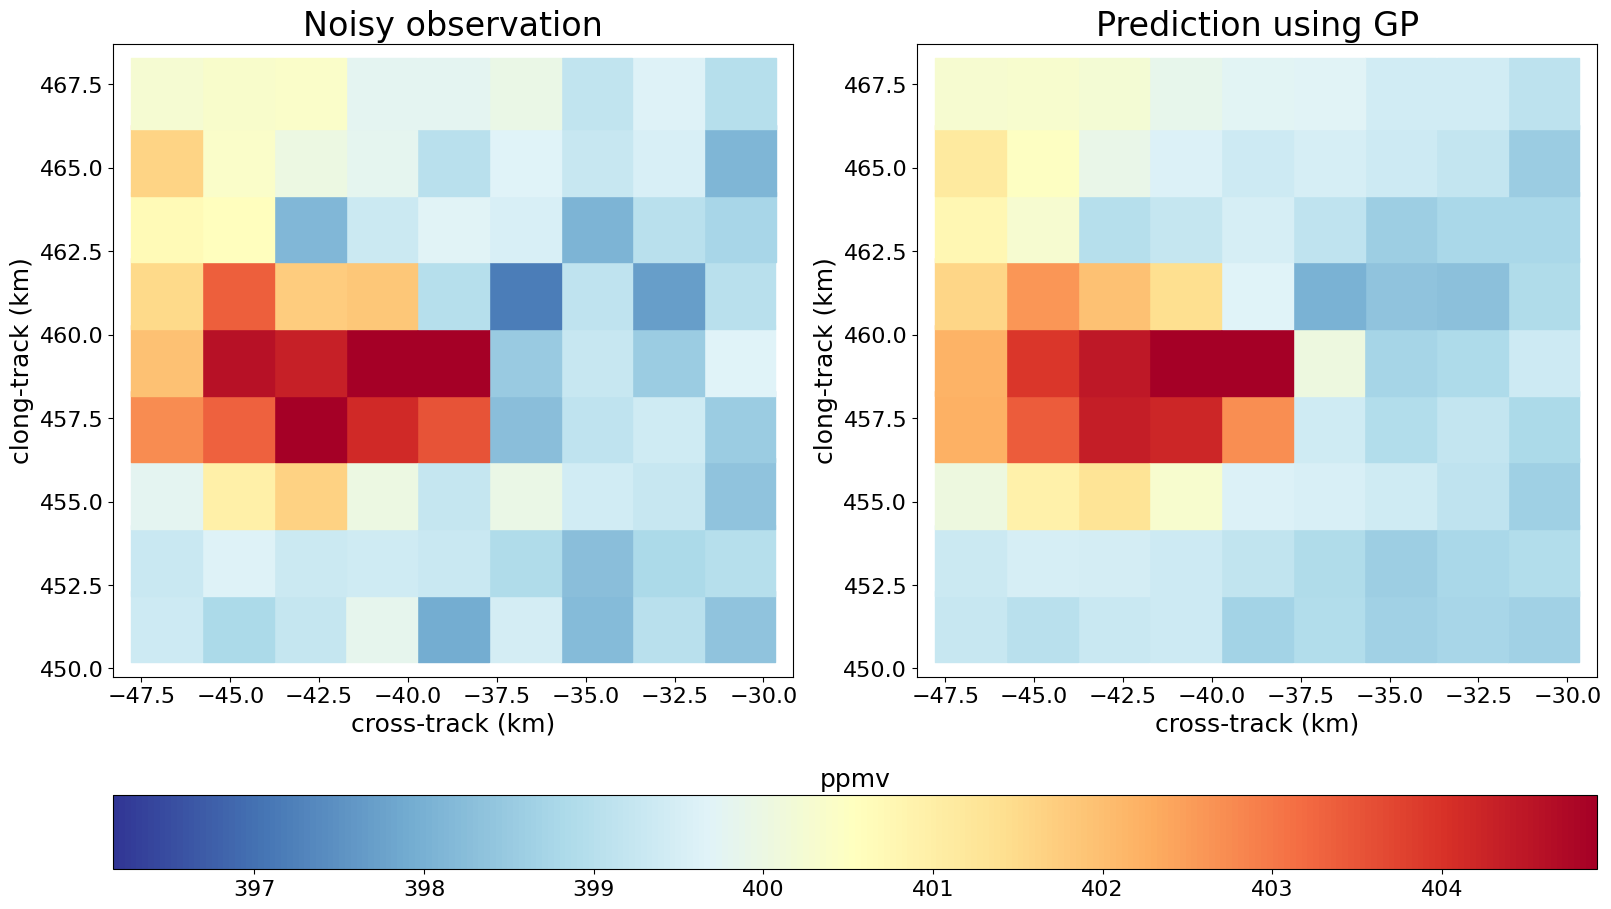

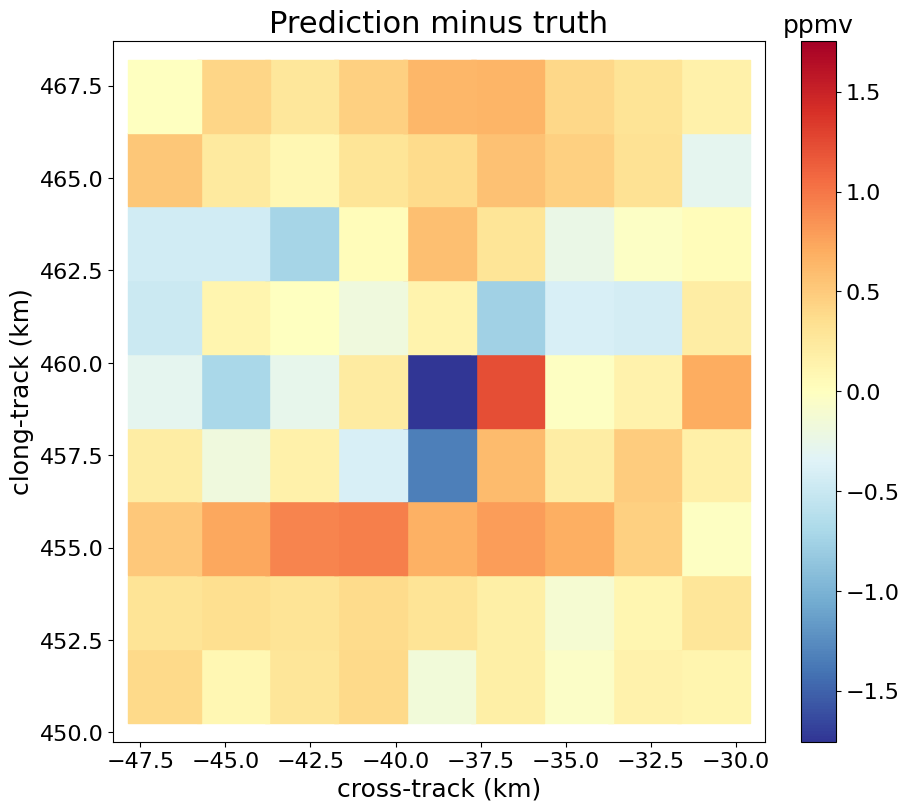

In [128]:
plot_conc_prediction(overpass_near_source,source_coord,concGP_evaluator,save=False,img_format='pdf')

In [129]:
'''
mean_func = mean_func_constructor(overpass_near_source,variable='CO2',style='constant')
plot_along_centerline(overpass_near_source,variable='CO2',N=2000,
                      mean_func=mean_func,mu_adjustment=mu_adjustment,
                      pred_func=lambda coords: concGP_evaluator(coords,gradient=False))
'''
pass

In [130]:
def eval_advGP(coords_eval,concGP_evaluator,windGP_evaluator,include_cov=False,sample=False):
    # Wind components
    if sample:
        wind_expect, wind_cov = windGP_evaluator(coords_eval,include_cov=True)
        wind_samples = np.random.multivariate_normal(wind_expect,wind_cov,size=2000,check_valid='ignore')
    else:
        if include_cov:
            wind_expect, wind_cov = windGP_evaluator(coords_eval,include_cov=True)
            vxvx_cov = wind_cov[:len(coords_eval),:len(coords_eval)]
            vyvy_cov = wind_cov[len(coords_eval):,len(coords_eval):]
            vxvy_cov = wind_cov[:len(coords_eval),len(coords_eval):]
            vyvx_cov = wind_cov[len(coords_eval):,:len(coords_eval)]
        else:
            wind_expect = windGP_evaluator(coords_eval,include_cov=False)
        vx_expect, vy_expect = wind_expect[:len(coords_eval)], wind_expect[len(coords_eval):]
    # Gradient of the concentration field
    g_expect, g_cov = concGP_evaluator(coords_eval,include_cov=True)
    #print(f'gx nans: {np.isnan(g_expect[:(len(g_expect)//2)]).sum()}')
    #print(f'gy nans: {np.isnan(g_expect[(len(g_expect)//2):]).sum()}')
    if sample:
        g_expect, g_cov = concGP_evaluator(coords_eval,include_cov=True)
        g_samples = np.random.multivariate_normal(g_expect,g_cov,size=2000,check_valid='ignore')
    else:
        if include_cov:
            g_expect, g_cov = concGP_evaluator(coords_eval,include_cov=True)
            # Gradient covariance blocks
            gxgx_cov = g_cov[:len(coords_eval),:len(coords_eval)]
            gygy_cov = g_cov[len(coords_eval):,len(coords_eval):]
            gygx_cov = g_cov[len(coords_eval):,:len(coords_eval)]
            gxgy_cov = g_cov[:len(coords_eval),len(coords_eval):]
        else:
            g_expect = concGP_evaluator(coords_eval,include_cov=False) 
        gx_expect, gy_expect = g_expect[:len(coords_eval)], g_expect[len(coords_eval):]
    
    # Divergence expectation
    if sample:
        adv_samples = wind_samples[:,:len(coords_eval)]*g_samples[:,:len(coords_eval)] \
                    + wind_samples[:,len(coords_eval):]*g_samples[:,len(coords_eval):]
        return (1e-3*np.mean(adv_samples,axis=0),1e-6*np.cov(adv_samples,rowvar=False)) if include_cov else 1e-3*np.mean(adv_samples,axis=0)
    else:
        adv_expect = vx_expect*gx_expect + vy_expect*gy_expect
    if include_cov:
        adv_cov = vxvx_cov*gxgx_cov + (vx_expect[:,np.newaxis]*vx_expect[np.newaxis,:])*gxgx_cov + vxvx_cov*(gx_expect[:,np.newaxis]*gx_expect[np.newaxis,:]) \
                + vyvy_cov*gygy_cov + (vy_expect[:,np.newaxis]*vy_expect[np.newaxis,:])*gygy_cov + vyvy_cov*(gy_expect[:,np.newaxis]*gy_expect[np.newaxis,:]) \
                + vxvy_cov*gxgy_cov + (vx_expect[:,np.newaxis]*vy_expect[np.newaxis,:])*gxgy_cov + vxvy_cov*(gx_expect[:,np.newaxis]*gy_expect[np.newaxis,:]) \
                + vyvx_cov*gygx_cov + (vy_expect[:,np.newaxis]*vx_expect[np.newaxis,:])*gygx_cov + vyvx_cov*(gy_expect[:,np.newaxis]*gx_expect[np.newaxis,:])
        return 1e-3*adv_expect.squeeze(), 1e-6*adv_cov
    else:
        return 1e-3*adv_expect.squeeze()

In [131]:
# Remove coordinates too far from the center
def filter_coordinates(X,Y,center=None,dist=6.5):
    if center is None:
        center_X, center_Y = np.mean(X), np.mean(Y)
    else:
        center_X, center_Y = center
    bool_arr = (X-center_X)**2 + (Y-center_Y)**2 < dist**2
    return X[bool_arr], Y[bool_arr]

In [132]:
def peak_correction_continuous(func,center,sx=2.0,sy=1.5,search_r=3.0,
                               alpha=0.0,only_center_correction=False):
    # Standard integral w.r.t. shift and scaling of the domain
    def integral(center,sx,sy,alpha,negative=False,epsrel=0.1):
        I = continuous_integral_over_ellipse(func,center,sx,sy,alpha,epsrel=epsrel)
        #print(I if not negative else -I)
        return I if not negative else -I

    # Find a good initial point by testing a few good candidates
    angles = np.pi*np.arange(0.0,2.0,0.2)
    
    '''
    sx, sy = 0.5*sx, 0.5*sy
    canditate_shifts = np.column_stack((sx*np.cos(angles)*np.cos(alpha)-sy*np.sin(angles)*np.sin(alpha),
                                        sx*np.cos(angles)*np.sin(alpha)+sy*np.sin(angles)*np.cos(alpha)))
    '''
    r = 0.25*(sx + sy)
    canditate_shifts = np.column_stack((r*np.cos(angles),r*np.sin(angles)))
    
    # Find a good initial value by finding the candiate point maximizing the integral of func
    init_shift = np.zeros(2)
    max_val = integral(np.add(center,init_shift),r,r,alpha)
    epsrel = 0.001 * abs(max_val)
    #print('epsrel:',  epsrel)
    for candidate_shift in canditate_shifts:
        val = integral(np.add(center,candidate_shift),r,r,alpha,epsrel=epsrel)
        if val > max_val:
            init_shift, max_val = candidate_shift, val
            epsrel = 0.005 * abs(max_val)
    #print('epsrel:',  epsrel)
    # The shifted point must lie inside a circle with radius search_r
    constraint = NonlinearConstraint(lambda shift: np.linalg.norm(shift-init_shift),0.0,search_r)
    # Maximizing the integral w.r.t. to domain shift by minimizing the negative integral
    integral_over_shifted_domain = lambda shift: integral(np.add(center,shift),r,r,alpha,
                                                          negative=True,epsrel=epsrel)
    res = minimize(integral_over_shifted_domain,
                   x0=init_shift,
                   jac='2-point',
                   method='SLSQP',
                   bounds=[(-search_r,search_r),(-search_r,search_r)],
                   constraints=constraint,
                   options={'maxiter':50,'finite_diff_rel_step':0.05,'eps':0.01,'ftol':0.1})
    success = res.success
    epsrel = 0.005 * abs(res.fun)
    #print('epsrel:',  epsrel)
    opt_shift = res.x if success else (0.0,0.0)
    opt_center = np.add(center,opt_shift)
    sx_opt, sy_opt, alpha_opt = r, r, 0.0

    if not only_center_correction:
        sx, sy = 1.4*r, r/1.4
        # Optimize rotation
        init_rot = 0.0
        max_val = integral(opt_center,sx,sy,alpha,epsrel=epsrel)
        candidate_rots = np.concatenate((np.pi/6.0*np.arange(-3.0,0.0,1.0),
                                         np.pi/6.0*np.arange(1.0,3.0,1.0)))
        for candidate_rot in candidate_rots:
            val = integral(opt_center,sx,sy,alpha+candidate_rot,epsrel=epsrel)
            if val > max_val:
                init_rot, max_val = candidate_rot, val
        epsrel = 0.005 * abs(max_val)
        #print('epsrel:',  epsrel)
        integral_over_rotated_domain = lambda rot: integral(opt_center,sx,sy,alpha+rot,
                                                            negative=True,epsrel=epsrel)
        res = minimize_scalar(integral_over_rotated_domain,
                              bracket=[init_rot-np.pi/6,init_rot+np.pi/6],
                              bounds=[init_rot-np.pi/4,init_rot+np.pi/4],
                              method='bounded',
                              options={'maxiter':50,'disp':False,'xtol':5e-2})
        epsrel = 0.005 * abs(res.fun)
        #print('epsrel:',  epsrel)
        alpha_opt = alpha + res.x
        # Adjust the minor and the major axes of the elliptical domain
        integral_over_scaled_domain = lambda rescale: integral(opt_center,rescale*sx,sy/rescale,
                                                               alpha_opt,negative=True,epsrel=epsrel)
        res = minimize_scalar(integral_over_scaled_domain,
                              bracket=[0.9,1.1],
                              bounds=[2.0/3.0,1.5],
                              method='bounded',
                              options={'maxiter':50,'disp':False,'xtol':5e-2})
        new_sx, new_sy = res.x*sx, sy/res.x
        epsrel = 0.005 * abs(res.fun)
        #print('epsrel:',  epsrel)
        
        # Find a scaling factor minimizing the second derivative of the integral
        def integral_second_derivative(scaling,step=0.01):
            second_derivative = (integral(opt_center,(scaling-step)*new_sx,(scaling-step)*new_sy,alpha_opt,epsrel=epsrel) -
                                 2.0*integral(opt_center,scaling*new_sx,scaling*new_sy,alpha_opt,epsrel=epsrel) +
                                 integral(opt_center,(scaling+step)*new_sx,(scaling+step)*new_sy,alpha_opt,epsrel=epsrel)) / step**2
            return second_derivative
            
        axes_scaling = minimize_scalar(integral_second_derivative,
                                       bracket=[1.2,1.8],
                                       bounds=[0.7,2.1],
                                       method='bounded',
                                       options={'maxiter':50,'disp':False,'xtol':0.02}).x
        sx_opt, sy_opt = axes_scaling*new_sx, axes_scaling*new_sy
        
    return (opt_center,(sx_opt,sy_opt),alpha_opt)

def emission_estimation(overpass,wind,source_coord,source_name='Unknown',variable='CO2',
                        search_r=3.3,mean_func_style='constant',adjust_mu=False,filter_dist=6.5,
                        circular_region=False,plot=False,save=False,filter_negative=True,large_thrsh=2800,
                        return_msg=False,print_GP_params=False,print_time_taken=False):
    overpass_near_source = get_local_overpass(overpass,source_coord,source_name=source_name)
    if overpass_near_source is None:
        msg = 'Source outside the overpass footprint'
        return (np.nan,np.nan,msg) if return_msg else (np.nan,np.nan)
    
    start = perf_counter()
    wind_near_source = include_cross_along_for_wind(wind,overpass,source_coord)
    end = perf_counter()
    if wind_near_source is None:
        msg = 'Error in including cross and along coordinates for the wind field'
        return (np.nan,np.nan,msg) if return_msg else (np.nan,np.nan)
    if print_time_taken:
        print(f'Include cross-along for wind: {(end-start):.1f} s')
    
    surface_wind_speed_near_source = get_surface_wind_speed(wind_near_source,source_coord)
    shape = (overpass_near_source.dims['nobs'],overpass_near_source.dims['nrows'])
    lon, lat = overpass_near_source['lon'].data.flatten(), overpass_near_source['lat'].data.flatten()
    source_index_flat = np.argmin(Earth.inverse(np.column_stack((lon,lat)),source_coord)[:,0])
    source_index = np.unravel_index(source_index_flat, shape)
    if shape != (9,9):
        # Extend data so that the index of the source is always (4,4)
        overpass_near_source = extend_overpass(overpass_near_source,
                                               center_index=source_index,
                                               target_shape=(9,9))
        source_index = (4,4)
        shape = (9,9)
    data_near_source = overpass_near_source[variable].data[(source_index[0]-1):(source_index[0]+2),
                                                           (source_index[1]-1):(source_index[1]+2)]
    if np.isnan(data_near_source).sum() >= 4:
        msg = 'Too many NaN values near the source'
        return (np.nan,np.nan,msg) if return_msg else (np.nan,np.nan)
    overpass_near_source = create_cone(overpass_near_source,
                                       surface_wind_speed_near_source,
                                       search_r=0.72)
    plume_direction = np.arctan2(*overpass_near_source.attrs['cone_vec'][::-1])
    
    ct = overpass_near_source['cross_track'].data
    at = overpass_near_source['along_track'].data
    coords_full = np.column_stack((ct.flatten(),at.flatten()))
    center = coords_full.mean(axis=0)
    ct_upsampled,at_upsampled = divide_grid_cells(overpass_near_source['cross_track_corners'].data,
                                                  overpass_near_source['along_track_corners'].data,
                                                  repeats=3,return_centers=False)
    coords_eval = np.column_stack((ct_upsampled.mean(axis=1),at_upsampled.mean(axis=1)))
    # Remove evaluation coordinates further away from the center than dist
    if filter_dist is not None:
        bool_arr = (coords_eval[:,0]-center[0])**2 + (coords_eval[:,1]-center[1])**2 < filter_dist**2
        ct_upsampled, at_upsampled = ct_upsampled[bool_arr], at_upsampled[bool_arr]
        coords_eval = coords_eval[bool_arr]
    
    data_full = overpass_near_source[variable].data.flatten()
    non_nans = ~np.isnan(data_full)
    data_train, coords_train = data_full[non_nans], coords_full[non_nans]
    
    start = perf_counter()
    windGP_evaluator, windGP_success = windGP_constructor(wind_near_source,return_success=True,
                                                          print_params=print_GP_params)
    end = perf_counter()
    if not windGP_success:
        msg = 'Optimization of the wind GP failed'
        return (np.nan,np.nan,msg) if return_msg else (np.nan,np.nan)
    if print_time_taken:
        print(f'Wind GP training: {(end-start):.1f} s')
        
    start = perf_counter()
    concGP_evaluator, concGP_success, params = concGP_constructor(overpass_near_source,variable=variable,
                                                                  adjust_mu=adjust_mu,return_success=True,
                                                                  return_params=True,print_params=print_GP_params,
                                                                  mean_func_style=mean_func_style)
    end = perf_counter()
    if not concGP_success:
        msg = 'Optimization of the conc GP failed'
        return (np.nan,np.nan,msg) if return_msg else (np.nan,np.nan)
    if print_time_taken:
        print(f'Conc GP training: {(end-start):.1f} s')
    
    start = perf_counter()
    #func = lambda x,y: eval_advGP(np.array([[x,y]]),concGP_evaluator,windGP_evaluator)
    def func(x,y):
        adv_val = eval_advGP(np.array([[x,y]]),concGP_evaluator,windGP_evaluator)
        #print(f'A({x:.3f},{y:.3f}) ≈ {adv_val:.1f}')
        return adv_val
    corrected_center, (sx,sy), alpha = peak_correction_continuous(func,center,sx=params[1],sy=params[2],
                                                                  alpha=-plume_direction,search_r=search_r,
                                                                  only_center_correction=circular_region)
    end = perf_counter()
    if print_time_taken:
        print(f'Domain optimization: {(end-start):.1f} s')

    region = rotate(scale(Point(*corrected_center).buffer(1.0,181),sx,sy),
                    -alpha,origin=Point(*corrected_center),use_radians=True)
    start = perf_counter()
    measures = [Polygon(np.column_stack((ct_upsampled[n],at_upsampled[n]))).intersection(region).area 
                for n in range(len(coords_eval))]
    adv_expect, adv_cov = eval_advGP(coords_eval,concGP_evaluator,windGP_evaluator,include_cov=True)
    emission, emission_std = discrete_integral(measures,adv_expect,adv_cov)
    end = perf_counter()
    if print_time_taken:
        print(f'Emission computation: {(end-start):.1f} s')
        
    # Coef for converting kg/s to Mt/y
    coef = 365.25*24*3600*1e-9
    
    if plot:
        fig = plt.figure(figsize=(9,8),layout='compressed')
        ax = fig.gca()
        date_str, time_str = get_datetime_str(overpass_near_source['time'].data, fancy_str=True, split=True)
        ax.set_title(f'Advection near source "{source_name}"\non {date_str} at {time_str}',
                     fontsize=22)
        adv_mean, adv_std = adv_expect.mean(), adv_expect.std(ddof=1)
        vmin, vmax = adv_mean - 2.5*adv_std, adv_mean + 4.0*adv_std
        adv_scatter = ax.scatter(*coords_eval.T,c=adv_expect,s=40.0,marker='s',vmin=vmin,vmax=vmax)
        ct_limits = (ct[:,0].mean(), ct[:,-1].mean())
        at_limits = (at[0,:].mean(), at[-1,:].mean())
        ct_min, ct_max = min(ct_limits), max(ct_limits)
        at_min, at_max = min(at_limits), max(at_limits)
        ax.set_xlim(ct_min-1.5,ct_max+1.5)
        ax.set_ylim(at_min-1.5,at_max+1.5)
        ax.xaxis.set_tick_params(labelsize=14)
        ax.yaxis.set_tick_params(labelsize=14)
        ax.set_xlabel('cross-track (km)',fontsize=16)
        ax.set_ylabel('along-track (km)',fontsize=16)
        ax.scatter(*corrected_center,c='red',s=5.0,marker='.')
        ax.plot(*region.exterior.xy,color='red',linestyle='--',linewidth=1.5)
        cbar = plt.colorbar(mappable=adv_scatter,orientation='vertical')
        cbar.ax.tick_params(labelsize=14)
        cbar.ax.set_title(r'kg/km$^2$/s',fontsize=16)
        source_name = overpass_near_source['source'].data
        image_str = get_overpass_str(overpass_near_source)
        if save:
            plt.savefig(f'figures/{source_name}_advection_{image_str}.pdf',dpi=300)
        plt.show()
    if filter_negative and emission < 0.0:
        msg = 'Negative emission'
        return (np.nan, np.nan, msg) if return_msg else (np.nan, np.nan)
    if emission > large_thrsh:
        print(f'Large emission estimate ≈ {(coef*emission):.2f} +/- {(coef*emission_std):.2f}')
        msg = 'Emission larger than the threshold value'
        return (np.nan, np.nan, msg) if return_msg else (np.nan, np.nan)
    msg = 'Emission estimation successfull'
    if return_msg:
        return coef*emission, coef*emission_std, msg
    else:
        return coef*emission, coef*emission_std

File: 2015082811_o3564_l1610
Source: Lippendorf
Include cross-along for wind: 11.5 s
Wind GP params:
σ: 2.085, l: 4.682, μvₓ: -2.359, μvᵧ: 0.258, nₓ: 0.171, nᵧ: 0.131
Func val: -167.890
Wind GP training: 2.7 s
Conc GP params:
σ: 1.436, lₓ: 2.807, lᵧ: 1.778, σₙ: 0.745
func val: 143.862
Conc GP training: 0.2 s
Domain optimization: 27.3 s
Emission computation: 5.6 s


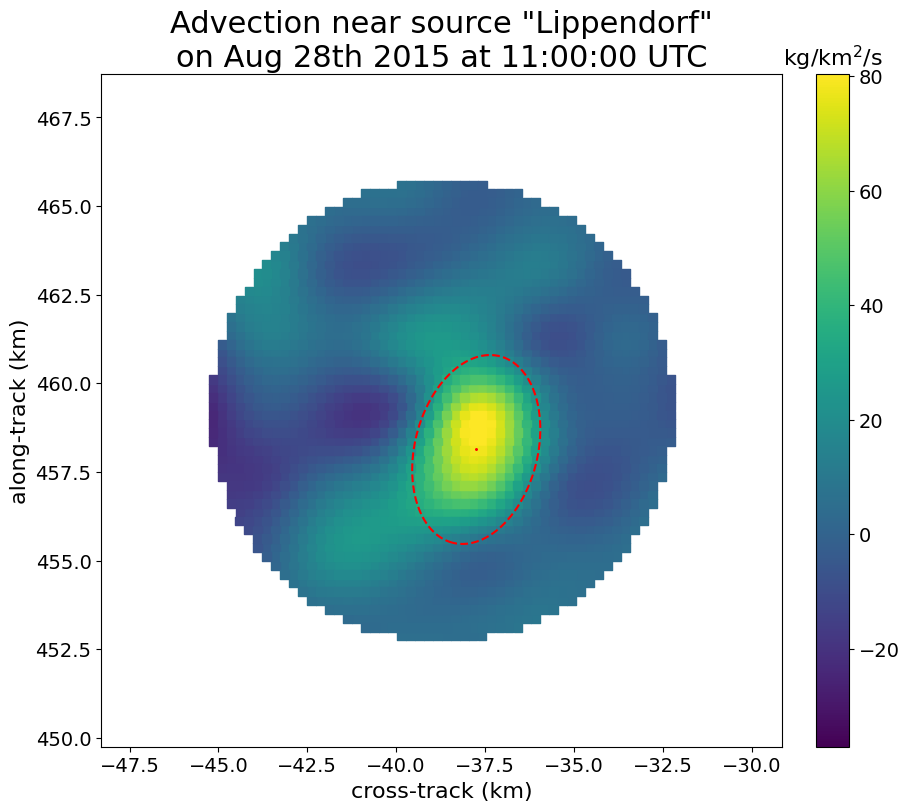

Emission estimation successfull
Estimated: 22.10 +/- 7.38 (MtCO2/y)
True emission: 17.26 (MtCO2/y)


In [133]:
image_str_parts = get_overpass_str(overpass_near_source).split('_')
image_str_parts[0] = image_str_parts[0].replace('T','')[:-4]
image = '_'.join(image_str_parts)
overpass_str = f'Sentinel_7_CO2_{image}'
print('File:', image)
print('Source:', overpass_near_source['source'].data)
emission,emission_std,msg = emission_estimation(overpass,wind_sliced,source_coord,source_name=source_name,
                                                mean_func_style='constant',adjust_mu=False,
                                                search_r=3.3,filter_dist=6.5,circular_region=False,
                                                return_msg=True,plot=True,save=False,
                                                print_GP_params=True,print_time_taken=True)
print(msg)
emission_true = true_CO2_emission_xr.loc[dict(sources=source_name,images=overpass_str)]
print(f'Estimated: {emission:.2f} +/- {(emission_std):.2f} (MtCO2/y)')
print(f'True emission: {emission_true:.2f} (MtCO2/y)')

In [135]:
## MAIN LOOP for running emissions for multiple days and sources

save_results = False
write_to_output = False
cloudiness = 'full'
wind_product = 'SMARTCARB'
MISSVAL = np.nan
file = 'latest'
output_fn = 'output_temp.txt'

if cloudiness == 'full':
    co2_cloud_threshold, no2_cloud_threshold = 1.00, 1.00
elif cloudiness == 'low':
    co2_cloud_threshold, no2_cloud_threshold = 0.01, 0.30
else:
    raise ValueError(f'Option {cloudiness} unknown for cloudiness')
    
l2 = ddeq.smartcarb.Level2Dataset(SMARTCARB_DATA_PATH,'ace',co2_noise_scenario='medium',
                                  no2_noise_scenario='high',make_no2_error_cloud_dependent=False,
                                  co2_cloud_threshold=co2_cloud_threshold,
                                  no2_cloud_threshold=no2_cloud_threshold)

# Emission estimations for each date
source_names = sources['source'].data
n_sources = len(source_names)
images = np.concatenate(tuple(list(map(lambda s: basename(s).split('.')[0], l2.get_filenames(day))) 
                              for day in pd.date_range("2015-01-01","2015-12-24")))
n_images = len(images)
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
n_months = len(months)

# Test run for one day
days = pd.date_range("2015-08-28","2015-08-28")

if exists(f'emis_est_{file}.npy'):
    est_xr = xr.DataArray(np.load(f'emis_est_{file}.npy'),dims=['source','image'],
                          coords=dict(source=source_names,image=images),
                          attrs={'units': 'Mt/yr',
                                 'Description': 'Estimated Emission by image', 
                                 'Missing Value': MISSVAL})
else:
    est_xr = xr.DataArray(np.full((n_sources,n_images),MISSVAL),dims=['source','image'],
                          coords=dict(source=source_names,image=images),
                          attrs={'units': 'Mt/yr',
                                 'Description': 'Estimated Emission by image', 
                                 'Missing Value': MISSVAL})
if exists(f'emis_std_{file}.npy'):
    std_xr = xr.DataArray(np.load(f'emis_std_{file}.npy'),dims=['source','image'],
                          coords=dict(source=source_names,image=images),
                          attrs={'units': 'Mt/yr',
                                 'Description': 'Estimated Emission Error by image', 
                                 'Missing Value': MISSVAL})
else:
    std_xr = xr.DataArray(np.full((n_sources,n_images),MISSVAL),dims=['source','image'],
                          coords=dict(source=source_names,image=images),
                          attrs={'units': 'Mt/yr',
                                 'Description': 'Estimated Emission Error by image', 
                                 'Missing Value': MISSVAL})
if exists(f'messages_{file}.npy'):
    msg_xr = xr.DataArray(np.load(f'messages_{file}.npy'),dims=['source','image'],
                          coords=dict(source=source_names,image=images),
                          attrs={'units': 'Mt/yr',
                                  'Description': 'Estimated Emission Error by image', 
                                  'Missing Value': MISSVAL})
else:
    msg_xr = xr.DataArray(np.full((n_sources,n_images),'No message'),dims=['source','image'],
                          coords=dict(source=source_names,image=images),
                          attrs={'units': 'Mt/yr',
                                 'Description': 'Estimated Emission Error by image', 
                                 'Missing Value': MISSVAL})
    
with open(output_fn, "a") as output_file:
    for date in days:
        data_for_day = l2.read_date(date)
        for overpass in data_for_day:
            overpass['CO2_BG'].attrs = {'units': 'ppmv'}
            datetime_str, o_str, l_str = get_overpass_str(overpass).split('_')
            date_str, time_str = datetime_str.split('T')
            image_str = f'Sentinel_7_CO2_{date_str}{time_str[:2]}_{o_str}_{l_str}'
            if write_to_output:
                output_file.write(f'\n{image_str}\n')
            else:
                print(f'\n{image_str}')
            overpass = remove_nan_lines(overpass)
            if overpass.dims['nobs'] <= 1:
                msg = 'The overpass contains one or zero cross-track lines with numerical values'
                if write_to_output:
                    output_file.write(f'{msg}\n')
                else:
                    print(msg)
                for source_name in source_names:
                    msg_xr.loc[dict(source=source_name,image=image_str)] = 'No data'
                continue
            overpass = include_cross_along_for_overpass(overpass)
            wind_file = f'SMARTCARB_winds_{date_str}11.nc'
            wind_ds = xr.open_dataset(os.path.join(WIND_DATA_PATH,wind_file)).drop_vars(['U','V','HHL'],errors='ignore')
            wind_sliced, overpass = slice_wind(wind_ds,overpass)
            wind_ds.close()
            del wind_ds
            for n in range(len(source_names)):
                source_name = source_names[n]
                if write_to_output:
                    output_file.write(f'Attempting emission estimation for source {source_name}\n')
                else:
                    print(f'Attempting emission estimation for source {source_name}')
                source_coord = (float(sources['lon_o'][sources.source == source_name].data),
                                float(sources['lat_o'][sources.source == source_name].data))
                est_mean,est_std,msg = emission_estimation(overpass,wind_sliced,source_coord,
                                                           search_r=3.3,filter_dist=6.5,
                                                           adjust_mu=False,circular_region=False,
                                                           return_msg=True,plot=False)
                if np.isnan(est_mean):
                    if write_to_output:
                        output_file.write(f'{msg}\n')
                    else:
                        print(msg)
                else:
                    true_emis = true_CO2_emission_xr.loc[dict(sources=source_name,images=image_str)]
                    if write_to_output:
                        output_file.write(f'Estimated: {est_mean:.2f} +/- {est_std:.2f} (MtCO2/y)\n')
                        output_file.write(f'True emis: {true_emis:.2f} (MtCO2/y)\n')
                    else:
                        print(f'Estimated: {est_mean:.2f} +/- {est_std:.2f} (MtCO2/y)')
                        print(f'True emis: {true_emis:.2f} (MtCO2/y)')
                est_xr.loc[dict(source=source_name,image=image_str)] = est_mean
                std_xr.loc[dict(source=source_name,image=image_str)] = est_std
                if msg == 'Emission estimation successfull':
                    short_msg = 'Success'
                elif msg == 'Source outside the overpass footprint':
                    short_msg = 'Outside'
                elif msg == 'Optimization of the conc GP failed' or msg == 'Optimization of the wind GP failed':
                    short_msg = 'GP failure'
                elif msg == 'Negative emission':
                    short_msg = 'Negative'
                elif msg == 'Emission larger than the threshold value':
                    short_msg = 'Too large'
                elif msg == 'Too many NaN values near the source':
                    short_msg = 'No data'
                else:
                    short_msg = 'Other fail'
                msg_xr.loc[dict(source=source_name,image=image_str)] = short_msg
            # Close wind and overpass dataset variables 
            overpass.close()
            del overpass
            wind_sliced.close()
            del wind_sliced
        if save_results:
            np.save(f'emis_est_{file}.npy',est_xr.data)
            np.save(f'emis_std_{file}.npy',std_xr.data)
            np.save(f'messages_{file}.npy',msg_xr.data)
            if write_to_output:
                output_file.flush()


Sentinel_7_CO2_2015082810_o3563_l0000
Attempting emission estimation for source Boxberg
Source outside the overpass footprint
Attempting emission estimation for source Chvaletice
Source outside the overpass footprint
Attempting emission estimation for source Dolna Odra
Source outside the overpass footprint
Attempting emission estimation for source Heyden
Source outside the overpass footprint
Attempting emission estimation for source Janschwalde
Source outside the overpass footprint
Attempting emission estimation for source Lippendorf
Source outside the overpass footprint
Attempting emission estimation for source Melnik
Source outside the overpass footprint
Attempting emission estimation for source Opole
Estimated: 7.79 +/- 5.78 (MtCO2/y)
True emis: 7.68 (MtCO2/y)
Attempting emission estimation for source Patnow
Source outside the overpass footprint
Attempting emission estimation for source Pocerady
Source outside the overpass footprint
Attempting emission estimation for source Prunero

In [136]:
wind_product = 'SMARTCARB'
file = 'reported'
MISSVAL = np.nan
source_names = sources['source'].data
full_CO2_emissions = pd.read_csv(f'{cwd}/src/ddeq/data/SMARTCARB-CO2-emissions.csv',sep='\t',index_col=0)
full_CO2_emissions.rename(columns=lambda s: re.sub(' +',' ',re.sub(r"\(.*?\)"," ",s)).strip(), inplace=True)

emis_est = np.load(f'emis_est_{file}.npy')
emis_std = np.load(f'emis_std_{file}.npy')
messages = np.load(f'messages_{file}.npy')
est_xr = xr.DataArray(data=emis_est,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission by image', 
                             'Missing Value': MISSVAL})
std_xr = xr.DataArray(data=emis_std,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission Error by image', 
                             'Missing Value': MISSVAL})
msg_xr = xr.DataArray(data=messages,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission Error by image', 
                             'Missing Value': MISSVAL})

In [137]:
cols = ['avg emission', '# of overpasses', '# with no data','# of unphysical']
list_of_dtypes = [np.float32,np.uint32,np.uint32,np.uint32,np.uint32]
df_failed = pd.DataFrame(data=np.zeros((len(source_names),len(cols))),index=source_names,
                         columns=cols).astype(dict(zip(cols,list_of_dtypes)))
mean_emissions = true_CO2_emission_xr.mean(dim='images')
for source in source_names:
    messages_per_source = msg_xr.loc[dict(source=source)].data
    df_failed.loc[source,'avg emission'] = np.round(mean_emissions.loc[dict(sources=source)].data,2)
    #est_per_source = est_xr.loc[dict(source=source)].data
    #std_per_source = std_xr.loc[dict(source=source)].data
    #rel_errs_per_source = 100.0 * np.nanmean(np.abs(std_per_source / est_per_source))
    #df_failed.loc[source,'avg rel err (%)'] = rel_errs_per_source
    N_outside = np.sum(messages_per_source == 'Outside')
    df_failed.loc[source,'# of overpasses'] = len(messages_per_source) - N_outside
    N_without = np.sum(messages_per_source == 'No data')
    df_failed.loc[source,'# with no data'] = N_without
    #N_optfail = np.sum(messages_per_source == 'GP failure')
    #df_failed.loc[source,'# of failed GPs'] = N_optfail
    N_unphysical = np.sum((messages_per_source == 'Too large') | (messages_per_source == 'Negative'))
    df_failed.loc[source,'# of unphysical'] = N_unphysical

sort_indices = np.argsort(mean_emissions.data)[::-1]
df_failed = df_failed.iloc[sort_indices]
#df_failed.to_csv(f'Results/rejections.csv')
df_failed

,avg emission,# of overpasses,# with no data,# of unphysical
Janschwalde,40.28,193,30,0
Boxberg,23.03,192,30,0
Lippendorf,18.44,193,30,0
Prunerov,13.24,193,30,0
Pocerady,10.80,193,30,0
Turow,10.54,192,30,1
Schwarze Pumpe,9.93,193,30,1
Dolna Odra,9.24,225,30,1
Opole,8.71,193,30,0
Patnow,7.04,193,30,0


In [139]:
# Analyze results
source_names = sources['source'].data
cols = ['avg emission', '# of estimations', 'avg unc ratio (%)', 'Within 1σ','Within 2σ']
list_of_dtypes = [np.float32,np.uint32,np.float32,np.float32,np.float32]
df = pd.DataFrame(data=np.zeros((len(source_names),len(cols))),index=source_names,
                  columns=cols).astype(dict(zip(cols,list_of_dtypes)))
mean_emissions = true_CO2_emission_xr.mean(dim='images')

for source in source_names:
    est_per_source = est_xr.loc[dict(source=source)].data
    std_per_source = std_xr.loc[dict(source=source)].data
    non_nans = ~np.isnan(est_per_source)
    est_per_source = est_per_source[non_nans]
    std_per_source = std_per_source[non_nans]
    true_per_source = true_CO2_emission_xr.loc[dict(sources=source)].data[non_nans]
    # Number of estimations
    N_est = len(est_per_source)
    df.loc[source,'avg emission'] = np.round(mean_emissions.loc[dict(sources=source)].data,2)
    df.loc[source,'# of estimations'] = N_est
    rel_errs_per_source = np.round(100.0 * np.mean(np.abs(std_per_source / est_per_source)),1)
    df.loc[source,'avg unc ratio (%)'] = rel_errs_per_source
    if non_nans.sum() > 0:
        df.loc[source,'Within 1σ'] = round(100.0*sum((est_per_source - std_per_source < true_per_source) & 
                                                     (true_per_source < est_per_source + std_per_source)) / N_est, 1)
        df.loc[source,'Within 2σ'] = round(100.0*sum((est_per_source - 2.0*std_per_source < true_per_source) & 
                                                     (true_per_source < est_per_source + 2.0*std_per_source)) / N_est, 1)
    else:
        df.loc[source,'Within 1σ'] = np.nan
        df.loc[source,'Within 2σ'] = np.nan
#df.to_csv(f'Results/Analysis.csv')
sort_indices = np.argsort(mean_emissions.data)[::-1]
df = df.iloc[sort_indices]
#df.to_csv(f'Results/uncertainty_analysis.csv')
df

,avg emission,# of estimations,avg unc ratio (%),Within 1σ,Within 2σ
Janschwalde,40.28,163,46.8,85.3,98.2
Boxberg,23.03,162,61.6,77.2,96.3
Lippendorf,18.44,163,70.7,66.9,92.6
Prunerov,13.24,163,129.9,69.9,94.5
Pocerady,10.80,163,78.1,68.7,92.6
Turow,10.54,161,92.3,71.4,93.8
Schwarze Pumpe,9.93,162,133.6,68.5,95.1
Dolna Odra,9.24,194,116.9,67.5,90.2
Opole,8.71,163,107.5,65.6,89.0
Patnow,7.04,163,112.7,76.1,93.9


# of estimations for source 'Boxberg': 162
# of estimations for source 'Chvaletice': 160
# of estimations for source 'Dolna Odra': 194
# of estimations for source 'Heyden': 195
# of estimations for source 'Janschwalde': 163
# of estimations for source 'Lippendorf': 163
# of estimations for source 'Melnik': 162
# of estimations for source 'Opole': 163
# of estimations for source 'Patnow': 163
# of estimations for source 'Pocerady': 163
# of estimations for source 'Prunerov': 163
# of estimations for source 'Schkopau': 164
# of estimations for source 'Schwarze Pumpe': 162
# of estimations for source 'Staudinger': 162
# of estimations for source 'Turow': 161


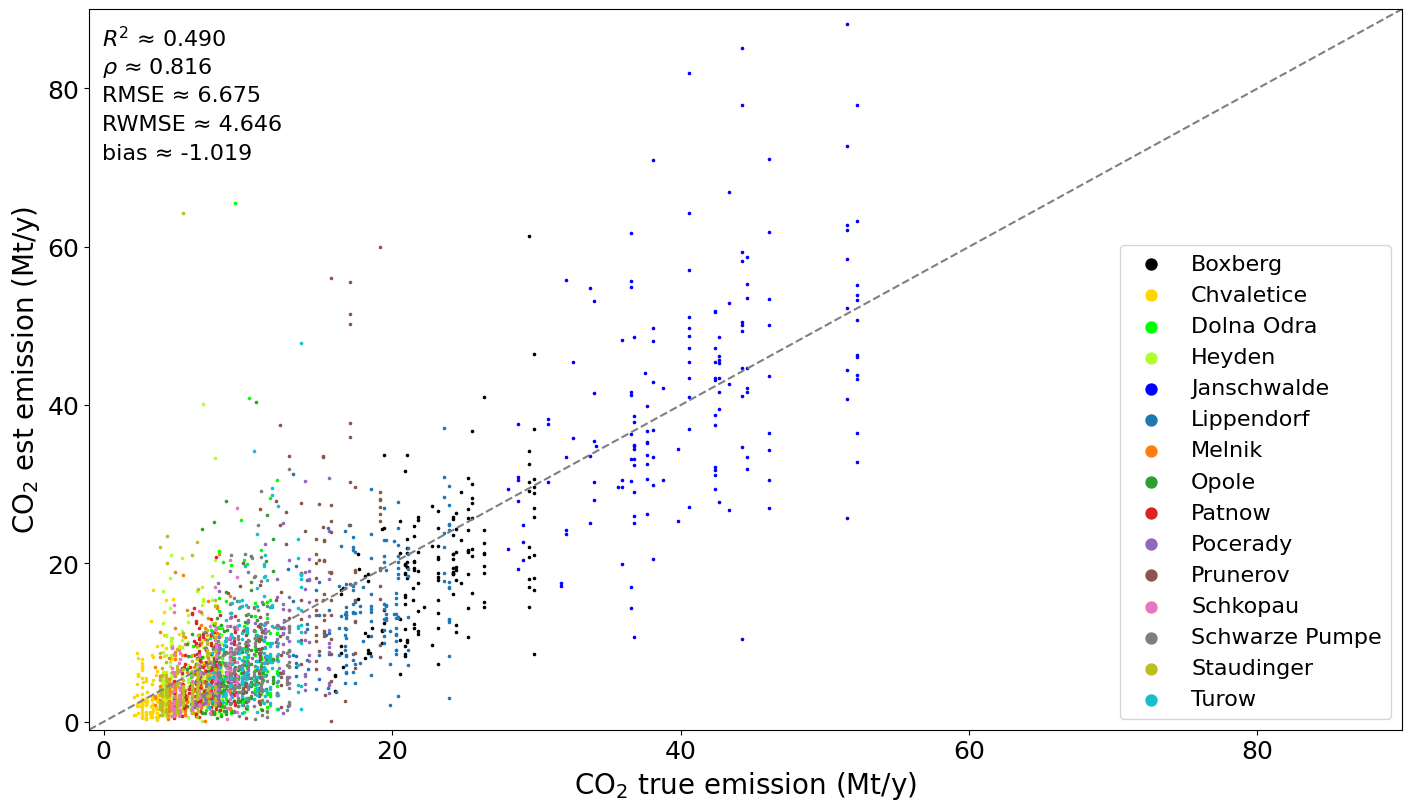

In [60]:
fig = plt.figure(figsize=(14,8),layout='compressed')
ax = fig.gca()
#ax.set_title(f"DIV results, {wind_product} winds, all sources", fontsize=18)
ax.axline((0,0),slope=1,linestyle='--',color='grey')
min_lim, max_lim = -1.0, 90.0

est_all = []
std_all = []
true_all = []
colors = ['black','gold','lime','greenyellow','blue'] + plt.rcParams['axes.prop_cycle'].by_key()['color']
source_names = sources.source.data
for index in range(len(source_names)):
    non_nans = ~np.isnan(emis_est[index,:])
    print(f"# of estimations for source '{source_names[index]}': {non_nans.sum()}")
    est_per_source = emis_est[index,non_nans]
    std_per_source = emis_std[index,non_nans]
    est_all.extend(est_per_source)
    std_all.extend(std_per_source)
    true_per_source = true_CO2_emission_xr[index,non_nans]
    true_all.extend(true_per_source)
    ax.scatter(true_per_source,est_per_source,marker='.',s=10,
               label=source_names[index],c=colors[index])
ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)
ax.set_xlim(min_lim,max_lim)
ax.set_ylim(min_lim,max_lim)
ax.set_xlabel('CO$_2$ true emission (Mt/y)',fontsize=20)
ax.set_ylabel('CO$_2$ est emission (Mt/y)',fontsize=20)
R2 = r2_score(true_all,est_all)
corr = np.corrcoef(true_all,est_all)[0,1]
rmse = np.sqrt(np.mean(np.square(np.subtract(est_all,true_all))))
weights = 1.0 / np.square(std_all)
rwmse = np.sqrt(np.average(np.square(np.subtract(est_all,true_all)),weights=weights))
bias = np.mean(np.subtract(est_all,true_all))
# Set texts to ax
ax.text(0.01, 0.96, fr'$R^2$ ≈ {R2:.3f}',horizontalalignment='left',verticalalignment='center',
        transform = ax.transAxes, fontsize=16)
ax.text(0.01, 0.92, fr'$\rho$ ≈ {corr:.3f}',horizontalalignment='left',verticalalignment='center',
        transform = ax.transAxes, fontsize=16)
ax.text(0.01, 0.88, f'RMSE ≈ {rmse:.3f}',horizontalalignment='left',verticalalignment='center',
        transform = ax.transAxes, fontsize=16)
ax.text(0.01, 0.84, f'RWMSE ≈ {rwmse:.3f}',horizontalalignment='left',verticalalignment='center',
        transform = ax.transAxes, fontsize=16)
ax.text(0.01, 0.80, f'bias ≈ {bias:.3f}',horizontalalignment='left',verticalalignment='center',
        transform = ax.transAxes, fontsize=16)
ax.legend(fontsize=16,loc='lower right',markerscale=5.0)
#plt.savefig('figures/DIV_method_summarize.png',dpi=300)
plt.show()

# of estimations for source 'Boxberg': 162
# of estimations for source 'Chvaletice': 160
# of estimations for source 'Dolna Odra': 194
# of estimations for source 'Heyden': 195
# of estimations for source 'Janschwalde': 163
# of estimations for source 'Lippendorf': 163
# of estimations for source 'Melnik': 162
# of estimations for source 'Opole': 163
# of estimations for source 'Patnow': 163
# of estimations for source 'Pocerady': 163
# of estimations for source 'Prunerov': 163
# of estimations for source 'Schkopau': 164
# of estimations for source 'Schwarze Pumpe': 162
# of estimations for source 'Staudinger': 162
# of estimations for source 'Turow': 161
R² ≈ 0.490
ρ ≈ 0.816
RMSE ≈ 6.675
RWMSE ≈ 4.646
bias ≈ -1.019


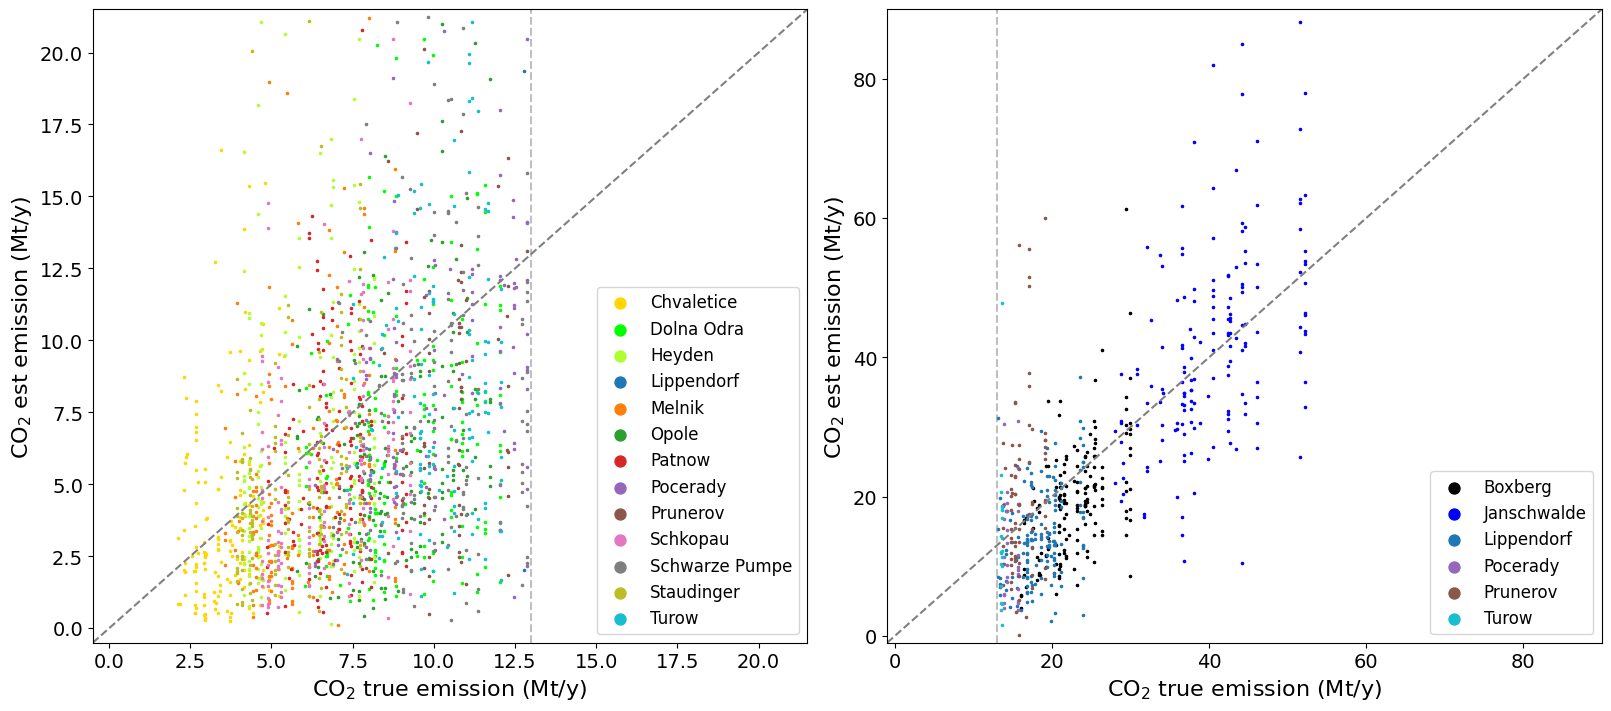

In [62]:
emis_limit = 13.0

fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(16,7),layout='compressed')
axs = axs.flatten()
true_per_ax = [[],[]]
est_per_ax = [[],[]]
std_per_ax = [[],[]]
colors = ['black','gold','lime','greenyellow','blue'] + plt.rcParams['axes.prop_cycle'].by_key()['color']
source_names = sources.source.data
for index in range(len(source_names)):
    non_nans = ~np.isnan(emis_est[index,:])
    print(f"# of estimations for source '{source_names[index]}': {non_nans.sum()}")
    true_per_source = np.array(true_CO2_emission_xr[index,non_nans])
    est_per_source = np.array(emis_est[index,non_nans])
    std_per_source = np.array(emis_std[index,non_nans])
    for n in range(len(axs)):
        ax = axs[n]
        if n == 0:
            mask = true_per_source < emis_limit
        elif n == len(axs) - 1:
            mask = true_per_source > emis_limit
        else:
            mask = (emis_limit < true_per_source) & (true_per_source < emis_limit)
        true_filtered = true_per_source[mask]
        est_filtered = est_per_source[mask]
        std_filtered = std_per_source[mask]
        if len(true_filtered) > 0:
            true_per_ax[n].extend(true_filtered)
            est_per_ax[n].extend(est_filtered)
            std_per_ax[n].extend(std_filtered)
            ax.scatter(true_filtered,est_filtered,marker='.',s=10.0,
                       label=source_names[index],c=colors[index])
    
for n in range(len(axs)):
    ax = axs[n]
    ax.axline((0,0),slope=1,linestyle='--',color='grey')
    ax.xaxis.set_tick_params(labelsize=14)
    ax.yaxis.set_tick_params(labelsize=14)
    if n == 0:
        min_lim, max_lim = -0.5, emis_limit + 8.5
    else:
        min_lim, max_lim = -1.0, 90.0
    ax.set_xlim(min_lim,max_lim)
    ax.set_ylim(min_lim,max_lim)
    ax.axvline(x=emis_limit,color='gray',linestyle='--',alpha=0.5)
    ax.set_xlabel('CO$_2$ true emission (Mt/y)',fontsize=16)
    ax.set_ylabel('CO$_2$ est emission (Mt/y)',fontsize=16)
    ax.legend(fontsize=12,loc='lower right',markerscale=5.0)

R2 = r2_score(np.concatenate(true_per_ax),np.concatenate(est_per_ax))
print(f'R² ≈ {R2:.3f}')
corr = np.corrcoef(np.concatenate(true_per_ax),np.concatenate(est_per_ax))[0,1]
print(f'ρ ≈ {corr:.3f}')
rmse = np.sqrt(np.mean(np.subtract(np.concatenate(est_per_ax),np.concatenate(true_per_ax))**2))
print(f'RMSE ≈ {rmse:.3f}')
weights = 1.0 / np.square(np.concatenate(std_per_ax))
rwmse = np.sqrt(np.average(np.square(np.subtract(np.concatenate(est_per_ax),np.concatenate(true_per_ax))),
                           weights=weights))
print(f'RWMSE ≈ {rwmse:.3f}')
bias = np.mean(np.subtract(np.concatenate(est_per_ax),np.concatenate(true_per_ax)))
print(f'bias ≈ {bias:.3f}')
    
#plt.savefig('figures/DIV_method_summarize.pdf',dpi=300)
plt.show()

Method: GPM
# of estimations for source 'Boxberg': 99
# of estimations for source 'Chvaletice': 85
# of estimations for source 'Dolna Odra': 168
# of estimations for source 'Heyden': 108
# of estimations for source 'Janschwalde': 130
# of estimations for source 'Lippendorf': 125
# of estimations for source 'Melnik': 93
# of estimations for source 'Opole': 114
# of estimations for source 'Patnow': 114
# of estimations for source 'Pocerady': 105
# of estimations for source 'Prunerov': 100
# of estimations for source 'Schkopau': 100
# of estimations for source 'Schwarze Pumpe': 92
# of estimations for source 'Staudinger': 60
# of estimations for source 'Turow': 136
Method: IME
# of estimations for source 'Boxberg': 92
# of estimations for source 'Chvaletice': 80
# of estimations for source 'Dolna Odra': 179
# of estimations for source 'Heyden': 89
# of estimations for source 'Janschwalde': 123
# of estimations for source 'Lippendorf': 99
# of estimations for source 'Melnik': 91
# of estim

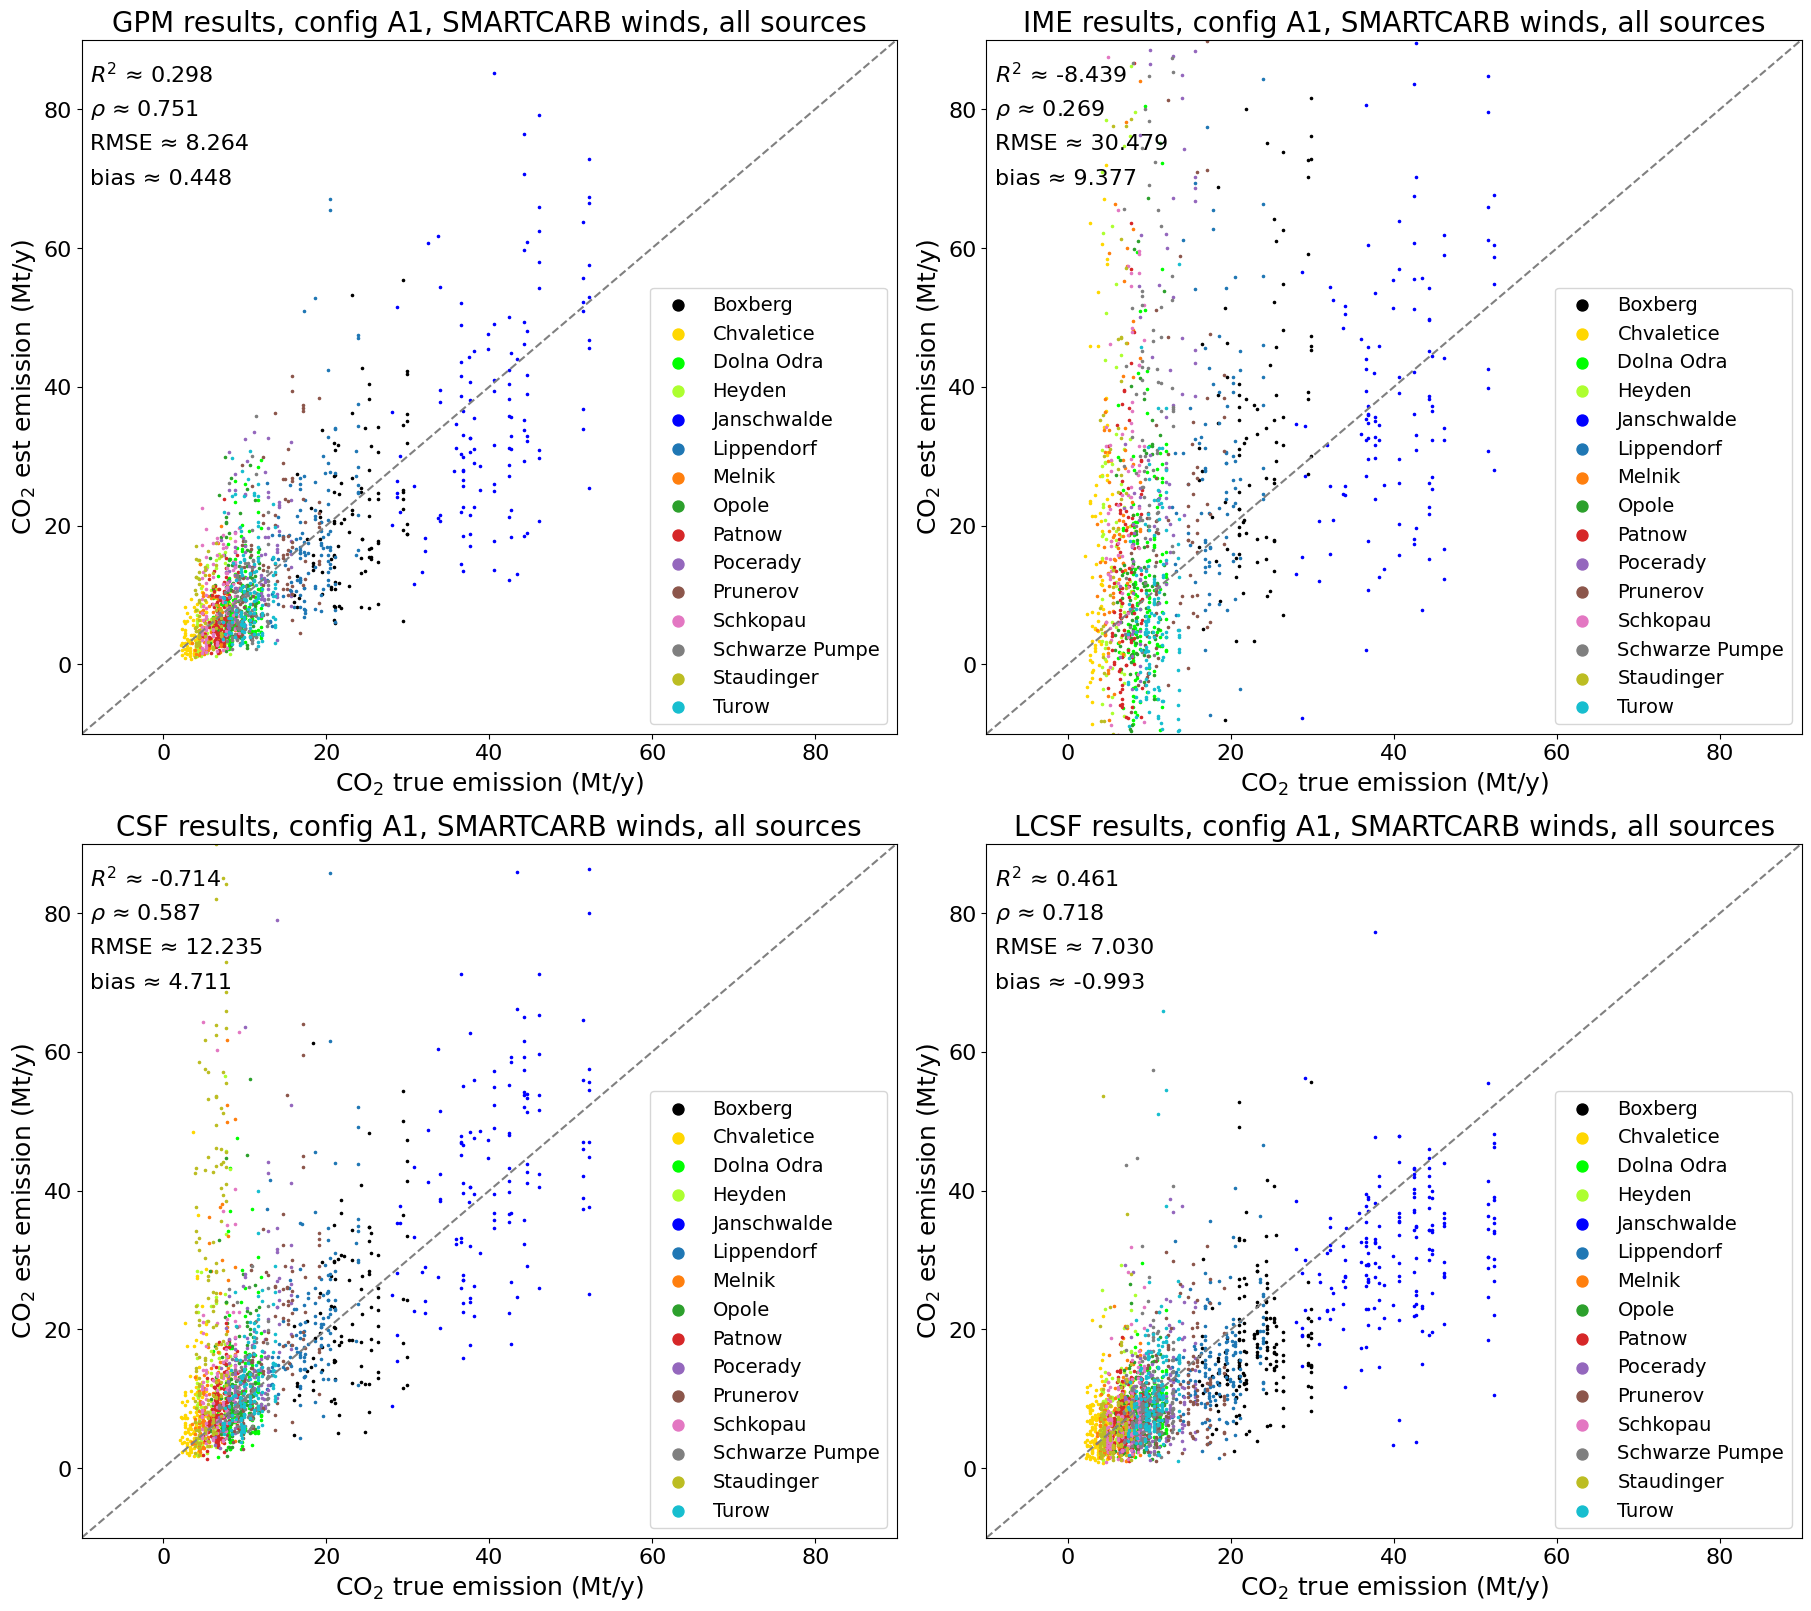

In [61]:
# Other methods
config = 'A1'
wind_product = 'SMARTCARB'
MISSVAL = np.nan

#fig = plt.figure(figsize=(10,8),layout='compressed')
fig, ((ax_GPM,ax_IME),(ax_CSF,ax_LCSF)) = plt.subplots(nrows=2,ncols=2,figsize=(18,16),layout='compressed')
colors = ['black','gold','lime','greenyellow','blue'] + plt.rcParams['axes.prop_cycle'].by_key()['color']

for method in ['GPM', 'IME', 'CSF', 'LCSF']:
    if method == 'GPM':
        filename = f'Inversion_Results_Empa_{config}_GPM_CO2_wNO2_SMARTCARB.nc'
        variable, source_dim, image_dim, ax = 'CO2_estimates', 'sources', 'filenames', ax_GPM
    elif method == 'IME':
        filename = f'Inversion_Results_Empa_{config}_IME_CO2_wNO2_SMARTCARB.nc'
        variable, source_dim, image_dim, ax = 'estimated_emissions', 'source', 'image', ax_IME
    elif method == 'CSF':
        filename = f'Inversion_Results_IPSL_{config}_CSF_CO2_wNO2_SMARTCARB.nc'
        variable, source_dim, image_dim, ax = 'CO2_estimates', 'source', 'image', ax_CSF
    elif method == 'LCSF':
        filename = f'Inversion_Results_IPSL_{config}_LCSF_CO2_wNO2_SMARTCARB.nc'
        variable, source_dim, image_dim, ax  = 'estimated_emissions', 'sources', 'filenames', ax_LCSF
    else:
        raise ValueError('Unknown method')

    ds = Dataset(f'Results/{filename}')

    remove_sources = ['Belchatow','Berlin','Lipetsk','Matimba','Paris','Hamburg','Prague']
    bool_array = np.array([source not in remove_sources for source in ds[source_dim][:]],dtype=bool)
    source_names = ds[source_dim][:][bool_array]
    estimates = ds[variable][bool_array,:].data if method in ['IME','CSF','LCSF'] else ds[variable][:,bool_array].data
    source_sort = np.argsort(source_names)
    source_names = source_names[source_sort]
    estimates = estimates[source_sort,:] if method in ['IME','CSF','LCSF'] else estimates[:,source_sort]

    ax.set_title(f"{method} results, config {config}, {wind_product} winds, all sources",
                 fontsize=20)
    ax.axline((0,0),slope=1,linestyle='--',color='grey')
    min_lim, max_lim = -10.0, 90.0

    est_all = []
    true_all = []
    
    print(f'Method: {method}')
    for index in range(len(source_names)):
        est_per_source = estimates[index,:] if method in ['IME','CSF','LCSF'] else estimates[:,index]
        if method == 'IME':
            est_per_source *= 3600*24*365.25*1e-9
        est_per_source[est_per_source == -9999] = np.nan
        non_nans = ~np.isnan(est_per_source)
        print(f"# of estimations for source '{source_names[index]}': {non_nans.sum()}")
        non_nan_images = ds[image_dim][:][non_nans]
        if method in ['GPM','IME']:
            non_nan_images = list(map(lambda s: s.split('.')[0], non_nan_images))
        true_per_source = true_CO2_emission_xr.loc[dict(images=non_nan_images,sources=source_names[index])].data
        est_all.extend(est_per_source[non_nans])
        true_all.extend(true_per_source)
        ax.scatter(true_per_source,est_per_source[non_nans],marker='.',s=10,
                   c=colors[index],label=source_names[index])
    ds.close()
    ax.xaxis.set_tick_params(labelsize=16)
    ax.yaxis.set_tick_params(labelsize=16)
    ax.set_xlim(min_lim,max_lim)
    ax.set_ylim(min_lim,max_lim)
    ax.set_xlabel('CO$_2$ true emission (Mt/y)',fontsize=18)
    ax.set_ylabel('CO$_2$ est emission (Mt/y)',fontsize=18)
    R2 = r2_score(true_all,est_all)
    corr = np.corrcoef(true_all,est_all)[0,1]
    ax.text(0.01, 0.95, fr'$R^2$ ≈ {R2:.3f}',horizontalalignment='left',verticalalignment='center',
             transform = ax.transAxes, fontsize=16)
    ax.text(0.01, 0.9, fr'$\rho$ ≈ {corr:.3f}',horizontalalignment='left',verticalalignment='center',
             transform = ax.transAxes, fontsize=16)
    rmse = np.sqrt(np.mean(np.subtract(est_all,true_all)**2))
    bias = np.mean(np.subtract(est_all,true_all))
    ax.text(0.01, 0.85, f'RMSE ≈ {rmse:.3f}',horizontalalignment='left',verticalalignment='center',
            transform = ax.transAxes, fontsize=16)
    ax.text(0.01, 0.80, f'bias ≈ {bias:.3f}',horizontalalignment='left',verticalalignment='center',
            transform = ax.transAxes, fontsize=16)
    ax.legend(fontsize=14,loc='lower right',markerscale=5.0)
#plt.savefig('figures/other_methods_summarize.pdf',dpi=300)
plt.show()

In [116]:
# Run this cell to save results to NetCDF-file

file = 'reported'
cloudiness = 'full'

sources = ddeq.misc.read_point_sources()
remove_sources = ['Belchatow','Berlin','Lipetsk','Matimba','Paris','Hamburg','Prague']
bool_array = [source not in remove_sources for source in sources['source'].data]
sources = sources.where(xr.DataArray(bool_array, dims='source'), drop=True)
source_names = sources['source'].data
n_sources = len(source_names)
images = np.concatenate(tuple(list(map(lambda s: basename(s).split('.')[0], l2.get_filenames(day))) 
                              for day in pd.date_range("2015-01-01","2015-12-24")))
n_images = len(images)

months = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
n_months = len(months)

full_CO2_emissions = pd.read_csv(f'{cwd}/src/ddeq/data/SMARTCARB-CO2-emissions.csv',sep='\t',index_col=0)
# Remove units from column names
full_CO2_emissions.rename(columns=lambda s: re.sub(' +',' ',re.sub(r"\(.*?\)"," ",s)).strip(), inplace=True)

MISSVAL = np.nan

data_vars = {}

# Emissions by the image
emis_est = np.load(f'emis_est_{file}.npy')
emis_std = np.load(f'emis_std_{file}.npy')
messages = np.load(f'messages_{file}.npy')
est_xr = xr.DataArray(data=emis_est,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission by image', 
                             'Missing Value': MISSVAL})
std_xr = xr.DataArray(data=emis_std,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission Error by image', 
                             'Missing Value': MISSVAL})
msg_xr = xr.DataArray(data=messages,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission Error by image', 
                             'Missing Value': MISSVAL})

data_vars['estimated_emissions'] = est_xr
data_vars['estimated_errors'] = std_xr
data_vars['messages'] = msg_xr
data_vars['true_emissions'] = true_CO2_emission_xr

monthly_true_emission = np.full((n_sources,n_months),np.nan)
col_names = source_names
timestamps = pd.to_datetime(list(map(lambda s: s.split('_')[3], images)), format='%Y%m%d%H')
monthly_true_emission = full_CO2_emissions.loc[list(map(str,timestamps)),col_names].groupby(pd.PeriodIndex(timestamps,freq='M')).mean()
monthly_true_emission_xr = xr.DataArray(data=monthly_true_emission.to_numpy().T,dims=['source','month'],
                                        coords={'source':source_names,'month':months},
                                        attrs={'Description':'Monthly True Emissions'})
data_vars['month_true_emissions'] = monthly_true_emission_xr
monthly_timestamps = timestamps.groupby(timestamps.month)
lengths = [0] + list(map(len,monthly_timestamps.values()))
#length_dict = {months[m-1]: len(monthly_timestamps[m]) for m in range(1,len(months)+1)}
monthly_images = {months[m-1]: images[np.sum(lengths[:m]):np.sum(lengths[:(m+1)])] for m in range(1,len(months)+1)}

monthly_arithmetic_mean_emission_xr = xr.DataArray(data=np.full((n_sources,n_months),MISSVAL),dims=['source','month'],
                                                   coords={'source':source_names,'month':months},
                                                   attrs={'Description':'Monthly Estimated Aritmethic Mean Emissions',
                                                          'Missing Value': MISSVAL})
monthly_weighted_mean_emission_xr = xr.DataArray(data=np.full((n_sources,n_months),MISSVAL),dims=['source','month'],
                                                 coords={'source':source_names,'month':months},
                                                 attrs={'Description':'Monthly Estimated Weighted Mean Emissions',
                                                        'Missing Value': MISSVAL})
monthly_median_emission_xr = xr.DataArray(data=np.full((n_sources,n_months),MISSVAL),dims=['source','month'],
                                          coords={'source':source_names,'month':months},
                                          attrs={'Description':'Monthly Estimated Median Emissions',
                                                 'Missing Value': MISSVAL})
for month in months:
    monthly_arithmetic_mean_emission_xr.loc[dict(month=month)] = est_xr.loc[dict(image=monthly_images[month])].mean(dim='image',skipna=True)
    weights = (1.0 / std_xr.loc[dict(image=monthly_images[month])]**2).fillna(0.0)
    weights = (weights / weights.sum(dim='image',skipna=True)).fillna(0.0)
    monthly_weighted_mean_emission_xr.loc[dict(month=month)] = est_xr.loc[dict(image=monthly_images[month])].weighted(weights).sum(dim='image',skipna=True)
    monthly_median_emission_xr.loc[dict(month=month)] = est_xr.loc[dict(image=monthly_images[month])].median(dim='image',skipna=True)
    
data_vars['monthly_aritmethic_mean_emission'] = monthly_arithmetic_mean_emission_xr
data_vars['monthly_weighted_mean_emission'] = monthly_weighted_mean_emission_xr
data_vars['monthly_median_emission'] = monthly_median_emission_xr

annual_arithmetic_mean_emission_xr = xr.DataArray(data=est_xr.mean(dim='image',skipna=True).data,
                                                   dims=['source'],coords={'source':source_names},
                                                   attrs={'Description':'Annual Estimated Aritmethic Mean Emissions',
                                                          'Missing Value': MISSVAL})
weights = (1.0/std_xr**2).fillna(0.0)
weights = weights / weights.sum(dim='image',skipna=True)
annual_weighted_mean_emission_xr = xr.DataArray(data=est_xr.weighted(weights).sum(dim='image',skipna=True),
                                                 dims=['source'],coords={'source':source_names},
                                                 attrs={'Description':'Annual Estimated Weighted Mean Emissions',
                                                        'Missing Value': MISSVAL})
annual_median_emission_xr = xr.DataArray(data=est_xr.median(dim='image',skipna=True),
                                          dims=['source'],coords={'source':source_names},
                                          attrs={'Description':'Annual Estimated Median Emissions',
                                                 'Missing Value': MISSVAL})
data_vars['yearly_aritmethic_mean_emission'] = annual_arithmetic_mean_emission_xr
data_vars['yearly_weighted_mean_emission'] = annual_weighted_mean_emission_xr
data_vars['yearly_median_emission'] = annual_median_emission_xr

images_per_month_est_emission_xr = xr.DataArray(data=np.full((n_sources,n_months,n_images),MISSVAL), 
                                                dims=['source','month','image'], 
                                                coords={'source':source_names,'month':months,'image':images},
                                                attrs={'Description':'Images used to compute estimated monthly averages',
                                                       'Missing Value': MISSVAL})
images_per_month_true_emission_xr = xr.DataArray(data=np.full((n_sources,n_months,n_images),MISSVAL), 
                                                 dims=['source','month','image'], 
                                                 coords={'source':source_names,'month':months,'image':images},
                                                 attrs={'Description':'Images used to compute true monthly averages'})

all_images = est_xr['image'].data
image_months = np.array(list(map(lambda s: months[int(s.split('_')[3][4:6])-1], all_images)))

for source_name in source_names:
    for month in months:
        is_month = image_months == month
        emissions_per_image_for_month = est_xr.loc[dict(source=source_name)].data[is_month]
        non_nans = ~np.isnan(emissions_per_image_for_month)
        images_in_month = all_images[is_month]
        images_in_month_with_values = images_in_month[non_nans]
        images_per_month_est_emission_xr.loc[dict(source=source_name,
                                                  month=month,
                                                  image=images_in_month_with_values)] = est_xr.loc[dict(source=source_name,
                                                                                                        image=images_in_month_with_values)]
        timestamps_for_images = pd.to_datetime(list(map(lambda s: s.split('_')[3], images_in_month_with_values)), format='%Y%m%d%H')
        images_per_month_true_emission_xr.loc[dict(source=source_name,
                                                   month=month,
                                                   image=images_in_month_with_values)] = full_CO2_emissions.loc[list(map(str,timestamps_for_images)),
                                                                                                                source_name].values
data_vars['month_image_estimated_emissions'] = images_per_month_est_emission_xr
data_vars['month_image_true_emissions'] = images_per_month_true_emission_xr

month_image_true_emissions = np.full((n_sources,n_months,n_images),MISSVAL)
attrs = {'Description': 'Image Estimated Emissions used to compute the monthly averages','Missing Value': MISSVAL}
attrs = {'Description': 'Image True Emissions used to compute the monthly averages','Missing Value': MISSVAL}

#  Writing the xarray dataset
attrs = {'description': f'Results of the inversions for cloudiness level {cloudiness}'}
ds = xr.Dataset(data_vars=data_vars, attrs=attrs)
# Writing to a netcdf file
wind_product = 'SMARTCARB'
save_to = f'Results/Inversion_Results_Latest_DIV_CO2_{wind_product}.nc'
ds.to_netcdf(path=save_to)
ds.close()

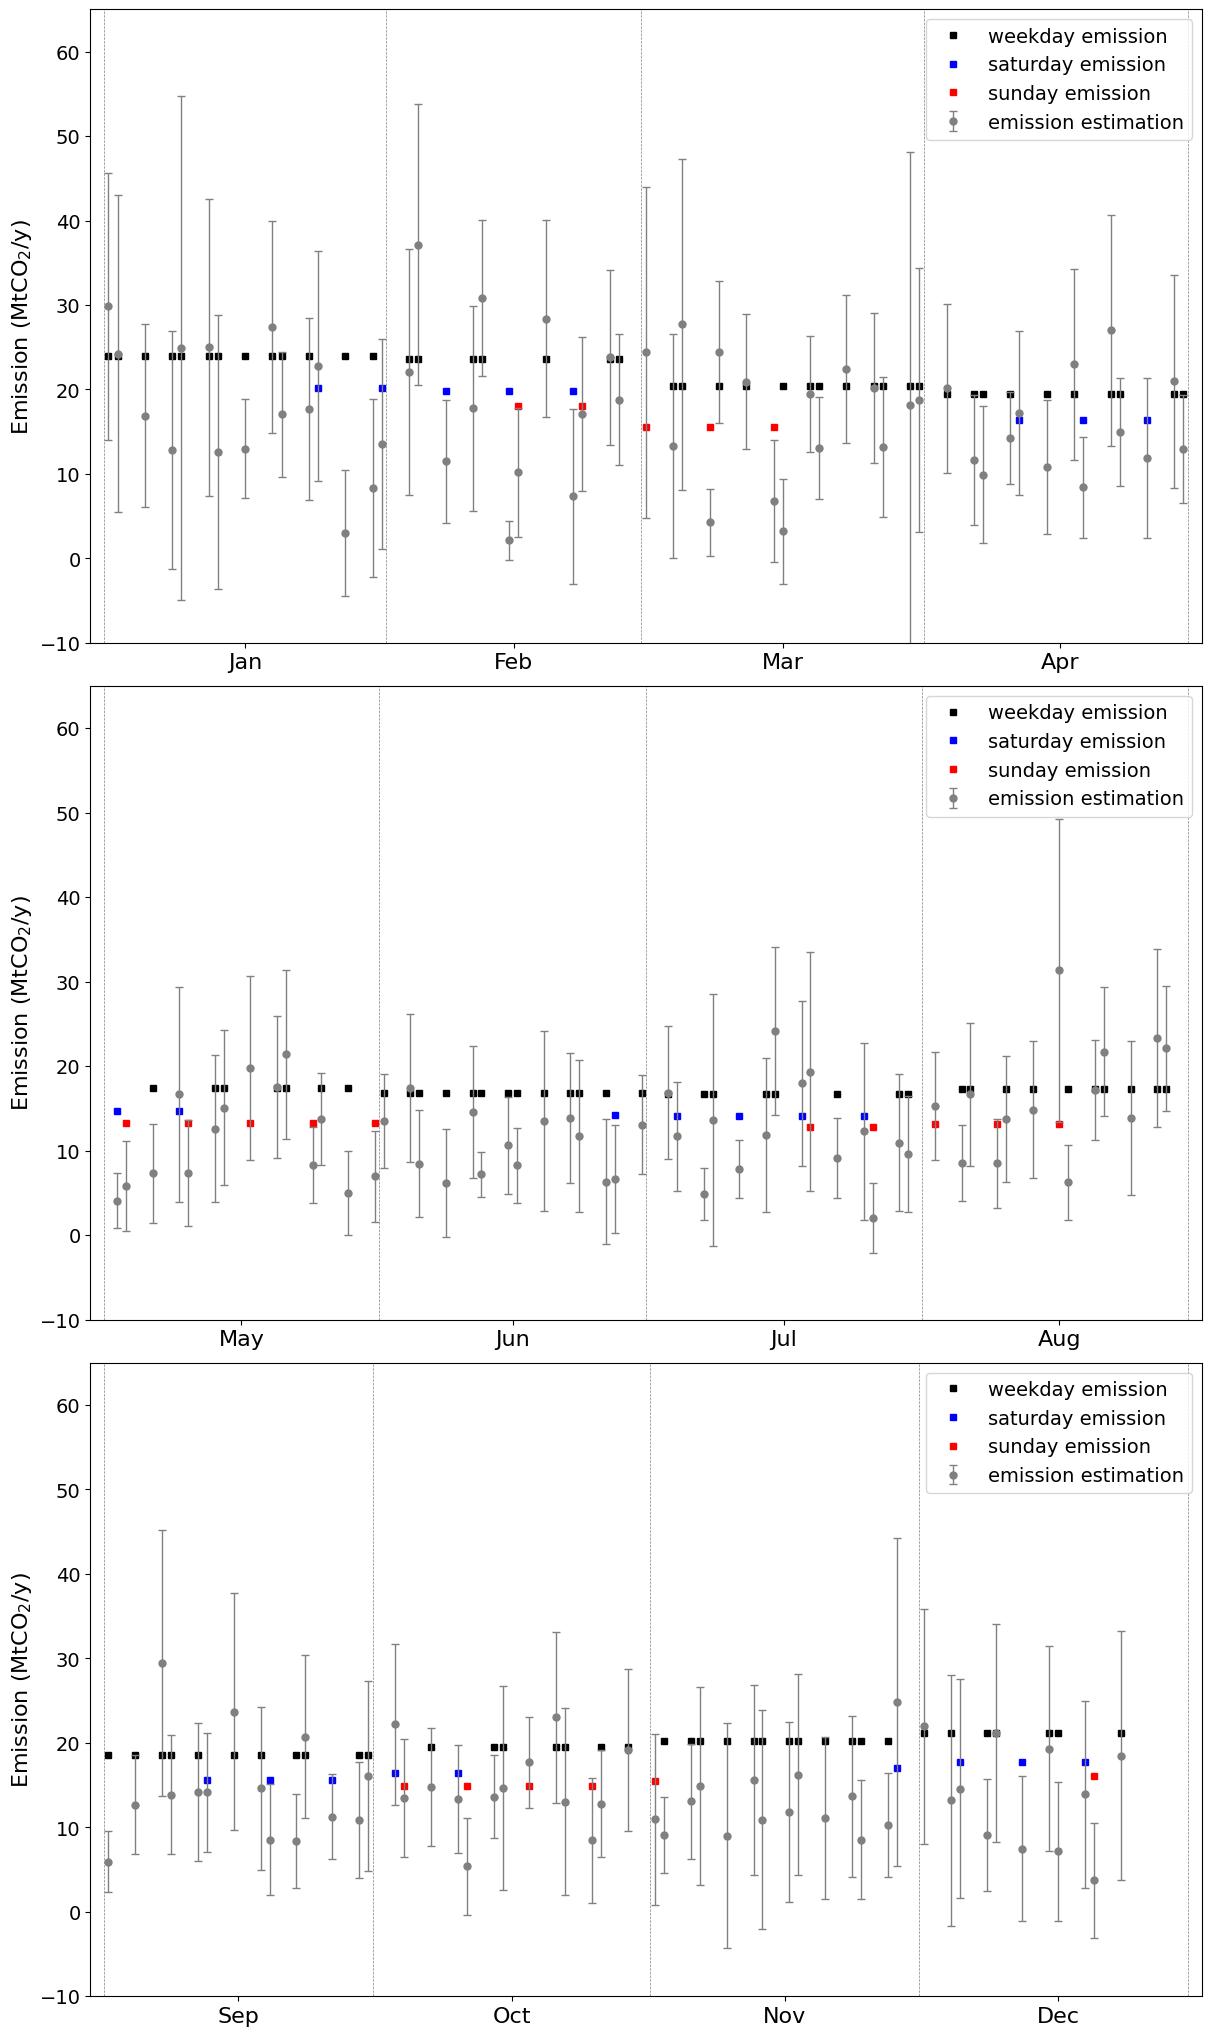

In [61]:
file = 'reported'
emis_est = np.load(f'emis_est_{file}.npy')
emis_std = np.load(f'emis_std_{file}.npy')
messages = np.load(f'messages_{file}.npy')
sources = ddeq.misc.read_point_sources()
remove_sources = ['Belchatow','Berlin','Lipetsk','Matimba','Paris','Hamburg','Prague']
bool_array = [source not in remove_sources for source in sources['source'].data]
sources = sources.where(xr.DataArray(bool_array, dims='source'), drop=True)
source_names = sources['source'].data
MISSVAL = np.nan
est_xr = xr.DataArray(data=emis_est,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission by image', 
                             'Missing Value': MISSVAL})
std_xr = xr.DataArray(data=emis_std,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission Error by image', 
                             'Missing Value': MISSVAL})
msg_xr = xr.DataArray(data=messages,dims=['source','image'],
                      coords=dict(source=source_names,image=images),
                      attrs={'units': 'Mt/yr',
                             'Description': 'Estimated Emission Error by image', 
                             'Missing Value': MISSVAL})


# CHOOSE SOURCE INDEX HERE
index = 5
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
image_dates = pd.to_datetime(list(map(lambda s: s.split('_')[3], est_xr['image'].data)), 
                             format='%Y%m%d%H')
full_CO2_emissions = pd.read_csv(f'{cwd}/src/ddeq/data/SMARTCARB-CO2-emissions.csv',sep='\t',index_col=0)
# Remove units from column names
full_CO2_emissions.rename(columns=lambda s: re.sub(' +',' ',re.sub(r"\(.*?\)"," ",s)).strip(), inplace=True)

# Plotting
fig,(ax_beginning,ax_middle,ax_ending) = plt.subplots(nrows=3,ncols=1,figsize=(12,20.25),layout='compressed')
axs = [ax_beginning,ax_middle,ax_ending]
day_limits = [(datetime(2015,1,1,0,0,0),datetime(2015,4,30,0,0,0)),
              (datetime(2015,5,1,0,0,0),datetime(2015,8,31,0,0,0)),
              (datetime(2015,9,1,0,0,0), datetime(2015,12,31,0,0,0))]
for n in range(len(axs)):
    ax = axs[n]
    starting_day, ending_day = day_limits[n]
    date_mask = (starting_day <= image_dates) & (image_dates <= ending_day)
    emis_per_source = est_xr.loc[dict(source=source_names[index],image=date_mask)]
    err_per_source = std_xr.loc[dict(source=source_names[index],image=date_mask)]
    non_nan = ~np.isnan(emis_per_source.data)
    non_nan_dates = pd.to_datetime(list(map(lambda s: s.split('_')[3], emis_per_source['image'].data[non_nan])), 
                                   format='%Y%m%d%H')
    
    date_range = pd.date_range(starting_day,ending_day)
    emissions = pd.Series(data=np.full(len(date_range),np.nan), index=date_range)
    emissions.loc[non_nan_dates.date] = full_CO2_emissions[source_names[index]].loc[list(map(str,non_nan_dates))].values
    month = date_range.month
    unique_months, days_per_month = np.unique(month,return_counts=True)

    weekdays = date_range.weekday
    saturday_bool = (weekdays == 5)
    sunday_bool = (weekdays == 6)
    weekday_bool = ~saturday_bool & ~sunday_bool

    indices = np.arange(0,len(emissions),dtype=np.uint32)
    ax.plot(indices[weekday_bool],emissions.values[weekday_bool],'ks',
            markersize=5.0,label='weekday emission')
    ax.plot(indices[saturday_bool],emissions.values[saturday_bool],'bs',
            markersize=5.0,label='saturday emission')
    ax.plot(indices[sunday_bool],emissions.values[sunday_bool],'rs',
            markersize=5.0,label='sunday emission')

    ax.axvline(x=-starting_day.day+0.5,linestyle='--',color='gray',linewidth=0.5)
    ax.axvline(x=indices[-1]+days_per_month[ending_day.month-starting_day.month]-ending_day.day-0.5,
               linestyle='--',color='gray',linewidth=0.5)
    xtick_locs, xtick_labels = [], []
    current_month_number = starting_day.month
    for n in range(len(month)):
        if month[n] == current_month_number + 1:
            ax.axvline(x=n-0.5,linestyle='--',color='gray',linewidth=0.5)
            current_month_number += 1
        elif days_per_month[current_month_number-starting_day.month] % 2 == 0 and n == sum(days_per_month[:current_month_number-starting_day.month]) + days_per_month[current_month_number-starting_day.month] // 2:
            xtick_locs.append(n-0.5)
            xtick_labels.append(months[current_month_number-1][:3])
        elif days_per_month[current_month_number-starting_day.month] % 2 != 0 and n == sum(days_per_month[:current_month_number-starting_day.month]) + (days_per_month[current_month_number-starting_day.month]-1) // 2:
            xtick_locs.append(n)
            xtick_labels.append(months[current_month_number-1][:3])
    #ax.axvline(x=len(emissions)-0.5,linestyle='--',color='gray',linewidth=0.5)
    ax.yaxis.set_tick_params(labelsize=14)
    ax.set_ylabel('Emission (MtCO$_2$/y)',fontsize=16)
    ax.xaxis.set_tick_params(labelsize=14)
    ax.set_xticks(xtick_locs,labels=xtick_labels,fontsize=16)
    non_nan_indices = (non_nan_dates - starting_day).days
    ax.errorbar(non_nan_indices,emis_per_source.data[non_nan],yerr=1.0*err_per_source[non_nan],
                color='gray',capsize=3.0,fmt='.',markersize=10.0,linewidth=1.0,label='emission estimation')
    # Limits and legend
    ax.set_xlim(-2.0,len(emissions))
    ax.set_ylim(-10.0,65.0)
    ax.legend(loc='upper right',fontsize=14)
plt.savefig(f'figures/{source_names[index]}_timeseries.pdf',dpi=300)
plt.show()

In [ ]:
# ♪♪ This is the end, beautiful friend, this is the end, my only friend, the end ♪♪